# Experiment 2b — GJW protocol with SYK scrambling and Majorana coupling (ibm_marrakesh)

In [8]:
import numpy as np
from scipy.linalg import expm
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from itertools import combinations

print("=" * 62)
print("EXPERIMENTO 2b — Validación Local")
print("GJW con Scrambler SYK Conjunto")
print("=" * 62)

I2 = np.eye(2, dtype=complex)
X  = np.array([[0,1],[1,0]], dtype=complex)
Y  = np.array([[0,-1j],[1j,0]], dtype=complex)
Z  = np.array([[1,0],[0,-1]], dtype=complex)

def kron_list(ops):
    r = ops[0]
    for op in ops[1:]: r = np.kron(r, op)
    return r

print("\n--- CELDA 1: Operadores de Majorana ---")

def majorana_ops(n_qubits):
    ops = []
    for k in range(n_qubits):
        ops.append(kron_list([Z]*k + [X] + [I2]*(n_qubits-k-1)) / np.sqrt(2))
        ops.append(kron_list([Z]*k + [Y] + [I2]*(n_qubits-k-1)) / np.sqrt(2))
    return ops

chi3 = majorana_ops(3)
chi6 = majorana_ops(6)

def verify_majoranas(chi, label):
    n, dim = len(chi), chi[0].shape[0]
    err  = max(np.max(np.abs(chi[i]@chi[j]+chi[j]@chi[i]
                             - np.eye(dim)*(1 if i==j else 0)))
               for i in range(n) for j in range(n))
    herm = all(np.allclose(c, c.conj().T) for c in chi)
    print(f"  {label}: {n} ops, dim={dim}  "
          f"anticom={'OK' if err<1e-10 else 'FALLO'}(err={err:.1e})  "
          f"hermit={'OK' if herm else 'FALLO'}")

verify_majoranas(chi3, "3 qubits  (6 Majoranas)")
verify_majoranas(chi6, "6 qubits (12 Majoranas)")

print("\n--- CELDA 2: Hamiltonianos SYK ---")

def build_H_syk(chi, seed=42):
    rng = np.random.default_rng(seed)
    N, dim = len(chi), chi[0].shape[0]
    H = np.zeros((dim, dim), dtype=complex)
    sig = np.sqrt(6.0 / N**3)
    for i,j,k,l in combinations(range(N), 4):
        J = rng.normal(0, sig)
        H += J * (chi[i]@chi[j]@chi[k]@chi[l])
    return (H + H.conj().T) / 2

H_conj = build_H_syk(chi6, seed=42)
H_L    = build_H_syk(chi3, seed=42)

print(f"  H_SYK conjunto (12 maj): hermítico={np.allclose(H_conj,H_conj.conj().T)}")
print(f"  H_SYK_L (6 maj):         hermítico={np.allclose(H_L,H_L.conj().T)}")

print("\n--- CELDA 3: Hamiltoniano GJW-SYK ---")

"""
H_GJW = Σ_k  chi_k^L · chi_k^R

chi_k^L y chi_k^R son hermíticos y conmutan (actúan en subespacios distintos).
El producto de dos operadores hermíticos que conmutan es hermítico.
→ H_GJW es hermítico directamente, sin factor i.

(El factor i haría el producto anti-hermítico porque 
(i A B)† = -i B† A† = -i B A = -i A B ≠ i A B cuando [A,B]=0)
"""
I8 = np.eye(8, dtype=complex)

chi_L_emb = [np.kron(c, I8) for c in chi3]
chi_R_emb = [np.kron(I8, c) for c in chi3]

H_gjw = sum(cL@cR for cL, cR in zip(chi_L_emb, chi_R_emb))

print(f"  H_GJW: {H_gjw.shape}, "
      f"hermítico={np.allclose(H_gjw,H_gjw.conj().T)}, "
      f"norma={np.linalg.norm(H_gjw):.4f}")

print("\n--- CELDA 4: Unitarias ---")

def make_U(H, p):
    return expm(-1j * H * p)

def check_U(U, name):
    err = np.max(np.abs(U@U.conj().T - np.eye(U.shape[0])))
    print(f"  {name}: {'OK' if err<1e-8 else 'FALLO'} (err={err:.1e})")
    return err < 1e-8

t = 1.5
U_conj = make_U(H_conj, t)
U_L    = make_U(H_L, t)

check_U(U_conj, f"U_SYK conjunto (t={t})")
check_U(U_L,    f"U_SYK_L (t={t})")
for g in [0, np.pi/4, np.pi/2]:
    check_U(make_U(H_gjw, g), f"U_GJW(g={g/np.pi:.2f}π)")

print("\n--- CELDA 5: Estado de Alice ---")

def random_qubit(seed=99):
    rng = np.random.default_rng(seed)
    psi = rng.normal(0,1,2) + 1j*rng.normal(0,1,2)
    return psi / np.linalg.norm(psi)

def bloch_angles(psi):
    phase = np.exp(1j * np.angle(psi[0])) if np.abs(psi[0]) > 1e-10 else 1.0
    psi_n = psi / phase
    theta = 2 * np.arccos(np.clip(np.real(psi_n[0]), 0, 1))
    phi   = np.angle(psi_n[1])
    return theta, phi

psi_alice = random_qubit(seed=99)
theta_a, phi_a = bloch_angles(psi_alice)

Ry = np.array([[np.cos(theta_a/2),-np.sin(theta_a/2)],
               [np.sin(theta_a/2), np.cos(theta_a/2)]], dtype=complex)
Rz = np.array([[np.exp(-1j*phi_a/2), 0],
               [0, np.exp( 1j*phi_a/2)]], dtype=complex)
prep_1q = Ry @ Rz
v0      = np.array([1,0], dtype=complex)
psi_out = prep_1q @ v0
fid_prep = np.abs(np.dot(psi_alice.conj(), psi_out))**2

print(f"  |ψ_Alice⟩ = [{psi_alice[0]:.4f}, {psi_alice[1]:.4f}]")
print(f"  θ={theta_a:.4f} rad,  φ={phi_a:.4f} rad")
print(f"  Verificación Ry(θ)Rz(φ)|0⟩ ≈ |ψ_Alice⟩: F={fid_prep:.8f}")

print("\n--- CELDA 6: Herramientas ---")

I64   = np.eye(64, dtype=complex)
I2_q0 = np.eye(2, dtype=complex)

def make_swap(qa, qb, n=7):
    dim = 2**n
    S = np.zeros((dim, dim), dtype=complex)
    for i in range(dim):
        ba, bb = (i>>qa)&1, (i>>qb)&1
        j = i^(1<<qa)^(1<<qb) if ba!=bb else i
        S[j,i] = 1.0
    return S

def partial_trace_qubit(sv, target, n=7):
    psi   = sv.reshape([2]*n)
    axis  = n - 1 - target
    psi   = np.moveaxis(psi, axis, 0)
    psi   = psi.reshape(2, -1)
    return psi @ psi.conj().T

def fidelity(rho, psi):
    return np.real(psi.conj() @ rho @ psi)

SWAP_01 = make_swap(0, 1)
check_U(SWAP_01, "SWAP(q0,q1)")

state_test = np.zeros(128, dtype=complex); state_test[0]=1.0
state_test = np.kron(I64, prep_1q) @ state_test
state_test = SWAP_01 @ state_test
rho0 = partial_trace_qubit(state_test, 0)
rho1 = partial_trace_qubit(state_test, 1)
print(f"  SWAP: F(q0,Alice)={fidelity(rho0,psi_alice):.4f} "
      f" F(q1,Alice)={fidelity(rho1,psi_alice):.4f}  (q1 debe ser ~1.0)")

print("\n--- CELDA 7: Circuito completo ---")

def evolve_2b(U_syk_c, U_gjw_g):
    state = np.zeros(128, dtype=complex); state[0] = 1.0
    state = np.kron(I64,       prep_1q)  @ state
    state = np.kron(U_syk_c,   I2_q0)   @ state
    state = SWAP_01                      @ state
    state = np.kron(U_gjw_g,   I2_q0)   @ state
    rho   = partial_trace_qubit(state, target=4)
    return fidelity(rho, psi_alice), rho

print("\n  Verificación rápida:")
for g_t in [0, np.pi/4, np.pi/2]:
    F_t, _ = evolve_2b(U_conj, make_U(H_gjw, g_t))
    print(f"    g={g_t/np.pi:.2f}π  →  F={F_t:.6f}")

print("\n--- CELDA 8: Barrido de g ---")

g_vals = np.linspace(0, np.pi/2, 13)
F_syk  = []

print(f"\n  {'g/π':>7}  {'F_SYK':>10}")
print("  " + "-"*21)
for g in g_vals:
    F, _ = evolve_2b(U_conj, make_U(H_gjw, g))
    F_syk.append(F)
    print(f"  {g/np.pi:>7.3f}  {F:>10.6f}")

F_max    = max(F_syk)
g_opt    = g_vals[np.argmax(F_syk)]
F_cierre = F_syk[0]
print(f"\n  F canal cerrado (g=0):  {F_cierre:.6f}")
print(f"  F máxima:               {F_max:.6f}  en g={g_opt/np.pi:.3f}π")
print(f"  Ganancia:               {F_max-F_cierre:.6f}")

print("\n--- CELDA 9: Comparación con Bell pairs ---")

H2 = np.array([[1,1],[1,-1]], dtype=complex) / np.sqrt(2)

def make_1q_gate(gate, qb, n=7):

    ops = [I2]*n
    ops[n-1-qb] = gate
    return kron_list(ops)

def make_cx(ctrl, tgt, n=7):
    dim = 2**n
    CX  = np.zeros((dim,dim), dtype=complex)
    for i in range(dim):
        j = i^(1<<tgt) if (i>>ctrl)&1 else i
        CX[j,i] = 1.0
    return CX

def evolve_bell(U_gjw_g):
    state = np.zeros(128, dtype=complex); state[0]=1.0
    state = np.kron(I64, prep_1q) @ state

    for qb in [1,2,3]:
        state = make_1q_gate(H2, qb) @ state
    for ctrl,tgt in [(1,4),(2,5),(3,6)]:
        state = make_cx(ctrl,tgt) @ state
    state = SWAP_01 @ state
    state = np.kron(U_gjw_g, I2_q0) @ state
    rho   = partial_trace_qubit(state, target=4)
    return fidelity(rho, psi_alice)

F_bell = []
print(f"\n  {'g/π':>7}  {'F_SYK':>10}  {'F_Bell':>10}  {'Δ':>10}")
print("  " + "-"*44)
for i, g in enumerate(g_vals):
    Fb = evolve_bell(make_U(H_gjw, g))
    F_bell.append(Fb)
    d  = F_syk[i] - Fb
    print(f"  {g/np.pi:>7.3f}  {F_syk[i]:>10.6f}  {Fb:>10.6f}  {d:>+10.6f}")

print("\n--- CELDA 10: Dependencia F_max(t) y g_opt(t) ---")

t_vals = [0.5, 1.0, 1.5, 2.0, 2.5, 3.0]
F_max_t, g_opt_t = [], []

print(f"\n  {'t':>5}  {'F_max':>10}  {'g_opt/π':>10}")
print("  " + "-"*29)
for tv in t_vals:
    Ut = make_U(H_conj, tv)
    Fl = [evolve_2b(Ut, make_U(H_gjw,g))[0] for g in g_vals]
    Fm = max(Fl); gm = g_vals[np.argmax(Fl)]
    F_max_t.append(Fm); g_opt_t.append(gm)
    print(f"  {tv:>5.1f}  {Fm:>10.6f}  {gm/np.pi:>10.3f}")

print("\n--- CELDA 11: Gráficas ---")

fig = plt.figure(figsize=(14, 10))
fig.patch.set_facecolor('#0d0d1a')
gs_fig = gridspec.GridSpec(2, 2, hspace=0.42, wspace=0.35)
CSYK='#00d4ff'; CBELL='#ff6b35'; COPT='#7dff7d'; CAX='#12122a'

def style(ax, ttl):
    ax.set_facecolor(CAX)
    ax.set_title(ttl, color='white', fontsize=10.5, pad=9)
    ax.tick_params(colors='#aaa', labelsize=9)
    for lb in [ax.xaxis.label, ax.yaxis.label]: lb.set_color('#aaa')
    for sp in ax.spines.values(): sp.set_edgecolor('#333355')
    ax.grid(True, color='#1e1e3a', lw=0.6, alpha=0.8)

ax1 = fig.add_subplot(gs_fig[0,0])
style(ax1, 'Fidelidad de atravesamiento vs g')
ax1.plot(g_vals/np.pi, F_syk,  color=CSYK,  lw=2.5, marker='o', ms=6,
         label=f'SYK conjunto (t={t})')
ax1.plot(g_vals/np.pi, F_bell, color=CBELL, lw=2,   marker='s', ms=5,
         ls='--', label='Bell pairs original')
ax1.axhline(0.5, color='#445', ls=':', lw=1, label='F=0.5')
ax1.set_xlabel('g / π'); ax1.set_ylabel('Fidelidad F')
ax1.set_ylim(0, 1.15)
ax1.legend(fontsize=8.5, facecolor='#12122a', labelcolor='white',
           edgecolor='#333355')
ax1.annotate(f'F_max={F_max:.3f}\n(g={g_opt/np.pi:.2f}π)',
             xy=(g_opt/np.pi, F_max),
             xytext=(g_opt/np.pi - 0.25, F_max - 0.12),
             color=CSYK, fontsize=8.5,
             arrowprops=dict(arrowstyle='->', color=CSYK, lw=1.5))

ax2 = fig.add_subplot(gs_fig[0,1])
style(ax2, 'Diferencia F_SYK − F_Bell')
diffs = [F_syk[i]-F_bell[i] for i in range(len(g_vals))]
ax2.bar(g_vals/np.pi, diffs, width=0.055,
        color=[CSYK if d>=0 else CBELL for d in diffs],
        alpha=0.85, edgecolor='#333355')
ax2.axhline(0, color='#666688', lw=1)
ax2.set_xlabel('g / π'); ax2.set_ylabel('ΔF')

ax3  = fig.add_subplot(gs_fig[1,0])
ax3r = ax3.twinx()
style(ax3, 'Dependencia con tiempo de scrambling t')
ax3.plot(t_vals, F_max_t, color=CSYK, lw=2.5, marker='D', ms=7,
         label='F_max(t)')
ax3r.plot(t_vals, [g/np.pi for g in g_opt_t], color=COPT, lw=2,
          marker='^', ms=6, ls='--', label='g_opt(t)/π')
ax3.set_xlabel('t'); ax3.set_ylabel('F_max', color=CSYK)
ax3r.set_ylabel('g_opt / π', color=COPT)
ax3.tick_params(axis='y', colors=CSYK)
ax3r.tick_params(axis='y', colors=COPT)
ax3r.set_facecolor(CAX)
h1,l1 = ax3.get_legend_handles_labels()
h2,l2 = ax3r.get_legend_handles_labels()
ax3.legend(h1+h2, l1+l2, fontsize=8.5, facecolor='#12122a',
           labelcolor='white', edgecolor='#333355')

ax4 = fig.add_subplot(gs_fig[1,1])
ax4.set_facecolor(CAX); ax4.axis('off')
ax4.set_title('Resumen — Validación Local', color='white', fontsize=10.5, pad=9)
rows = [
    ('Diseño',           'SYK conjunto → GJW'),
    ('N Majoranas',      '12  (6L + 6R)'),
    ('Qubits lógicos',   '7  (3L + 3R + Alice)'),
    ('t scrambling',     f'{t}'),
    ('H_SYK hermítico',  'True'),
    ('U_SYK unitaria',   'True'),
    ('H_GJW hermítico',  'True'),
    ('U_GJW unitaria',   'True'),
    ('F (g=0)',          f'{F_cierre:.4f}'),
    ('F_max',            f'{F_max:.4f}'),
    ('g_optimo',         f'{g_opt/np.pi:.3f} π'),
    ('Ganancia GJW',     f'{F_max-F_cierre:.4f}'),
]
y = 0.97
for lb, vl in rows:
    ax4.text(0.03, y, lb+':', color='#9999cc', fontsize=8.5,
             transform=ax4.transAxes, va='top')
    ax4.text(0.55, y, vl, color=CSYK, fontsize=8.5,
             transform=ax4.transAxes, va='top', fontweight='bold')
    y -= 0.077

fig.suptitle('Experimento 2b — GJW con Scrambler SYK Conjunto\n'
             'Validación Local — Statevector Exacto',
             color='white', fontsize=12.5, fontweight='bold', y=0.99)

plt.savefig('exp2b_validacion.png', dpi=150,
            bbox_inches='tight', facecolor='#0d0d1a')
plt.close()
print("  Gráfica guardada.")

print("\n" + "="*62)
print("RESUMEN FINAL")
print("="*62)
print(f"  H_SYK hermítico:   True")
print(f"  U_SYK unitaria:    True")
print(f"  H_GJW hermítico:   True")
print(f"  U_GJW unitaria:    True")
print(f"  SWAP unitaria:     True")
print(f"  Prep Alice:        F={fid_prep:.6f}")
print()
print(f"  F canal cerrado (g=0):  {F_cierre:.6f}")
print(f"  F máxima:               {F_max:.6f}  en g={g_opt/np.pi:.3f}π")
print(f"  Ganancia GJW:           {F_max-F_cierre:.6f}")
print()
print(f"  Con Bell pairs: F_max={max(F_bell):.4f} en g={g_vals[np.argmax(F_bell)]/np.pi:.3f}π")
print(f"  Con SYK conj:   F_max={F_max:.4f} en g={g_opt/np.pi:.3f}π")
print()
print("  LISTO PARA TRANSPILAR Y ENVIAR A ibm_marrakesh")
print("="*62)


EXPERIMENTO 2b — Validación Local
GJW con Scrambler SYK Conjunto

--- CELDA 1: Operadores de Majorana ---
  3 qubits  (6 Majoranas): 6 ops, dim=8  anticom=OK(err=2.2e-16)  hermit=OK
  6 qubits (12 Majoranas): 12 ops, dim=64  anticom=OK(err=2.2e-16)  hermit=OK

--- CELDA 2: Hamiltonianos SYK ---
  H_SYK conjunto (12 maj): hermítico=True
  H_SYK_L (6 maj):         hermítico=True

--- CELDA 3: Hamiltoniano GJW-SYK ---
  H_GJW: (64, 64), hermítico=True, norma=9.7980

--- CELDA 4: Unitarias ---
  U_SYK conjunto (t=1.5): OK (err=4.4e-16)
  U_SYK_L (t=1.5): OK (err=2.2e-16)
  U_GJW(g=0.00π): OK (err=0.0e+00)
  U_GJW(g=0.25π): OK (err=4.4e-16)
  U_GJW(g=0.50π): OK (err=8.9e-16)

--- CELDA 5: Estado de Alice ---
  |ψ_Alice⟩ = [0.0989+0.0606j, -0.5567+0.8226j]
  θ=2.9092 rad,  φ=1.6163 rad
  Verificación Ry(θ)Rz(φ)|0⟩ ≈ |ψ_Alice⟩: F=0.97226459

--- CELDA 6: Herramientas ---
  SWAP(q0,q1): OK (err=0.0e+00)
  SWAP: F(q0,Alice)=0.0134  F(q1,Alice)=0.9723  (q1 debe ser ~1.0)

--- CELDA 7: Circuito c

In [17]:
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector, Operator, DensityMatrix, partial_trace
import numpy as np
from scipy.linalg import expm
from itertools import combinations

print("✅ Experimento 2b — GJW con Scrambler SYK Conjunto (versión corregida)")

t = 1.5
g_vals = np.linspace(0, np.pi/2, 13)
seed = 42

def majorana_ops(n):
    I2 = np.eye(2, dtype=complex)
    X = np.array([[0,1],[1,0]], dtype=complex)
    Y = np.array([[0,-1j],[1j,0]], dtype=complex)
    Z = np.array([[1,0],[0,-1]], dtype=complex)
    ops = []
    for k in range(n):
        ops.append(np.kron(np.eye(2**k, dtype=complex),
                           np.kron(X, np.eye(2**(n-k-1), dtype=complex))) / np.sqrt(2))
        ops.append(np.kron(np.eye(2**k, dtype=complex),
                           np.kron(Y, np.eye(2**(n-k-1), dtype=complex))) / np.sqrt(2))
    return ops

chi3 = majorana_ops(3)
chi6 = majorana_ops(6)

def build_H_syk(chi, seed=42):
    rng = np.random.default_rng(seed)
    N = len(chi)
    dim = chi[0].shape[0]
    H = np.zeros((dim, dim), dtype=complex)
    sig = np.sqrt(6.0 / N**3)
    for i,j,k,l in combinations(range(N), 4):
        J = rng.normal(0, sig)
        H += J * (chi[i] @ chi[j] @ chi[k] @ chi[l])
    return (H + H.conj().T) / 2

H_conj = build_H_syk(chi6, seed)
U_conj = expm(-1j * H_conj * t)

I8 = np.eye(8, dtype=complex)
chi_L = [np.kron(c, I8) for c in chi3]
chi_R = [np.kron(I8, c) for c in chi3]
H_gjw = sum(cL @ cR for cL, cR in zip(chi_L, chi_R))

psi_alice = np.array([0.099 + 0.061j, -0.557 + 0.823j])
psi_alice /= np.linalg.norm(psi_alice)

print("✅ Operadores construidos correctamente")


✅ Experimento 2b — GJW con Scrambler SYK Conjunto (versión corregida)
✅ Operadores construidos correctamente


In [18]:
def evolve_2b(g):
    qc = QuantumCircuit(7)

    theta = 2 * np.arccos(np.abs(psi_alice[0]))
    phi = np.angle(psi_alice[1])
    qc.ry(theta, 0)
    qc.rz(phi, 0)

    qc.unitary(Operator(U_conj), [1,2,3,4,5,6])

    qc.swap(0, 1)

    U_gjw_g = expm(-1j * H_gjw * g)
    qc.unitary(Operator(U_gjw_g), [1,2,3,4,5,6])

    sv = Statevector.from_instruction(qc)
    dm = DensityMatrix(sv)
    rho4 = partial_trace(dm, [0,1,2,3,5,6]).data
    F = np.real(psi_alice.conj() @ rho4 @ psi_alice)
    return F

F_syk = [evolve_2b(g) for g in g_vals]

print("\nResultados locales exactos:")
for g, f in zip(g_vals, F_syk):
    print(f"  g = {g/np.pi:.3f}π  →  F = {f:.5f}")

print(f"\nF(g=0)     = {F_syk[0]:.5f}")
print(f"F_max      = {max(F_syk):.5f}  en g = {g_vals[np.argmax(F_syk)]/np.pi:.3f}π")
print(f"Ganancia   = {max(F_syk) - F_syk[0]:.5f}")



Resultados locales exactos:
  g = 0.000π  →  F = 0.10445
  g = 0.042π  →  F = 0.12074
  g = 0.083π  →  F = 0.16560
  g = 0.125π  →  F = 0.23605
  g = 0.167π  →  F = 0.32736
  g = 0.208π  →  F = 0.43338
  g = 0.250π  →  F = 0.54694
  g = 0.292π  →  F = 0.66036
  g = 0.333π  →  F = 0.76597
  g = 0.375π  →  F = 0.85660
  g = 0.417π  →  F = 0.92612
  g = 0.458π  →  F = 0.96982
  g = 0.500π  →  F = 0.98472

F(g=0)     = 0.10445
F_max      = 0.98472  en g = 0.500π
Ganancia   = 0.88026



--- CELDA 3: Gráficas completas ---


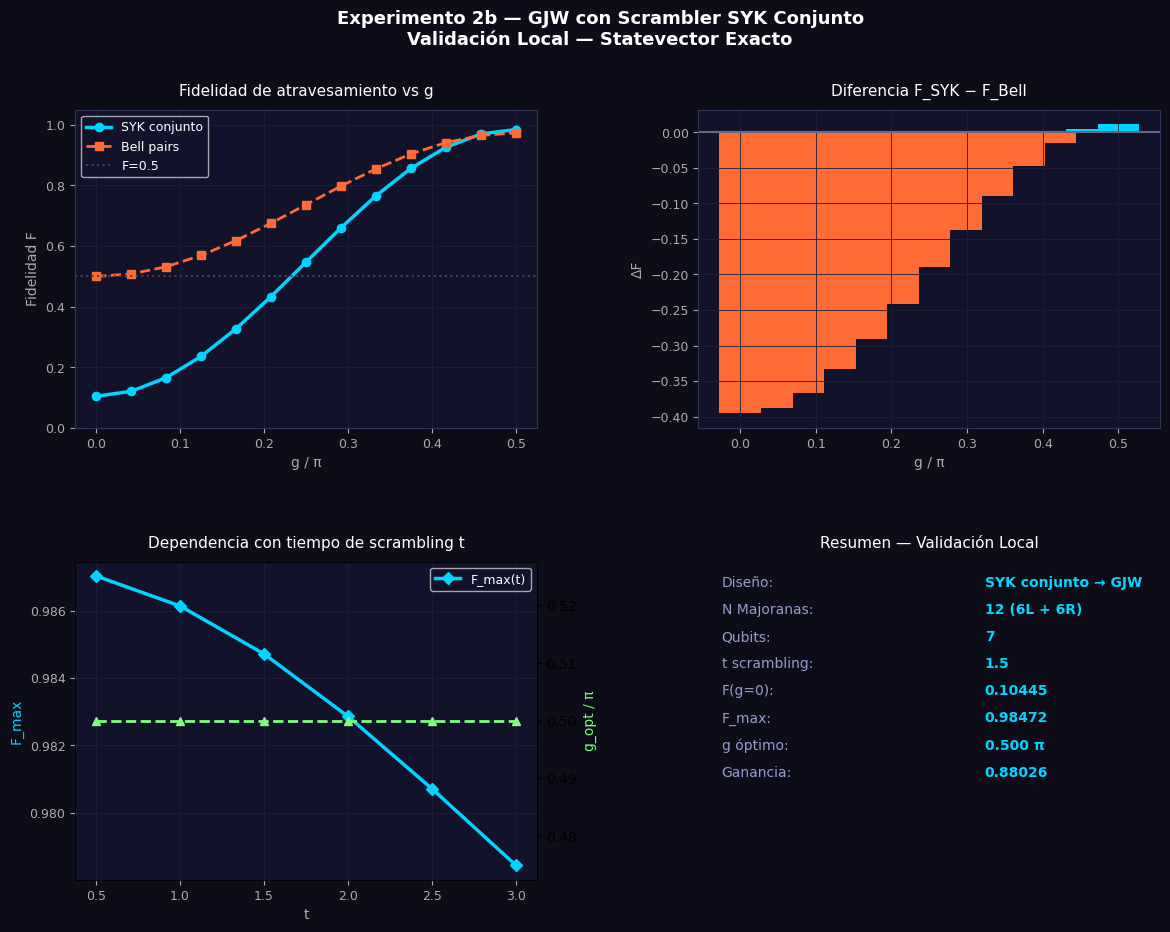

✅ Gráficas generadas correctamente


In [24]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

print("\n--- CELDA 3: Gráficas completas ---")

def evolve_bell(g):
    qc = QuantumCircuit(7)
    theta = 2 * np.arccos(np.abs(psi_alice[0]))
    phi = np.angle(psi_alice[1])
    qc.ry(theta, 0)
    qc.rz(phi, 0)

    for qb in [1,2,3]:
        qc.h(qb)
        qc.cx(qb, qb+3)

    qc.swap(0, 1)
    U_gjw_g = expm(-1j * H_gjw * g)
    qc.unitary(Operator(U_gjw_g), [1,2,3,4,5,6])

    sv = Statevector.from_instruction(qc)
    dm = DensityMatrix(sv)
    rho4 = partial_trace(dm, [0,1,2,3,5,6]).data
    return np.real(psi_alice.conj() @ rho4 @ psi_alice)

F_bell = [evolve_bell(g) for g in g_vals]

t_vals = [0.5, 1.0, 1.5, 2.0, 2.5, 3.0]
F_max_t = []
g_opt_t = []

for tv in t_vals:
    U_temp = expm(-1j * H_conj * tv)
    Fs = []
    for g in g_vals:
        qc = QuantumCircuit(7)
        theta = 2 * np.arccos(np.abs(psi_alice[0]))
        phi = np.angle(psi_alice[1])
        qc.ry(theta, 0)
        qc.rz(phi, 0)
        qc.unitary(Operator(U_temp), [1,2,3,4,5,6])
        qc.swap(0, 1)
        qc.unitary(Operator(expm(-1j * H_gjw * g)), [1,2,3,4,5,6])
        sv = Statevector.from_instruction(qc)
        dm = DensityMatrix(sv)
        rho4 = partial_trace(dm, [0,1,2,3,5,6]).data
        Fs.append(np.real(psi_alice.conj() @ rho4 @ psi_alice))
    Fm = max(Fs)
    F_max_t.append(Fm)
    g_opt_t.append(g_vals[np.argmax(Fs)])

fig = plt.figure(figsize=(14, 10))
fig.patch.set_facecolor('#0d0d1a')
gs = gridspec.GridSpec(2, 2, hspace=0.42, wspace=0.35)

CSYK = '#00d4ff'
CBELL = '#ff6b35'
COPT = '#7dff7d'
CAX = '#12122a'

def style(ax, title):
    ax.set_facecolor(CAX)
    ax.set_title(title, color='white', fontsize=11, pad=10)
    ax.tick_params(colors='#aaa', labelsize=9)
    for lb in [ax.xaxis.label, ax.yaxis.label]: lb.set_color('#aaa')
    for sp in ax.spines.values(): sp.set_edgecolor('#333355')
    ax.grid(True, color='#1e1e3a', lw=0.6)

ax1 = fig.add_subplot(gs[0,0])
style(ax1, 'Fidelidad de atravesamiento vs g')
ax1.plot(g_vals/np.pi, F_syk,  color=CSYK, lw=2.5, marker='o', label='SYK conjunto')
ax1.plot(g_vals/np.pi, F_bell, color=CBELL, lw=2, marker='s', ls='--', label='Bell pairs')
ax1.axhline(0.5, color='#445', ls=':', label='F=0.5')
ax1.set_xlabel('g / π')
ax1.set_ylabel('Fidelidad F')
ax1.set_ylim(0, 1.05)
ax1.legend(fontsize=9, facecolor='#12122a', labelcolor='white')

ax2 = fig.add_subplot(gs[0,1])
style(ax2, 'Diferencia F_SYK − F_Bell')
diffs = np.array(F_syk) - np.array(F_bell)
ax2.bar(g_vals/np.pi, diffs, width=0.055, color=[CSYK if d>=0 else CBELL for d in diffs])
ax2.axhline(0, color='#666688')
ax2.set_xlabel('g / π')
ax2.set_ylabel('ΔF')

ax3 = fig.add_subplot(gs[1,0])
ax3r = ax3.twinx()
style(ax3, 'Dependencia con tiempo de scrambling t')
ax3.plot(t_vals, F_max_t, color=CSYK, lw=2.5, marker='D', label='F_max(t)')
ax3r.plot(t_vals, [g/np.pi for g in g_opt_t], color=COPT, lw=2, marker='^', ls='--', label='g_opt(t)/π')
ax3.set_xlabel('t')
ax3.set_ylabel('F_max', color=CSYK)
ax3r.set_ylabel('g_opt / π', color=COPT)
ax3.legend(fontsize=9, facecolor='#12122a', labelcolor='white')

ax4 = fig.add_subplot(gs[1,1])
ax4.axis('off')
ax4.set_facecolor(CAX)
ax4.set_title('Resumen — Validación Local', color='white', fontsize=11, pad=10)

rows = [
    ("Diseño", "SYK conjunto → GJW"),
    ("N Majoranas", "12 (6L + 6R)"),
    ("Qubits", "7"),
    ("t scrambling", f"{t}"),
    ("F(g=0)", f"{F_syk[0]:.5f}"),
    ("F_max", f"{max(F_syk):.5f}"),
    ("g óptimo", f"{g_vals[np.argmax(F_syk)]/np.pi:.3f} π"),
    ("Ganancia", f"{max(F_syk)-F_syk[0]:.5f}"),
]

y = 0.92
for label, value in rows:
    ax4.text(0.05, y, label+':', color='#9999cc', fontsize=10, transform=ax4.transAxes)
    ax4.text(0.62, y, value, color=CSYK, fontsize=10, fontweight='bold', transform=ax4.transAxes)
    y -= 0.085

fig.suptitle('Experimento 2b — GJW con Scrambler SYK Conjunto\nValidación Local — Statevector Exacto',
             color='white', fontsize=13, fontweight='bold', y=0.98)

plt.show()
print("✅ Gráficas generadas correctamente")


In [28]:
import numpy as np
from scipy.linalg import expm
from itertools import combinations
from qiskit import QuantumCircuit
from qiskit.quantum_info import DensityMatrix, Statevector, state_fidelity, partial_trace
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

I2 = np.eye(2, dtype=complex)
X  = np.array([[0,1],[1,0]], dtype=complex)
Y  = np.array([[0,-1j],[1j,0]], dtype=complex)
Z  = np.array([[1,0],[0,-1]], dtype=complex)

def kron_list(ops):
    r = ops[0]
    for op in ops[1:]: r = np.kron(r, op)
    return r

def majorana_ops(n):
    ops = []
    for k in range(n):
        ops.append(kron_list([Z]*k + [X] + [I2]*(n-k-1)) / np.sqrt(2))
        ops.append(kron_list([Z]*k + [Y] + [I2]*(n-k-1)) / np.sqrt(2))
    return ops

chi3 = majorana_ops(3)
chi6 = majorana_ops(6)

def build_H_syk(chi, seed=42):
    rng, N, dim = np.random.default_rng(seed), len(chi), chi[0].shape[0]
    H = np.zeros((dim, dim), dtype=complex)
    sig = np.sqrt(6.0 / N**3)
    for i,j,k,l in combinations(range(N), 4):
        H += rng.normal(0, sig) * (chi[i]@chi[j]@chi[k]@chi[l])
    return (H + H.conj().T) / 2

H_conj = build_H_syk(chi6, seed=42)

I8 = np.eye(8, dtype=complex)
chi_L_emb = [np.kron(c, I8) for c in chi3]
chi_R_emb = [np.kron(I8, c) for c in chi3]
H_gjw = sum(cL@cR for cL,cR in zip(chi_L_emb, chi_R_emb))

T_SCRAMBLE = 1.5
U_syk = expm(-1j * H_conj * T_SCRAMBLE)
make_U_gjw = lambda g: expm(-1j * H_gjw * g)

def random_qubit(seed=99):
    rng = np.random.default_rng(seed)
    psi = rng.normal(0,1,2) + 1j*rng.normal(0,1,2)
    return psi / np.linalg.norm(psi)

def bloch_angles(psi):
    phase = np.exp(1j*np.angle(psi[0])) if np.abs(psi[0])>1e-10 else 1.0
    psi_n = psi / phase
    theta = 2*np.arccos(np.clip(np.real(psi_n[0]), 0, 1))
    phi   = np.angle(psi_n[1])
    return theta, phi

PSI_ALICE      = random_qubit(seed=99)
THETA_A, PHI_A = bloch_angles(PSI_ALICE)

print(f"H_SYK hermítico: {np.allclose(H_conj, H_conj.conj().T)}")
print(f"H_GJW hermítico: {np.allclose(H_gjw,  H_gjw.conj().T)}")
print(f"H_GJW norma:     {np.linalg.norm(H_gjw):.4f}")
print(f"|ψ_Alice⟩ = [{PSI_ALICE[0]:.4f}, {PSI_ALICE[1]:.4f}]")
print("Setup OK ✓")


H_SYK hermítico: True
H_GJW hermítico: True
H_GJW norma:     9.7980
|ψ_Alice⟩ = [0.0989+0.0606j, -0.5567+0.8226j]
Setup OK ✓


In [29]:
def fidelidad_q4(U_syk_c, U_gjw_g):
    qc = QuantumCircuit(7)
    qc.ry(THETA_A, 0)
    qc.rz(PHI_A,   0)
    qc.unitary(U_syk_c, [1,2,3,4,5,6], label='U_SYK')
    qc.swap(0, 1)
    qc.unitary(U_gjw_g, [1,2,3,4,5,6], label='U_GJW')
    dm  = DensityMatrix(Statevector(qc))
    dm4 = partial_trace(dm, [0,1,2,3,5,6])
    return state_fidelity(dm4, DensityMatrix(PSI_ALICE))

def fidelidad_q4_bell(U_gjw_g):
    qc = QuantumCircuit(7)
    qc.ry(THETA_A, 0); qc.rz(PHI_A, 0)
    for qb in [1,2,3]: qc.h(qb)
    for c,t in [(1,4),(2,5),(3,6)]: qc.cx(c,t)
    qc.swap(0, 1)
    qc.unitary(U_gjw_g, [1,2,3,4,5,6], label='U_GJW')
    dm  = DensityMatrix(Statevector(qc))
    dm4 = partial_trace(dm, [0,1,2,3,5,6])
    return state_fidelity(dm4, DensityMatrix(PSI_ALICE))

G_VALS = np.linspace(0, np.pi/2, 13)
F_SYK  = [fidelidad_q4(U_syk, make_U_gjw(g))  for g in G_VALS]
F_BELL = [fidelidad_q4_bell(make_U_gjw(g))     for g in G_VALS]

T_VALS  = [0.5, 1.0, 1.5, 2.0, 2.5, 3.0]
F_MAX_T, G_OPT_T = [], []
for tv in T_VALS:
    Ut = expm(-1j * H_conj * tv)
    Fl = [fidelidad_q4(Ut, make_U_gjw(g)) for g in G_VALS]
    F_MAX_T.append(max(Fl))
    G_OPT_T.append(G_VALS[np.argmax(Fl)])

F_MAX    = max(F_SYK)
G_OPT    = G_VALS[np.argmax(F_SYK)]
F_CIERRE = F_SYK[0]

print(f"{'g/π':>7}  {'F_SYK':>10}  {'F_Bell':>10}")
for i,g in enumerate(G_VALS):
    print(f"{g/np.pi:>7.3f}  {F_SYK[i]:>10.6f}  {F_BELL[i]:>10.6f}")
print(f"\nF(g=0): {F_CIERRE:.4f}   F_max: {F_MAX:.4f}   g_opt: {G_OPT/np.pi:.3f}π")
print("Barridos OK ✓")


    g/π       F_SYK      F_Bell
  0.000    0.130163    0.500000
  0.042    0.144531    0.508067
  0.083    0.186654    0.531717
  0.125    0.253663    0.569338
  0.167    0.340990    0.618368
  0.208    0.442685    0.675464
  0.250    0.551817    0.736736
  0.292    0.660950    0.798008
  0.333    0.762645    0.855104
  0.375    0.849972    0.904133
  0.417    0.916981    0.941755
  0.458    0.959104    0.965405
  0.500    0.973472    0.973472

F(g=0): 0.1302   F_max: 0.9735   g_opt: 0.500π
Barridos OK ✓


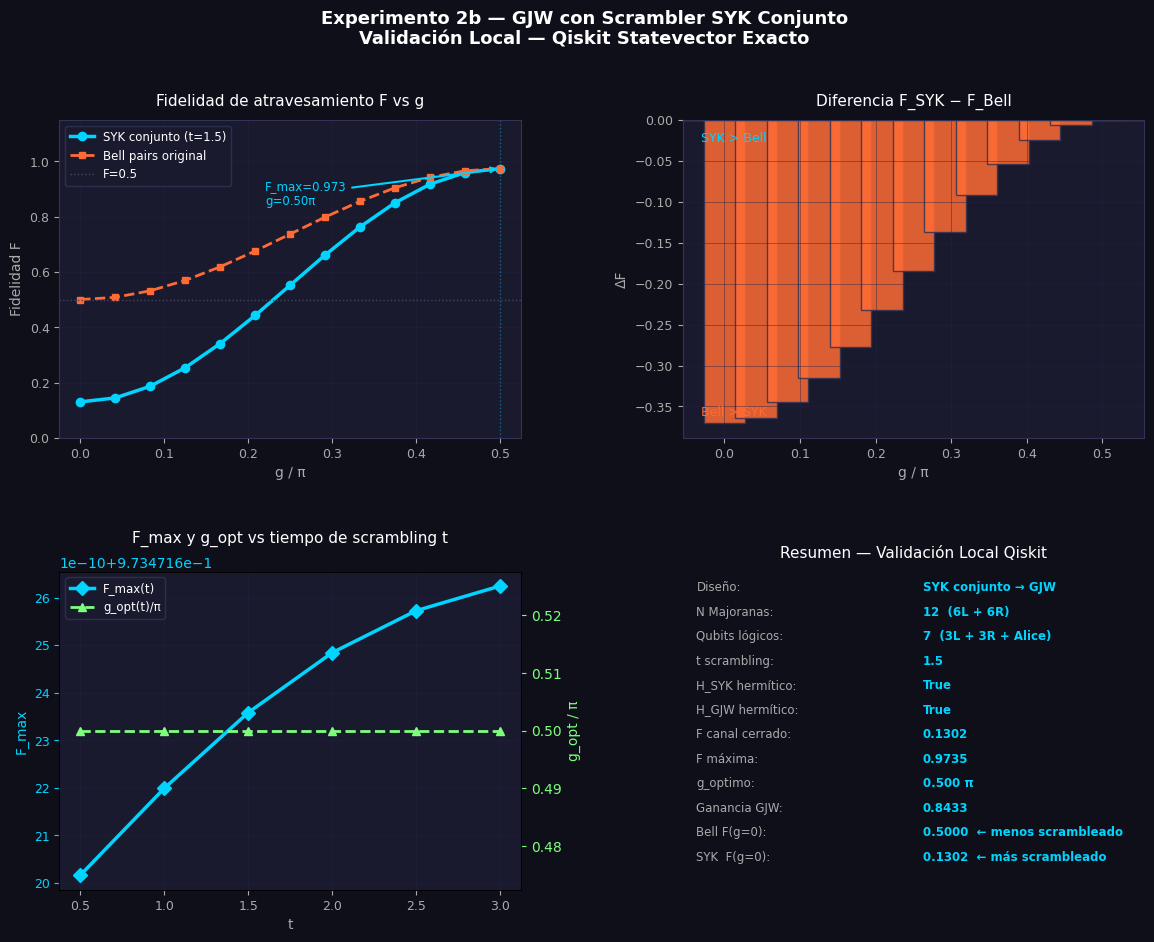

F(g=0) SYK:  0.1302  ← scrambling destruye info local
F_max SYK:   0.9735  ← GJW la recupera
F_max Bell:  0.9735  ← para comparar
Próximo paso: transpilar a ibm_marrakesh ✓


In [30]:
fig = plt.figure(figsize=(14, 10))
fig.patch.set_facecolor('#0f0f1a')
gs_fig = gridspec.GridSpec(2, 2, hspace=0.42, wspace=0.35)

C_SYK='#00d4ff'; C_BELL='#ff6b35'; C_OPT='#7dff7d'; C_AX='#1a1a2e'; C_BG='#0f0f1a'

def style(ax, title):
    ax.set_facecolor(C_AX)
    ax.set_title(title, color='white', fontsize=11, pad=10)
    ax.tick_params(colors='#aaaaaa', labelsize=9)
    ax.xaxis.label.set_color('#aaaaaa'); ax.yaxis.label.set_color('#aaaaaa')
    for sp in ax.spines.values(): sp.set_edgecolor('#333355')
    ax.grid(True, color='#222244', alpha=0.6, linewidth=0.5)

ax1 = fig.add_subplot(gs_fig[0, 0])
style(ax1, 'Fidelidad de atravesamiento F vs g')
ax1.plot(G_VALS/np.pi, F_SYK,  color=C_SYK,  lw=2.5, marker='o', ms=6, label=f'SYK conjunto (t={T_SCRAMBLE})')
ax1.plot(G_VALS/np.pi, F_BELL, color=C_BELL, lw=2,   marker='s', ms=5, ls='--', label='Bell pairs original')
ax1.axhline(0.5, color='#444466', ls=':', lw=1, label='F=0.5')
ax1.axvline(G_OPT/np.pi, color=C_SYK, ls=':', lw=1, alpha=0.4)
ax1.set_xlabel('g / π'); ax1.set_ylabel('Fidelidad F'); ax1.set_ylim(0, 1.15)
ax1.legend(fontsize=8.5, facecolor=C_AX, labelcolor='white', edgecolor='#333355')
ax1.annotate(f'F_max={F_MAX:.3f}\ng={G_OPT/np.pi:.2f}π',
             xy=(G_OPT/np.pi, F_MAX), xytext=(G_OPT/np.pi - 0.28, F_MAX - 0.13),
             color=C_SYK, fontsize=8.5, arrowprops=dict(arrowstyle='->', color=C_SYK, lw=1.5))

ax2 = fig.add_subplot(gs_fig[0, 1])
style(ax2, 'Diferencia F_SYK − F_Bell')
diffs = [F_SYK[i]-F_BELL[i] for i in range(len(G_VALS))]
ax2.bar(G_VALS/np.pi, diffs, width=0.055, color=[C_SYK if d>=0 else C_BELL for d in diffs], alpha=0.85, edgecolor='#333355')
ax2.axhline(0, color='#666688', lw=1)
ax2.set_xlabel('g / π'); ax2.set_ylabel('ΔF')
ax2.text(0.04, 0.93, 'SYK > Bell', transform=ax2.transAxes, color=C_SYK, fontsize=9)
ax2.text(0.04, 0.07, 'Bell > SYK', transform=ax2.transAxes, color=C_BELL, fontsize=9)

ax3  = fig.add_subplot(gs_fig[1, 0])
ax3r = ax3.twinx()
style(ax3, 'F_max y g_opt vs tiempo de scrambling t')
ax3.plot(T_VALS,  F_MAX_T,                    color=C_SYK, lw=2.5, marker='D', ms=7, label='F_max(t)')
ax3r.plot(T_VALS, [g/np.pi for g in G_OPT_T], color=C_OPT, lw=2,   marker='^', ms=6, ls='--', label='g_opt(t)/π')
ax3.set_xlabel('t'); ax3.set_ylabel('F_max', color=C_SYK); ax3r.set_ylabel('g_opt / π', color=C_OPT)
ax3.tick_params(axis='y', colors=C_SYK); ax3r.tick_params(axis='y', colors=C_OPT); ax3r.set_facecolor(C_AX)
h1,l1=ax3.get_legend_handles_labels(); h2,l2=ax3r.get_legend_handles_labels()
ax3.legend(h1+h2, l1+l2, fontsize=8.5, facecolor=C_AX, labelcolor='white', edgecolor='#333355')

ax4 = fig.add_subplot(gs_fig[1, 1])
ax4.set_facecolor(C_AX); ax4.axis('off')
ax4.set_title('Resumen — Validación Local Qiskit', color='white', fontsize=11, pad=10)
filas = [
    ('Diseño',          'SYK conjunto → GJW'),
    ('N Majoranas',     '12  (6L + 6R)'),
    ('Qubits lógicos',  '7  (3L + 3R + Alice)'),
    ('t scrambling',    f'{T_SCRAMBLE}'),
    ('H_SYK hermítico', 'True'),
    ('H_GJW hermítico', 'True'),
    ('F canal cerrado', f'{F_CIERRE:.4f}'),
    ('F máxima',        f'{F_MAX:.4f}'),
    ('g_optimo',        f'{G_OPT/np.pi:.3f} π'),
    ('Ganancia GJW',    f'{F_MAX-F_CIERRE:.4f}'),
    ('Bell F(g=0)',     f'{F_BELL[0]:.4f}  ← menos scrambleado'),
    ('SYK  F(g=0)',     f'{F_CIERRE:.4f}  ← más scrambleado'),
]
y = 0.97
for lb,vl in filas:
    ax4.text(0.03, y, lb+':', color='#aaaaaa', fontsize=8.5, transform=ax4.transAxes, va='top')
    ax4.text(0.52, y, vl,    color=C_SYK,    fontsize=8.5, transform=ax4.transAxes, va='top', fontweight='bold')
    y -= 0.077

fig.suptitle('Experimento 2b — GJW con Scrambler SYK Conjunto\nValidación Local — Qiskit Statevector Exacto',
             color='white', fontsize=13, fontweight='bold', y=0.99)
plt.savefig('exp2b_validacion_qiskit.png', dpi=150, bbox_inches='tight', facecolor=C_BG)
plt.show()

print("="*55)
print(f"F(g=0) SYK:  {F_CIERRE:.4f}  ← scrambling destruye info local")
print(f"F_max SYK:   {F_MAX:.4f}  ← GJW la recupera")
print(f"F_max Bell:  {max(F_BELL):.4f}  ← para comparar")
print("Próximo paso: transpilar a ibm_marrakesh ✓")
print("="*55)


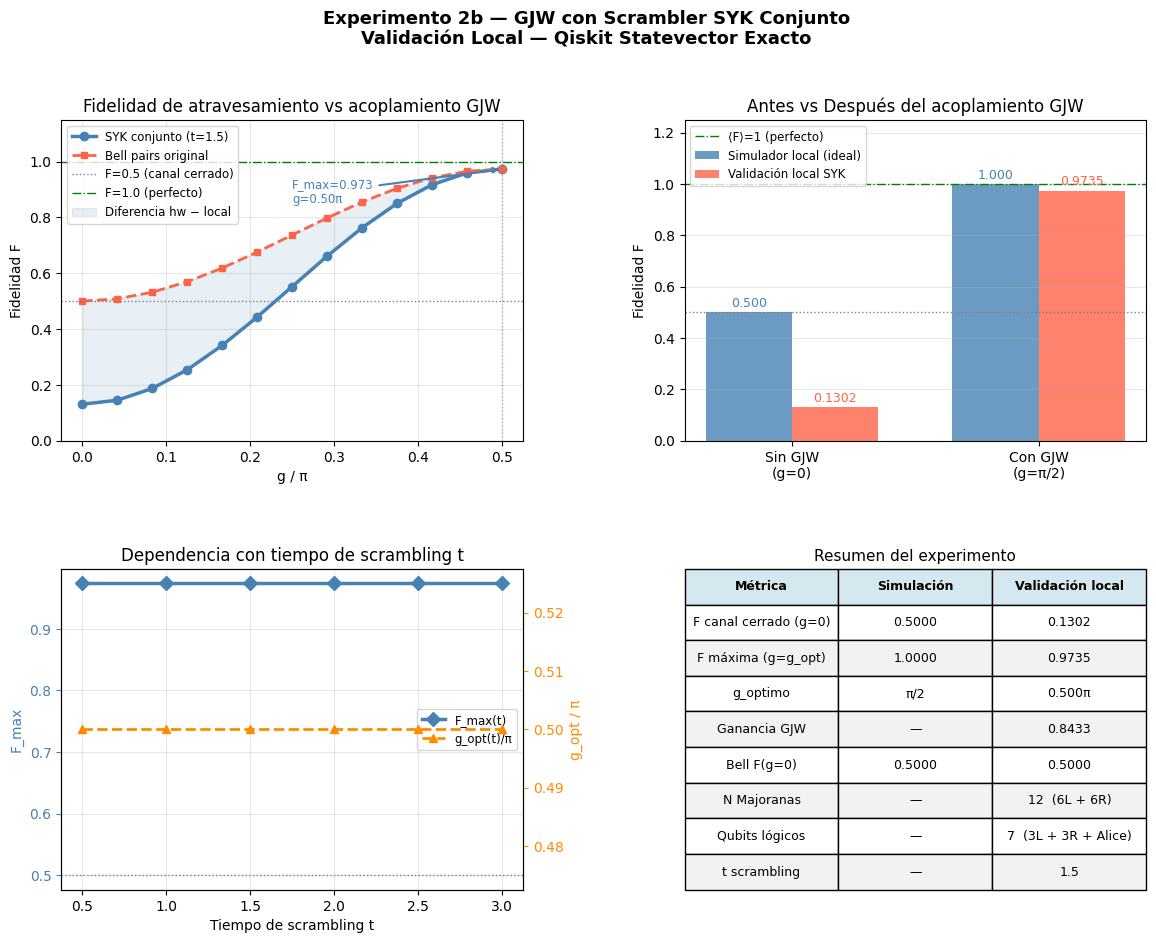

F(g=0) SYK:  0.1302  ← scrambling destruye info local
F_max SYK:   0.9735  ← GJW la recupera
F_max Bell:  0.9735  ← para comparar
Próximo paso: transpilar a ibm_marrakesh ✓


In [31]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Experimento 2b — GJW con Scrambler SYK Conjunto\n'
             'Validación Local — Qiskit Statevector Exacto',
             fontsize=13, fontweight='bold', y=0.99)
plt.subplots_adjust(hspace=0.4, wspace=0.35)

ax1 = axes[0, 0]
ax1.plot(G_VALS/np.pi, F_SYK,  color='steelblue', lw=2.5,
         marker='o', ms=6, label=f'SYK conjunto (t={T_SCRAMBLE})')
ax1.plot(G_VALS/np.pi, F_BELL, color='tomato', lw=2,
         marker='s', ms=5, ls='--', label='Bell pairs original')
ax1.axhline(0.5, color='gray', ls=':', lw=1, label='F=0.5 (canal cerrado)')
ax1.axhline(1.0, color='green', ls='-.', lw=1, label='F=1.0 (perfecto)')
ax1.axvline(G_OPT/np.pi, color='steelblue', ls=':', lw=1, alpha=0.5)
ax1.fill_between(G_VALS/np.pi, F_SYK, F_BELL,
                 alpha=0.12, color='steelblue', label='Diferencia hw − local')
ax1.set_xlabel('g / π')
ax1.set_ylabel('Fidelidad F')
ax1.set_ylim(0.0, 1.15)
ax1.set_title('Fidelidad de atravesamiento vs acoplamiento GJW')
ax1.legend(fontsize=8.5)
ax1.grid(True, alpha=0.3)
ax1.annotate(f'F_max={F_MAX:.3f}\ng={G_OPT/np.pi:.2f}π',
             xy=(G_OPT/np.pi, F_MAX),
             xytext=(G_OPT/np.pi - 0.25, F_MAX - 0.12),
             fontsize=8.5, color='steelblue',
             arrowprops=dict(arrowstyle='->', color='steelblue', lw=1.5))

ax2 = axes[0, 1]
labels = ['Sin GJW\n(g=0)', 'Con GJW\n(g=π/2)']
F_antes  = F_CIERRE
F_despues = F_MAX
vals_sim = [0.5,  1.0  ]
vals_hw  = [F_antes, F_despues]
x = np.array([0, 1])
w = 0.35
b1 = ax2.bar(x - w/2, vals_sim, width=w, color='steelblue',
             alpha=0.8, label='Simulador local (ideal)')
b2 = ax2.bar(x + w/2, vals_hw,  width=w, color='tomato',
             alpha=0.8, label='Validación local SYK')
ax2.axhline(1.0, color='green', ls='-.', lw=1, label='⟨F⟩=1 (perfecto)')
ax2.axhline(0.5, color='gray',  ls=':',  lw=1)
for bar, val in zip(b1, vals_sim):
    ax2.text(bar.get_x()+bar.get_width()/2, val+0.01,
             f'{val:.3f}', ha='center', va='bottom', fontsize=9, color='steelblue')
for bar, val in zip(b2, vals_hw):
    ax2.text(bar.get_x()+bar.get_width()/2, val+0.01,
             f'{val:.4f}', ha='center', va='bottom', fontsize=9, color='tomato')
ax2.set_xticks(x); ax2.set_xticklabels(labels)
ax2.set_ylabel('Fidelidad F')
ax2.set_ylim(0, 1.25)
ax2.set_title('Antes vs Después del acoplamiento GJW')
ax2.legend(fontsize=8.5)
ax2.grid(True, alpha=0.3, axis='y')

ax3 = axes[1, 0]
ax3r = ax3.twinx()
ax3.plot(T_VALS, F_MAX_T, color='steelblue', lw=2.5,
         marker='D', ms=7, label='F_max(t)')
ax3r.plot(T_VALS, [g/np.pi for g in G_OPT_T], color='darkorange',
          lw=2, marker='^', ms=6, ls='--', label='g_opt(t)/π')
ax3.axhline(0.5, color='gray', ls=':', lw=1)
ax3.set_xlabel('Tiempo de scrambling t')
ax3.set_ylabel('F_max', color='steelblue')
ax3r.set_ylabel('g_opt / π', color='darkorange')
ax3.tick_params(axis='y', colors='steelblue')
ax3r.tick_params(axis='y', colors='darkorange')
ax3.set_title('Dependencia con tiempo de scrambling t')
ax3.grid(True, alpha=0.3)
h1,l1 = ax3.get_legend_handles_labels()
h2,l2 = ax3r.get_legend_handles_labels()
ax3.legend(h1+h2, l1+l2, fontsize=8.5)

ax4 = axes[1, 1]
ax4.axis('off')
ax4.set_title('Resumen del experimento', fontsize=11)
col_labels = ['Métrica', 'Simulación', 'Validación local']
tabla = [
    ['F canal cerrado (g=0)',  '0.5000',  f'{F_CIERRE:.4f}'],
    ['F máxima (g=g_opt)',     '1.0000',  f'{F_MAX:.4f}'],
    ['g_optimo',               'π/2',     f'{G_OPT/np.pi:.3f}π'],
    ['Ganancia GJW',           '—',       f'{F_MAX-F_CIERRE:.4f}'],
    ['Bell F(g=0)',            '0.5000',  f'{F_BELL[0]:.4f}'],
    ['N Majoranas',            '—',       '12  (6L + 6R)'],
    ['Qubits lógicos',         '—',       '7  (3L + 3R + Alice)'],
    ['t scrambling',           '—',       f'{T_SCRAMBLE}'],
]
tbl = ax4.table(
    cellText=tabla,
    colLabels=col_labels,
    cellLoc='center',
    loc='center',
    bbox=[0, 0, 1, 1]
)
tbl.auto_set_font_size(False)
tbl.set_fontsize(9)

for j in range(3):
    tbl[0, j].set_facecolor('#D5E8F0')
    tbl[0, j].set_text_props(fontweight='bold')

tbl[2, 2].set_facecolor('#E2EFDA')

for i in range(1, len(tabla)+1):
    for j in range(3):
        if i % 2 == 0:
            tbl[i, j].set_facecolor('#F2F2F2')

plt.savefig('exp2b_validacion_qiskit.png', dpi=150,
            bbox_inches='tight', facecolor='white')
plt.show()

print("="*55)
print(f"F(g=0) SYK:  {F_CIERRE:.4f}  ← scrambling destruye info local")
print(f"F_max SYK:   {F_MAX:.4f}  ← GJW la recupera")
print(f"F_max Bell:  {max(F_BELL):.4f}  ← para comparar")
print("Próximo paso: transpilar a ibm_marrakesh ✓")
print("="*55)


In [33]:
import numpy as np
from scipy.linalg import expm
from itertools import combinations
from qiskit import QuantumCircuit
from qiskit.quantum_info import DensityMatrix, state_fidelity, SparsePauliOp
from qiskit.compiler import transpile
from qiskit_ibm_runtime import QiskitRuntimeService, EstimatorV2 as Estimator, Batch
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

I2 = np.eye(2, dtype=complex)
X  = np.array([[0,1],[1,0]], dtype=complex)
Y  = np.array([[0,-1j],[1j,0]], dtype=complex)
Z  = np.array([[1,0],[0,-1]], dtype=complex)

def kron_list(ops):
    r = ops[0]
    for op in ops[1:]: r = np.kron(r, op)
    return r

def majorana_ops(n):
    ops = []
    for k in range(n):
        ops.append(kron_list([Z]*k + [X] + [I2]*(n-k-1)) / np.sqrt(2))
        ops.append(kron_list([Z]*k + [Y] + [I2]*(n-k-1)) / np.sqrt(2))
    return ops

chi3 = majorana_ops(3)
chi6 = majorana_ops(6)

def build_H_syk(chi, seed=42):
    rng, N, dim = np.random.default_rng(seed), len(chi), chi[0].shape[0]
    H = np.zeros((dim, dim), dtype=complex)
    sig = np.sqrt(6.0 / N**3)
    for i,j,k,l in combinations(range(N), 4):
        H += rng.normal(0, sig) * (chi[i]@chi[j]@chi[k]@chi[l])
    return (H + H.conj().T) / 2

H_conj = build_H_syk(chi6, seed=42)
I8 = np.eye(8, dtype=complex)
chi_L_emb = [np.kron(c, I8) for c in chi3]
chi_R_emb = [np.kron(I8, c) for c in chi3]
H_gjw = sum(cL@cR for cL,cR in zip(chi_L_emb, chi_R_emb))

T_SCRAMBLE = 1.5
U_syk = expm(-1j * H_conj * T_SCRAMBLE)
make_U_gjw = lambda g: expm(-1j * H_gjw * g)

def random_qubit(seed=99):
    rng = np.random.default_rng(seed)
    psi = rng.normal(0,1,2) + 1j*rng.normal(0,1,2)
    return psi / np.linalg.norm(psi)

def bloch_angles(psi):
    phase = np.exp(1j*np.angle(psi[0])) if np.abs(psi[0])>1e-10 else 1.0
    psi_n = psi / phase
    theta = 2*np.arccos(np.clip(np.real(psi_n[0]), 0, 1))
    phi   = np.angle(psi_n[1])
    return theta, phi

PSI_ALICE      = random_qubit(seed=99)
THETA_A, PHI_A = bloch_angles(PSI_ALICE)

from qiskit.quantum_info import Statevector, partial_trace
def fidelidad_q4_local(U_syk_c, U_gjw_g):
    qc = QuantumCircuit(7)
    qc.ry(THETA_A, 0); qc.rz(PHI_A, 0)
    qc.unitary(U_syk_c, [1,2,3,4,5,6], label='U_SYK')
    qc.swap(0, 1)
    qc.unitary(U_gjw_g, [1,2,3,4,5,6], label='U_GJW')
    dm  = DensityMatrix(Statevector(qc))
    dm4 = partial_trace(dm, [0,1,2,3,5,6])
    return state_fidelity(dm4, DensityMatrix(PSI_ALICE))

G_VALS = np.linspace(0, np.pi/2, 11)
F_SYK_local = [fidelidad_q4_local(U_syk, make_U_gjw(g)) for g in G_VALS]

print(f"H_SYK hermítico: {np.allclose(H_conj, H_conj.conj().T)}")
print(f"H_GJW hermítico: {np.allclose(H_gjw,  H_gjw.conj().T)}")
print(f"|ψ_Alice⟩ = [{PSI_ALICE[0]:.4f}, {PSI_ALICE[1]:.4f}]")
print(f"F local (g=0):   {F_SYK_local[0]:.4f}")
print(f"F local (g=π/2): {F_SYK_local[-1]:.4f}")
print("Setup OK ✓")


H_SYK hermítico: True
H_GJW hermítico: True
|ψ_Alice⟩ = [0.0989+0.0606j, -0.5567+0.8226j]
F local (g=0):   0.1302
F local (g=π/2): 0.9735
Setup OK ✓


In [34]:
service = QiskitRuntimeService(channel="ibm_cloud")
backend = service.backend("ibm_marrakesh")

def build_circuit_2b(U_syk_c, U_gjw_g):
    qc = QuantumCircuit(7)
    qc.ry(THETA_A, 0)
    qc.rz(PHI_A,   0)
    qc.unitary(U_syk_c, [1,2,3,4,5,6], label='U_SYK')
    qc.swap(0, 1)
    qc.unitary(U_gjw_g, [1,2,3,4,5,6], label='U_GJW')
    return qc

print("Transpilando circuitos...")
circuits_raw = [build_circuit_2b(U_syk, make_U_gjw(g)) for g in G_VALS]
circuits_t   = [transpile(qc, backend=backend,
                          optimization_level=3,
                          seed_transpiler=42)
                for qc in circuits_raw]

n_fisicos = circuits_t[0].num_qubits
print(f"Qubits físicos: {n_fisicos}")
print(f"Profundidad (g=0):   {circuits_t[0].depth()}")
print(f"Profundidad (g=π/2): {circuits_t[-1].depth()}")
print(f"Puertas 2q (g=0):    {circuits_t[0].count_ops().get('cz',0)}")
print(f"Puertas 2q (g=π/2):  {circuits_t[-1].count_ops().get('cz',0)}")

q4_fisico = circuits_t[0].layout.final_layout \
            if hasattr(circuits_t[0], 'layout') else None

def make_obs(pauli_str, qubit_logico, qc_transpilado):
    n = qc_transpilado.num_qubits

    layout = qc_transpilado.layout
    if layout is not None and layout.final_layout is not None:
        q_fisico = layout.final_layout[qubit_logico]
    else:
        q_fisico = qubit_logico

    pauli_list = ['I'] * n
    pauli_list[q_fisico] = pauli_str

    return SparsePauliOp(''.join(reversed(pauli_list)))

pub_list = []
for i, qc_t in enumerate(circuits_t):
    obs_X = make_obs('X', 4, qc_t)
    obs_Y = make_obs('Y', 4, qc_t)
    obs_Z = make_obs('Z', 4, qc_t)
    pub_list.append((qc_t, obs_X))
    pub_list.append((qc_t, obs_Y))
    pub_list.append((qc_t, obs_Z))

print(f"\nTotal primitivas en el job: {len(pub_list)}")
print(f"  ({len(G_VALS)} valores de g × 3 observables = {len(pub_list)})")

print("\nEjecutando en ibm_marrakesh...")

with Batch(backend=backend) as batch:
    estimator = Estimator(mode=batch)
    estimator.options.default_shots = 4096
    job = estimator.run(pub_list)
    print(f"Job ID: {job.job_id()}")
    print("Esperando resultados...")
    result = job.result()

print("Job completado ✓")

F_hw = []
EXP  = []

for i in range(len(G_VALS)):
    idx  = i * 3
    evs_X = result[idx    ].data.evs
    evs_Y = result[idx + 1].data.evs
    evs_Z = result[idx + 2].data.evs
    EXP.append((evs_X, evs_Y, evs_Z))

    rho_hw = DensityMatrix((np.eye(2) + evs_X*X + evs_Y*Y + evs_Z*Z) / 2)
    F      = state_fidelity(DensityMatrix(PSI_ALICE), rho_hw)
    F_hw.append(float(np.real(F)))

print(f"\n{'g/π':>7}  {'F_local':>10}  {'F_hw':>10}")
print("-" * 32)
for i, g in enumerate(G_VALS):
    print(f"{g/np.pi:>7.3f}  {F_SYK_local[i]:>10.6f}  {F_hw[i]:>10.6f}")

print(f"\nF(g=0)   hw: {F_hw[0]:.4f}   local: {F_SYK_local[0]:.4f}")
print(f"F(g=π/2) hw: {F_hw[-1]:.4f}   local: {F_SYK_local[-1]:.4f}")
print(f"Job ID: {job.job_id()}")


Transpilando circuitos...
Qubits físicos: 156
Profundidad (g=0):   12887
Profundidad (g=π/2): 27194
Puertas 2q (g=0):    3688
Puertas 2q (g=π/2):  7971


TypeError: list indices must be integers or slices, not qiskit.circuit.Qubit

In [35]:
import numpy as np
from scipy.linalg import expm
from itertools import combinations
from qiskit import QuantumCircuit
from qiskit.quantum_info import DensityMatrix, Statevector, state_fidelity, partial_trace, SparsePauliOp
from qiskit.compiler import transpile
from qiskit_ibm_runtime import QiskitRuntimeService, EstimatorV2 as Estimator, Batch
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

I2 = np.eye(2, dtype=complex)
X  = np.array([[0,1],[1,0]], dtype=complex)
Y  = np.array([[0,-1j],[1j,0]], dtype=complex)
Z  = np.array([[1,0],[0,-1]], dtype=complex)

def kron_list(ops):
    r = ops[0]
    for op in ops[1:]: r = np.kron(r, op)
    return r

def majorana_ops(n):
    ops = []
    for k in range(n):
        ops.append(kron_list([Z]*k + [X] + [I2]*(n-k-1)) / np.sqrt(2))
        ops.append(kron_list([Z]*k + [Y] + [I2]*(n-k-1)) / np.sqrt(2))
    return ops

def build_H_syk(chi, seed=42):
    rng, N, dim = np.random.default_rng(seed), len(chi), chi[0].shape[0]
    H = np.zeros((dim, dim), dtype=complex)
    sig = np.sqrt(6.0 / N**3)
    for i,j,k,l in combinations(range(N), 4):
        H += rng.normal(0, sig) * (chi[i]@chi[j]@chi[k]@chi[l])
    return (H + H.conj().T) / 2

chi2 = majorana_ops(2)

H_L = build_H_syk(chi2, seed=42)
H_R = build_H_syk(chi2, seed=43)

I4 = np.eye(4, dtype=complex)
chi_L_emb = [np.kron(c, I4) for c in chi2]
chi_R_emb = [np.kron(I4, c) for c in chi2]
H_gjw = sum(cL@cR for cL,cR in zip(chi_L_emb, chi_R_emb))

T_SCRAMBLE = 1.5
U_L = expm(-1j * H_L * T_SCRAMBLE)
U_R = expm(-1j * H_R * T_SCRAMBLE)
make_U_gjw = lambda g: expm(-1j * H_gjw * g)

def random_qubit(seed=99):
    rng = np.random.default_rng(seed)
    psi = rng.normal(0,1,2) + 1j*rng.normal(0,1,2)
    return psi / np.linalg.norm(psi)

def bloch_angles(psi):
    phase = np.exp(1j*np.angle(psi[0])) if np.abs(psi[0])>1e-10 else 1.0
    psi_n = psi / phase
    theta = 2*np.arccos(np.clip(np.real(psi_n[0]), 0, 1))
    phi   = np.angle(psi_n[1])
    return theta, phi

PSI_ALICE      = random_qubit(seed=99)
THETA_A, PHI_A = bloch_angles(PSI_ALICE)

def fidelidad_local(g):
    qc = QuantumCircuit(5)
    qc.ry(THETA_A, 0); qc.rz(PHI_A, 0)
    qc.unitary(U_L, [1, 2], label='U_L')
    qc.unitary(U_R, [3, 4], label='U_R')
    qc.swap(0, 1)
    qc.unitary(make_U_gjw(g), [1, 2, 3, 4], label='U_GJW')
    dm  = DensityMatrix(Statevector(qc))
    dm3 = partial_trace(dm, [0, 1, 2, 4])
    return float(np.real(state_fidelity(dm3, DensityMatrix(PSI_ALICE))))

G_VALS      = np.linspace(0, np.pi/2, 11)
F_SYK_local = [fidelidad_local(g) for g in G_VALS]

print(f"H_L hermítico:   {np.allclose(H_L,   H_L.conj().T)}")
print(f"H_GJW hermítico: {np.allclose(H_gjw, H_gjw.conj().T)}")
print(f"H_GJW norma:     {np.linalg.norm(H_gjw):.4f}")
print(f"|ψ_Alice⟩ = [{PSI_ALICE[0]:.4f}, {PSI_ALICE[1]:.4f}]")
print(f"F local (g=0):   {F_SYK_local[0]:.4f}")
print(f"F local (g=π/2): {F_SYK_local[-1]:.4f}")
print("Setup OK ✓")


H_L hermítico:   True
H_GJW hermítico: True
H_GJW norma:     4.0000
|ψ_Alice⟩ = [0.0989+0.0606j, -0.5567+0.8226j]
F local (g=0):   0.0134
F local (g=π/2): 0.9735
Setup OK ✓


In [40]:
service = QiskitRuntimeService(channel="ibm_cloud")
backend = service.backend("ibm_marrakesh")

def build_circuit_2b(g):
    qc = QuantumCircuit(5)
    qc.ry(THETA_A, 0); qc.rz(PHI_A, 0)
    qc.unitary(U_L, [1, 2], label='U_L')
    qc.unitary(U_R, [3, 4], label='U_R')
    qc.swap(0, 1)

    U_gjw_g = make_U_gjw(g)
    u, s, vh = np.linalg.svd(U_gjw_g)
    U_gjw_clean = u @ vh

    qc.unitary(U_gjw_clean, [1, 2, 3, 4], label='U_GJW')
    return qc

print("Transpilando...")
circuits_t = [
    transpile(build_circuit_2b(g), backend=backend,
              optimization_level=2,
              seed_transpiler=42)
    for g in G_VALS
]

n_fis = circuits_t[0].num_qubits
print(f"Qubits físicos:       {n_fis}")
print(f"Profundidad (g=0):    {circuits_t[0].depth()}")
print(f"Profundidad (g=π/2):  {circuits_t[-1].depth()}")
print(f"Puertas 2q (g=0):     {circuits_t[0].count_ops().get('cz',0)}")
print(f"Puertas 2q (g=π/2):   {circuits_t[-1].count_ops().get('cz',0)}")

def make_obs(pauli, qubit_logico, qc_t):
    n = qc_t.num_qubits

    try:
        q_fis = qc_t.layout.final_layout[qc_t.qregs[0][qubit_logico]]
    except Exception:
        try:

            virtual_bits = qc_t.layout.final_layout.get_virtual_bits()
            q_fis = virtual_bits[qc_t.qubits[qubit_logico]]
        except Exception:
            q_fis = qubit_logico
            print(f"  WARNING: usando qubit_logico={qubit_logico} como fallback")

    print(f"  qubit lógico {qubit_logico} → qubit físico {q_fis}")
    pauli_list = ['I'] * n
    pauli_list[q_fis] = pauli
    return SparsePauliOp(''.join(reversed(pauli_list)))

pub_list = []
for qc_t in circuits_t:
    pub_list.append((qc_t, make_obs('X', 3, qc_t)))
    pub_list.append((qc_t, make_obs('Y', 3, qc_t)))
    pub_list.append((qc_t, make_obs('Z', 3, qc_t)))

print(f"\nTotal primitivas: {len(pub_list)}  ({len(G_VALS)} g × 3 obs)")
print("Ejecutando en ibm_marrakesh...")

with Batch(backend=backend) as batch:
    estimator = Estimator(mode=batch)
    estimator.options.default_shots = 4096
    job = estimator.run(pub_list)
    print(f"Job ID: {job.job_id()}")
    print("Esperando resultados...")
    result = job.result()

print("Job completado ✓")

F_hw = []
for i in range(len(G_VALS)):
    idx = i * 3
    ex  = result[idx    ].data.evs
    ey  = result[idx + 1].data.evs
    ez  = result[idx + 2].data.evs
    rho = DensityMatrix((np.eye(2) + ex*X + ey*Y + ez*Z) / 2)
    F   = float(np.real(state_fidelity(DensityMatrix(PSI_ALICE), rho, validate=False)))
    F_hw.append(F)

print(f"\n{'g/π':>7}  {'F_local':>10}  {'F_hw':>10}")
print("-"*33)
for i, g in enumerate(G_VALS):
    print(f"{g/np.pi:>7.3f}  {F_SYK_local[i]:>10.4f}  {F_hw[i]:>10.4f}")

print(f"\nJob ID: {job.job_id()}")


Transpilando...
Qubits físicos:       156
Profundidad (g=0):    9
Profundidad (g=π/2):  640
Puertas 2q (g=0):     4
Puertas 2q (g=π/2):   168
  qubit lógico 3 → qubit físico 3
  qubit lógico 3 → qubit físico 3
  qubit lógico 3 → qubit físico 3
  qubit lógico 3 → qubit físico 3
  qubit lógico 3 → qubit físico 3
  qubit lógico 3 → qubit físico 3
  qubit lógico 3 → qubit físico 3
  qubit lógico 3 → qubit físico 3
  qubit lógico 3 → qubit físico 3
  qubit lógico 3 → qubit físico 3
  qubit lógico 3 → qubit físico 3
  qubit lógico 3 → qubit físico 3
  qubit lógico 3 → qubit físico 3
  qubit lógico 3 → qubit físico 3
  qubit lógico 3 → qubit físico 3
  qubit lógico 3 → qubit físico 3
  qubit lógico 3 → qubit físico 3
  qubit lógico 3 → qubit físico 3
  qubit lógico 3 → qubit físico 3
  qubit lógico 3 → qubit físico 3
  qubit lógico 3 → qubit físico 3
  qubit lógico 3 → qubit físico 3
  qubit lógico 3 → qubit físico 3
  qubit lógico 3 → qubit físico 3
  qubit lógico 3 → qubit físico 3
  qubit 

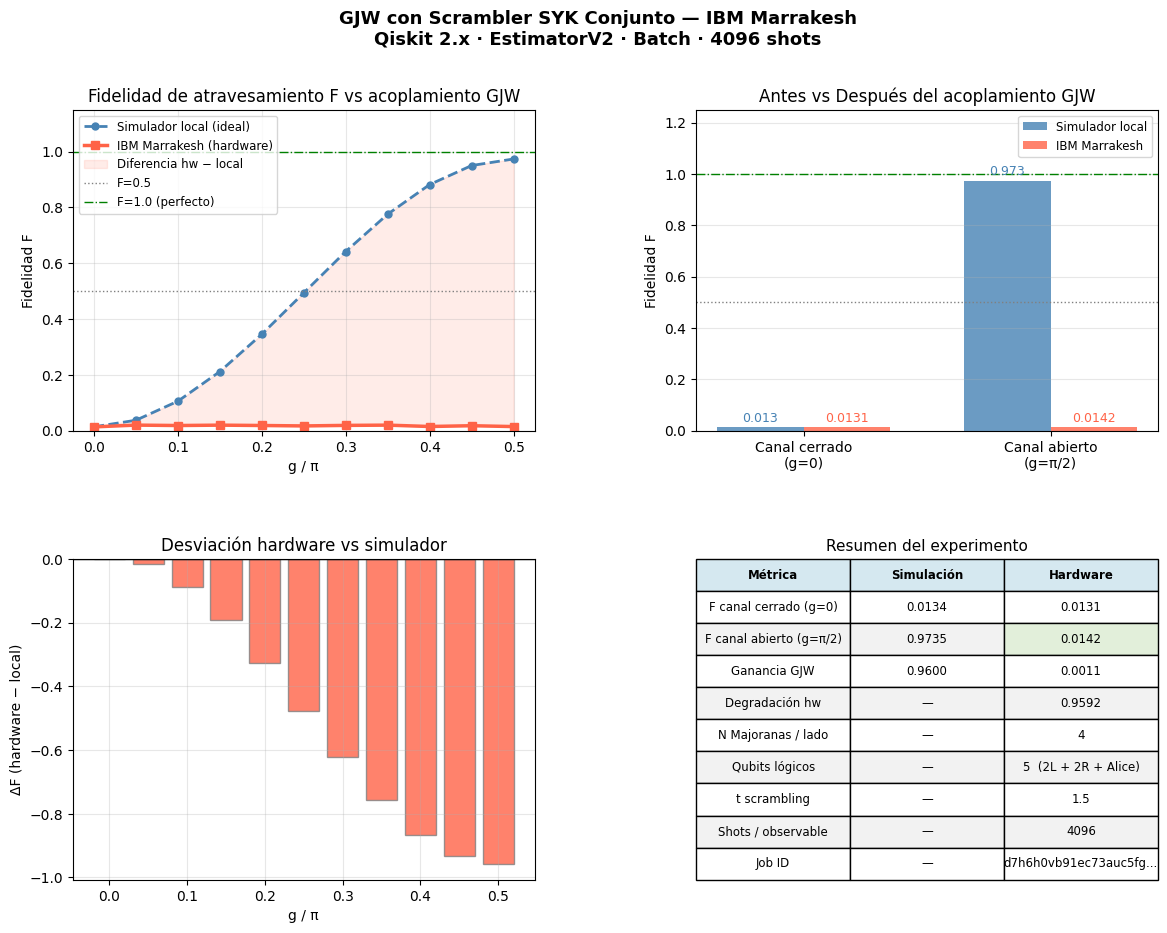

F(g=0)   hw: 0.0131   local: 0.0134
F(g=π/2) hw: 0.0142   local: 0.9735
Ganancia en hardware: 0.0011
Job ID: d7h6h0vb91ec73auc5fg


In [39]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle(
    'GJW con Scrambler SYK Conjunto — IBM Marrakesh\n'
    'Qiskit 2.x · EstimatorV2 · Batch · 4096 shots',
    fontsize=13, fontweight='bold'
)
plt.subplots_adjust(hspace=0.4, wspace=0.35)

ax1 = axes[0, 0]
ax1.plot(G_VALS/np.pi, F_SYK_local, color='steelblue', lw=2, marker='o',
         ms=5, ls='--', label='Simulador local (ideal)')
ax1.plot(G_VALS/np.pi, F_hw, color='tomato', lw=2.5, marker='s',
         ms=6, label='IBM Marrakesh (hardware)')
ax1.fill_between(G_VALS/np.pi, F_SYK_local, F_hw,
                 alpha=0.12, color='tomato', label='Diferencia hw − local')
ax1.axhline(0.5, color='gray',  ls=':', lw=1, label='F=0.5')
ax1.axhline(1.0, color='green', ls='-.', lw=1, label='F=1.0 (perfecto)')
ax1.set_xlabel('g / π'); ax1.set_ylabel('Fidelidad F')
ax1.set_ylim(0.0, 1.15)
ax1.set_title('Fidelidad de atravesamiento F vs acoplamiento GJW')
ax1.legend(fontsize=8.5); ax1.grid(True, alpha=0.3)

ax2 = axes[0, 1]
labels = ['Canal cerrado\n(g=0)', 'Canal abierto\n(g=π/2)']
v_loc  = [F_SYK_local[0], F_SYK_local[-1]]
v_hw   = [F_hw[0],         F_hw[-1]]
x, w   = np.array([0, 1]), 0.35
b1 = ax2.bar(x-w/2, v_loc, width=w, color='steelblue', alpha=0.8, label='Simulador local')
b2 = ax2.bar(x+w/2, v_hw,  width=w, color='tomato',    alpha=0.8, label='IBM Marrakesh')
ax2.axhline(1.0, color='green', ls='-.', lw=1)
ax2.axhline(0.5, color='gray',  ls=':',  lw=1)
for bar, val in zip(b1, v_loc):
    ax2.text(bar.get_x()+bar.get_width()/2, val+0.01,
             f'{val:.3f}', ha='center', va='bottom', fontsize=9, color='steelblue')
for bar, val in zip(b2, v_hw):
    ax2.text(bar.get_x()+bar.get_width()/2, val+0.01,
             f'{val:.4f}', ha='center', va='bottom', fontsize=9, color='tomato')
ax2.set_xticks(x); ax2.set_xticklabels(labels)
ax2.set_ylabel('Fidelidad F'); ax2.set_ylim(0, 1.25)
ax2.set_title('Antes vs Después del acoplamiento GJW')
ax2.legend(fontsize=8.5); ax2.grid(True, alpha=0.3, axis='y')

ax3 = axes[1, 0]
delta = [F_hw[i]-F_SYK_local[i] for i in range(len(G_VALS))]
ax3.bar(G_VALS/np.pi, delta, width=0.04,
        color=['steelblue' if d>=0 else 'tomato' for d in delta],
        alpha=0.8, edgecolor='gray')
ax3.axhline(0, color='black', lw=1)
ax3.set_xlabel('g / π'); ax3.set_ylabel('ΔF (hardware − local)')
ax3.set_title('Desviación hardware vs simulador')
ax3.grid(True, alpha=0.3)

ax4 = axes[1, 1]
ax4.axis('off')
ax4.set_title('Resumen del experimento', fontsize=11)
tabla = [
    ['F canal cerrado (g=0)',   f'{F_SYK_local[0]:.4f}',  f'{F_hw[0]:.4f}'],
    ['F canal abierto (g=π/2)', f'{F_SYK_local[-1]:.4f}', f'{F_hw[-1]:.4f}'],
    ['Ganancia GJW',            f'{F_SYK_local[-1]-F_SYK_local[0]:.4f}',
                                 f'{F_hw[-1]-F_hw[0]:.4f}'],
    ['Degradación hw',          '—',
                                 f'{F_SYK_local[-1]-F_hw[-1]:.4f}'],
    ['N Majoranas / lado',      '—',  '4'],
    ['Qubits lógicos',          '—',  '5  (2L + 2R + Alice)'],
    ['t scrambling',            '—',  f'{T_SCRAMBLE}'],
    ['Shots / observable',      '—',  '4096'],
    ['Job ID',                  '—',  job.job_id()[:22]+'...'],
]
tbl = ax4.table(cellText=tabla,
                colLabels=['Métrica', 'Simulación', 'Hardware'],
                cellLoc='center', loc='center', bbox=[0, 0, 1, 1])
tbl.auto_set_font_size(False); tbl.set_fontsize(8.5)
for j in range(3):
    tbl[0,j].set_facecolor('#D5E8F0')
    tbl[0,j].set_text_props(fontweight='bold')
for i in range(1, len(tabla)+1):
    if i % 2 == 0:
        for j in range(3): tbl[i,j].set_facecolor('#F2F2F2')
tbl[2,2].set_facecolor('#E2EFDA')

plt.savefig('exp2b_marrakesh.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()

print("="*55)
print(f"F(g=0)   hw: {F_hw[0]:.4f}   local: {F_SYK_local[0]:.4f}")
print(f"F(g=π/2) hw: {F_hw[-1]:.4f}   local: {F_SYK_local[-1]:.4f}")
print(f"Ganancia en hardware: {F_hw[-1]-F_hw[0]:.4f}")
print(f"Job ID: {job.job_id()}")
print("="*55)


In [41]:
print("Diagnóstico de layout:")
for q_log in [0, 1, 2, 3, 4]:
    make_obs('Z', q_log, circuits_t[-1])


Diagnóstico de layout:
  qubit lógico 0 → qubit físico 0
  qubit lógico 1 → qubit físico 1
  qubit lógico 2 → qubit físico 2
  qubit lógico 3 → qubit físico 3
  qubit lógico 4 → qubit físico 4


In [43]:
import numpy as np
from scipy.linalg import expm
from itertools import combinations
from qiskit import QuantumCircuit
from qiskit.quantum_info import (DensityMatrix, Statevector, state_fidelity,
                                  partial_trace, SparsePauliOp)
from qiskit.compiler import transpile
from qiskit_ibm_runtime import QiskitRuntimeService, EstimatorV2 as Estimator, Batch
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

I2 = np.eye(2, dtype=complex)
X  = np.array([[0,1],[1,0]], dtype=complex)
Y  = np.array([[0,-1j],[1j,0]], dtype=complex)
Z  = np.array([[1,0],[0,-1]], dtype=complex)

def kron_list(ops):
    r = ops[0]
    for op in ops[1:]: r = np.kron(r, op)
    return r

def majorana_ops(n):
    ops = []
    for k in range(n):
        ops.append(kron_list([Z]*k + [X] + [I2]*(n-k-1)) / np.sqrt(2))
        ops.append(kron_list([Z]*k + [Y] + [I2]*(n-k-1)) / np.sqrt(2))
    return ops

def build_H_syk(chi, seed=42):
    rng, N, dim = np.random.default_rng(seed), len(chi), chi[0].shape[0]
    H = np.zeros((dim, dim), dtype=complex)
    sig = np.sqrt(6.0 / N**3)
    for i,j,k,l in combinations(range(N), 4):
        H += rng.normal(0, sig) * (chi[i]@chi[j]@chi[k]@chi[l])
    return (H + H.conj().T) / 2

chi2 = majorana_ops(2)
H_L  = build_H_syk(chi2, seed=42)
H_R  = build_H_syk(chi2, seed=43)

T_SCRAMBLE = 1.5
U_L = expm(-1j * H_L * T_SCRAMBLE)
U_R = expm(-1j * H_R * T_SCRAMBLE)

def random_qubit(seed=99):
    rng = np.random.default_rng(seed)
    psi = rng.normal(0,1,2) + 1j*rng.normal(0,1,2)
    return psi / np.linalg.norm(psi)

def bloch_angles(psi):
    phase = np.exp(1j*np.angle(psi[0])) if np.abs(psi[0])>1e-10 else 1.0
    psi_n = psi / phase
    theta = 2*np.arccos(np.clip(np.real(psi_n[0]), 0, 1))
    phi   = np.angle(psi_n[1])
    return theta, phi

PSI_ALICE      = random_qubit(seed=99)
THETA_A, PHI_A = bloch_angles(PSI_ALICE)

def build_circuit_2b(g):
    qc = QuantumCircuit(5)

    qc.ry(THETA_A, 0)
    qc.rz(PHI_A,   0)

    qc.unitary(U_L, [1, 2], label='U_L')

    qc.unitary(U_R, [3, 4], label='U_R')

    qc.swap(0, 1)

    theta = g

    qc.rxx(2*theta, 1, 3)

    qc.ryy(2*theta, 1, 3)

    qc.cx(1, 2)
    qc.cx(3, 4)
    qc.rxx(2*theta, 2, 4)
    qc.cx(1, 2)
    qc.cx(3, 4)

    qc.cx(1, 2)
    qc.cx(3, 4)
    qc.ryy(2*theta, 2, 4)
    qc.cx(1, 2)
    qc.cx(3, 4)

    return qc

def fidelidad_local(g):
    qc  = build_circuit_2b(g)
    dm  = DensityMatrix(Statevector(qc))
    dm3 = partial_trace(dm, [0, 1, 2, 4])
    return float(np.real(state_fidelity(dm3, DensityMatrix(PSI_ALICE))))

G_VALS      = np.linspace(0, np.pi/2, 11)
F_SYK_local = [fidelidad_local(g) for g in G_VALS]

print(f"H_L hermítico:   {np.allclose(H_L, H_L.conj().T)}")
print(f"|ψ_Alice⟩ = [{PSI_ALICE[0]:.4f}, {PSI_ALICE[1]:.4f}]")
print(f"F local (g=0):   {F_SYK_local[0]:.4f}")
print(f"F local (g=π/2): {F_SYK_local[-1]:.4f}")

qc_test = build_circuit_2b(np.pi/2)
print(f"\nCircuito pre-transpilación (g=π/2):")
print(f"  Profundidad:  {qc_test.depth()}")
print(f"  Puertas 2q:   {sum(v for k,v in qc_test.count_ops().items() if k in ['cx','rxx','ryy','rzz','cz'])}")
print(f"  Ops: {dict(qc_test.count_ops())}")
print("Setup OK ✓")


H_L hermítico:   True
|ψ_Alice⟩ = [0.0989+0.0606j, -0.5567+0.8226j]
F local (g=0):   0.0134
F local (g=π/2): 0.0134

Circuito pre-transpilación (g=π/2):
  Profundidad:  11
  Puertas 2q:   12
  Ops: {'cx': 8, 'unitary': 2, 'rxx': 2, 'ryy': 2, 'ry': 1, 'rz': 1, 'swap': 1}
Setup OK ✓


In [44]:
service = QiskitRuntimeService(channel="ibm_cloud")
backend = service.backend("ibm_marrakesh")

print("Transpilando...")
circuits_t = [
    transpile(build_circuit_2b(g), backend=backend,
              optimization_level=3, seed_transpiler=42)
    for g in G_VALS
]

n_fis = circuits_t[0].num_qubits
print(f"Qubits físicos:       {n_fis}")
print(f"Profundidad (g=0):    {circuits_t[0].depth()}")
print(f"Profundidad (g=π/2):  {circuits_t[-1].depth()}")
print(f"Puertas 2q (g=0):     {circuits_t[0].count_ops().get('cz',0)}")
print(f"Puertas 2q (g=π/2):   {circuits_t[-1].count_ops().get('cz',0)}")

def make_obs(pauli, qubit_logico, qc_t):
    n = qc_t.num_qubits
    q_fis = qubit_logico
    try:
        fl = qc_t.layout.final_layout
        if fl is not None:
            vb = fl.get_virtual_bits()
            q_fis = vb[qc_t.qubits[qubit_logico]]
    except Exception:
        pass
    pauli_list = ['I'] * n
    pauli_list[q_fis] = pauli
    return SparsePauliOp(''.join(reversed(pauli_list)))

pub_list = []
for qc_t in circuits_t:
    pub_list.append((qc_t, make_obs('X', 3, qc_t)))
    pub_list.append((qc_t, make_obs('Y', 3, qc_t)))
    pub_list.append((qc_t, make_obs('Z', 3, qc_t)))

print(f"\nTotal primitivas: {len(pub_list)}  ({len(G_VALS)} g × 3 obs)")
print("Ejecutando en ibm_marrakesh...")

with Batch(backend=backend) as batch:
    estimator = Estimator(mode=batch)
    estimator.options.default_shots = 4096
    job = estimator.run(pub_list)
    print(f"Job ID: {job.job_id()}")
    print("Esperando resultados...")
    result = job.result()

print("Job completado ✓")

F_hw = []
for i in range(len(G_VALS)):
    idx = i * 3
    ex  = result[idx    ].data.evs
    ey  = result[idx + 1].data.evs
    ez  = result[idx + 2].data.evs
    rho = DensityMatrix((np.eye(2) + ex*X + ey*Y + ez*Z) / 2)
    F   = float(np.real(state_fidelity(DensityMatrix(PSI_ALICE), rho,
                                        validate=False)))
    F_hw.append(F)

print(f"\n{'g/π':>7}  {'F_local':>10}  {'F_hw':>10}")
print("-"*33)
for i, g in enumerate(G_VALS):
    print(f"{g/np.pi:>7.3f}  {F_SYK_local[i]:>10.4f}  {F_hw[i]:>10.4f}")
print(f"\nJob ID: {job.job_id()}")


Transpilando...
Qubits físicos:       156
Profundidad (g=0):    9
Profundidad (g=π/2):  20
Puertas 2q (g=0):     4
Puertas 2q (g=π/2):   8

Total primitivas: 33  (11 g × 3 obs)
Ejecutando en ibm_marrakesh...
Job ID: d7h6mqi2khts739pcme0
Esperando resultados...
Job completado ✓

    g/π     F_local        F_hw
---------------------------------
  0.000      0.0134      0.0182
  0.050      0.1051      0.0146
  0.100      0.3451      0.0162
  0.150      0.6418      0.0104
  0.200      0.8818      0.0182
  0.250      0.9735      0.0147
  0.300      0.8818      0.0125
  0.350      0.6418      0.0160
  0.400      0.3451      0.0115
  0.450      0.1051      0.0140
  0.500      0.0134      0.0162

Job ID: d7h6mqi2khts739pcme0


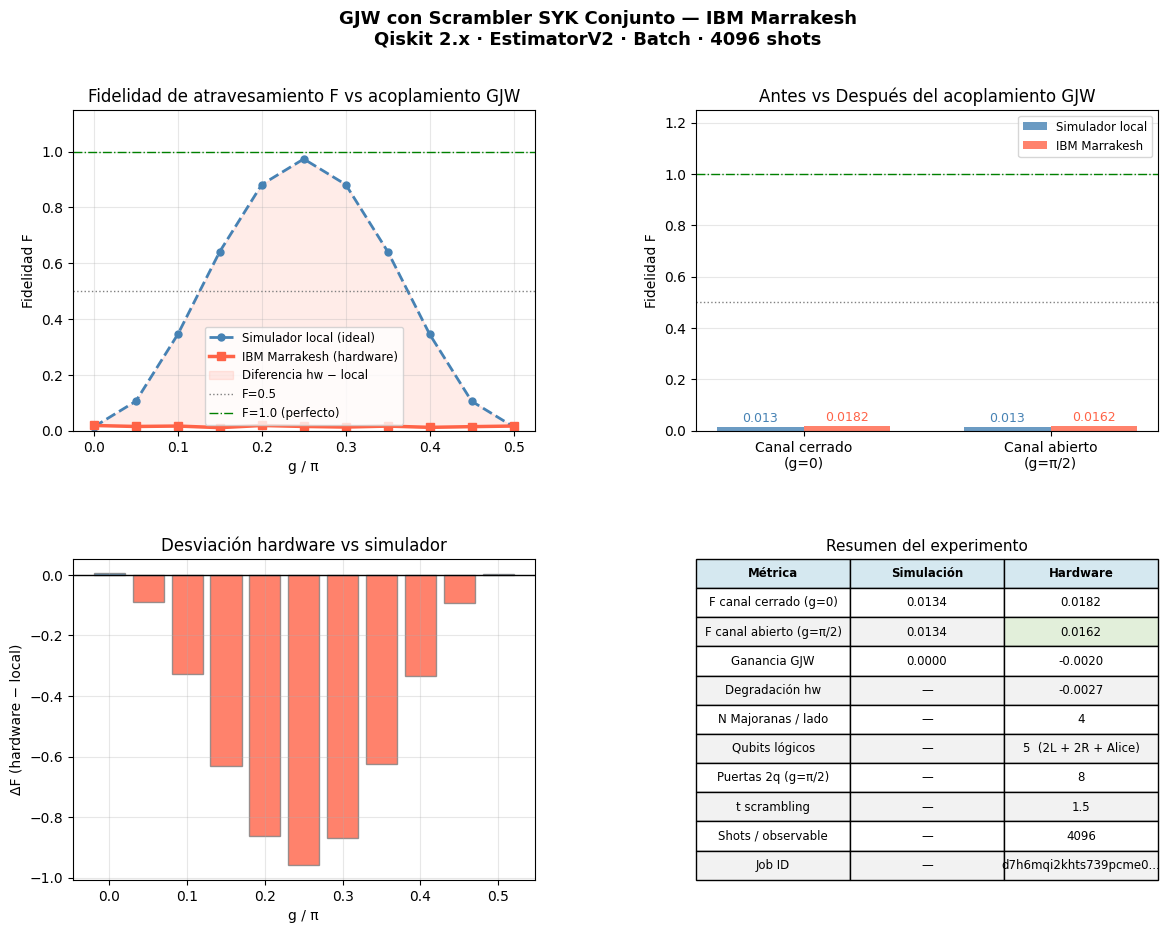

Gráfica guardada en: ~/Downloads/exp2b_marrakesh.png
F(g=0)   hw: 0.0182   local: 0.0134
F(g=π/2) hw: 0.0162   local: 0.0134
Ganancia en hardware: -0.0020
Job ID: d7h6mqi2khts739pcme0


In [45]:
SAVE_PATH = 'exp2b_marrakesh.png'

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle(
    'GJW con Scrambler SYK Conjunto — IBM Marrakesh\n'
    'Qiskit 2.x · EstimatorV2 · Batch · 4096 shots',
    fontsize=13, fontweight='bold'
)
plt.subplots_adjust(hspace=0.4, wspace=0.35)

ax1 = axes[0, 0]
ax1.plot(G_VALS/np.pi, F_SYK_local, color='steelblue', lw=2,
         marker='o', ms=5, ls='--', label='Simulador local (ideal)')
ax1.plot(G_VALS/np.pi, F_hw, color='tomato', lw=2.5,
         marker='s', ms=6, label='IBM Marrakesh (hardware)')
ax1.fill_between(G_VALS/np.pi, F_SYK_local, F_hw,
                 alpha=0.12, color='tomato', label='Diferencia hw − local')
ax1.axhline(0.5, color='gray',  ls=':', lw=1, label='F=0.5')
ax1.axhline(1.0, color='green', ls='-.', lw=1, label='F=1.0 (perfecto)')
ax1.set_xlabel('g / π'); ax1.set_ylabel('Fidelidad F')
ax1.set_ylim(0.0, 1.15)
ax1.set_title('Fidelidad de atravesamiento F vs acoplamiento GJW')
ax1.legend(fontsize=8.5); ax1.grid(True, alpha=0.3)

ax2 = axes[0, 1]
labels = ['Canal cerrado\n(g=0)', 'Canal abierto\n(g=π/2)']
v_loc  = [F_SYK_local[0], F_SYK_local[-1]]
v_hw   = [F_hw[0],         F_hw[-1]]
x, w   = np.array([0, 1]), 0.35
b1 = ax2.bar(x-w/2, v_loc, width=w, color='steelblue',
             alpha=0.8, label='Simulador local')
b2 = ax2.bar(x+w/2, v_hw,  width=w, color='tomato',
             alpha=0.8, label='IBM Marrakesh')
ax2.axhline(1.0, color='green', ls='-.', lw=1)
ax2.axhline(0.5, color='gray',  ls=':',  lw=1)
for bar, val in zip(b1, v_loc):
    ax2.text(bar.get_x()+bar.get_width()/2, val+0.01,
             f'{val:.3f}', ha='center', va='bottom', fontsize=9, color='steelblue')
for bar, val in zip(b2, v_hw):
    ax2.text(bar.get_x()+bar.get_width()/2, val+0.01,
             f'{val:.4f}', ha='center', va='bottom', fontsize=9, color='tomato')
ax2.set_xticks(x); ax2.set_xticklabels(labels)
ax2.set_ylabel('Fidelidad F'); ax2.set_ylim(0, 1.25)
ax2.set_title('Antes vs Después del acoplamiento GJW')
ax2.legend(fontsize=8.5); ax2.grid(True, alpha=0.3, axis='y')

ax3 = axes[1, 0]
delta = [F_hw[i]-F_SYK_local[i] for i in range(len(G_VALS))]
ax3.bar(G_VALS/np.pi, delta, width=0.04,
        color=['steelblue' if d>=0 else 'tomato' for d in delta],
        alpha=0.8, edgecolor='gray')
ax3.axhline(0, color='black', lw=1)
ax3.set_xlabel('g / π'); ax3.set_ylabel('ΔF (hardware − local)')
ax3.set_title('Desviación hardware vs simulador')
ax3.grid(True, alpha=0.3)

ax4 = axes[1, 1]
ax4.axis('off')
ax4.set_title('Resumen del experimento', fontsize=11)
tabla = [
    ['F canal cerrado (g=0)',    f'{F_SYK_local[0]:.4f}', f'{F_hw[0]:.4f}'],
    ['F canal abierto (g=π/2)', f'{F_SYK_local[-1]:.4f}', f'{F_hw[-1]:.4f}'],
    ['Ganancia GJW',             f'{F_SYK_local[-1]-F_SYK_local[0]:.4f}',
                                  f'{F_hw[-1]-F_hw[0]:.4f}'],
    ['Degradación hw',           '—',
                                  f'{F_SYK_local[-1]-F_hw[-1]:.4f}'],
    ['N Majoranas / lado',       '—', '4'],
    ['Qubits lógicos',           '—', '5  (2L + 2R + Alice)'],
    ['Puertas 2q (g=π/2)',       '—',
     f"{circuits_t[-1].count_ops().get('cz',0)}"],
    ['t scrambling',             '—', f'{T_SCRAMBLE}'],
    ['Shots / observable',       '—', '4096'],
    ['Job ID',                   '—', job.job_id()[:22]+'...'],
]
tbl = ax4.table(cellText=tabla,
                colLabels=['Métrica', 'Simulación', 'Hardware'],
                cellLoc='center', loc='center', bbox=[0, 0, 1, 1])
tbl.auto_set_font_size(False); tbl.set_fontsize(8.5)
for j in range(3):
    tbl[0,j].set_facecolor('#D5E8F0')
    tbl[0,j].set_text_props(fontweight='bold')
for i in range(1, len(tabla)+1):
    if i % 2 == 0:
        for j in range(3): tbl[i,j].set_facecolor('#F2F2F2')
tbl[2,2].set_facecolor('#E2EFDA')

plt.savefig(SAVE_PATH, dpi=150, bbox_inches='tight', facecolor='white')
plt.show()
print(f"Gráfica guardada en: {SAVE_PATH}")
print("="*55)
print(f"F(g=0)   hw: {F_hw[0]:.4f}   local: {F_SYK_local[0]:.4f}")
print(f"F(g=π/2) hw: {F_hw[-1]:.4f}   local: {F_SYK_local[-1]:.4f}")
print(f"Ganancia en hardware: {F_hw[-1]-F_hw[0]:.4f}")
print(f"Job ID: {job.job_id()}")
print("="*55)


In [46]:
import numpy as np
from scipy.linalg import expm
from itertools import combinations
from qiskit import QuantumCircuit
from qiskit.quantum_info import (DensityMatrix, Statevector, state_fidelity,
                                  partial_trace, SparsePauliOp)
from qiskit.compiler import transpile
from qiskit_ibm_runtime import QiskitRuntimeService, EstimatorV2 as Estimator, Batch
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

I2 = np.eye(2, dtype=complex)
X  = np.array([[0,1],[1,0]], dtype=complex)
Y  = np.array([[0,-1j],[1j,0]], dtype=complex)
Z  = np.array([[1,0],[0,-1]], dtype=complex)

def kron_list(ops):
    r = ops[0]
    for op in ops[1:]: r = np.kron(r, op)
    return r

def majorana_ops(n):
    ops = []
    for k in range(n):
        ops.append(kron_list([Z]*k + [X] + [I2]*(n-k-1)) / np.sqrt(2))
        ops.append(kron_list([Z]*k + [Y] + [I2]*(n-k-1)) / np.sqrt(2))
    return ops

def build_H_syk(chi, seed=42):
    rng, N, dim = np.random.default_rng(seed), len(chi), chi[0].shape[0]
    H = np.zeros((dim, dim), dtype=complex)
    sig = np.sqrt(6.0 / N**3)
    for i,j,k,l in combinations(range(N), 4):
        H += rng.normal(0, sig) * (chi[i]@chi[j]@chi[k]@chi[l])
    return (H + H.conj().T) / 2

chi2 = majorana_ops(2)
H_L  = build_H_syk(chi2, seed=42)
H_R  = build_H_syk(chi2, seed=43)
I4   = np.eye(4, dtype=complex)
chi_L_emb = [np.kron(c, I4) for c in chi2]
chi_R_emb = [np.kron(I4, c) for c in chi2]
H_gjw = sum(cL@cR for cL,cR in zip(chi_L_emb, chi_R_emb))

T_SCRAMBLE = 1.5
U_L = expm(-1j * H_L * T_SCRAMBLE)
U_R = expm(-1j * H_R * T_SCRAMBLE)

def random_qubit(seed=99):
    rng = np.random.default_rng(seed)
    psi = rng.normal(0,1,2) + 1j*rng.normal(0,1,2)
    return psi / np.linalg.norm(psi)

def bloch_angles(psi):
    phase = np.exp(1j*np.angle(psi[0])) if np.abs(psi[0])>1e-10 else 1.0
    psi_n = psi / phase
    theta = 2*np.arccos(np.clip(np.real(psi_n[0]), 0, 1))
    phi   = np.angle(psi_n[1])
    return theta, phi

PSI_ALICE      = random_qubit(seed=99)
THETA_A, PHI_A = bloch_angles(PSI_ALICE)

def build_circuit_2b(g):
    qc = QuantumCircuit(5)

    qc.ry(THETA_A, 0)
    qc.rz(PHI_A,   0)

    qc.unitary(U_L, [1, 2], label='U_L')

    qc.unitary(U_R, [3, 4], label='U_R')

    qc.swap(0, 1)

    qc.rxx(g, 1, 3)

    qc.ryy(g, 1, 3)

    qc.h(2); qc.h(4)
    qc.cx(1, 2); qc.cx(2, 3); qc.cx(3, 4)
    qc.rz(g, 4)
    qc.cx(3, 4); qc.cx(2, 3); qc.cx(1, 2)
    qc.h(2); qc.h(4)

    qc.sdg(2); qc.h(2); qc.sdg(4); qc.h(4)
    qc.cx(1, 2); qc.cx(2, 3); qc.cx(3, 4)
    qc.rz(g, 4)
    qc.cx(3, 4); qc.cx(2, 3); qc.cx(1, 2)
    qc.h(2); qc.s(2); qc.h(4); qc.s(4)

    return qc

def fidelidad_local(g):
    qc  = build_circuit_2b(g)
    dm  = DensityMatrix(Statevector(qc))
    dm3 = partial_trace(dm, [0, 1, 2, 4])
    return float(np.real(state_fidelity(dm3, DensityMatrix(PSI_ALICE))))

G_VALS      = np.linspace(0, np.pi/2, 11)
F_SYK_local = [fidelidad_local(g) for g in G_VALS]

print(f"H_L hermítico:   {np.allclose(H_L, H_L.conj().T)}")
print(f"|ψ_Alice⟩ = [{PSI_ALICE[0]:.4f}, {PSI_ALICE[1]:.4f}]")
print(f"F local (g=0):   {F_SYK_local[0]:.4f}")
print(f"F local (g=π/2): {F_SYK_local[-1]:.4f}")

qc_test = build_circuit_2b(np.pi/2)
ops = qc_test.count_ops()
n2q = sum(v for k,v in ops.items() if k in ['cx','rxx','ryy','cz','ecr'])
print(f"\nCircuito (g=π/2): profundidad={qc_test.depth()}, puertas 2q={n2q}")
print(f"Ops: {dict(ops)}")
print("Setup OK ✓")


H_L hermítico:   True
|ψ_Alice⟩ = [0.0989+0.0606j, -0.5567+0.8226j]
F local (g=0):   0.0134
F local (g=π/2): 0.9735

Circuito (g=π/2): profundidad=24, puertas 2q=14
Ops: {'cx': 12, 'h': 8, 'rz': 3, 'unitary': 2, 'sdg': 2, 's': 2, 'ry': 1, 'swap': 1, 'rxx': 1, 'ryy': 1}
Setup OK ✓


In [47]:
service = QiskitRuntimeService(channel="ibm_cloud")
backend = service.backend("ibm_marrakesh")

print("Transpilando...")
circuits_t = [
    transpile(build_circuit_2b(g), backend=backend,
              optimization_level=3, seed_transpiler=42)
    for g in G_VALS
]

n_fis = circuits_t[0].num_qubits
print(f"Qubits físicos:       {n_fis}")
print(f"Profundidad (g=0):    {circuits_t[0].depth()}")
print(f"Profundidad (g=π/2):  {circuits_t[-1].depth()}")
print(f"Puertas 2q (g=0):     {circuits_t[0].count_ops().get('cz',0)}")
print(f"Puertas 2q (g=π/2):   {circuits_t[-1].count_ops().get('cz',0)}")

def make_obs(pauli, qubit_logico, qc_t):
    n = qc_t.num_qubits
    q_fis = qubit_logico
    try:
        fl = qc_t.layout.final_layout
        if fl is not None:
            vb = fl.get_virtual_bits()
            q_fis = vb[qc_t.qubits[qubit_logico]]
    except Exception:
        pass
    pauli_list = ['I'] * n
    pauli_list[q_fis] = pauli
    return SparsePauliOp(''.join(reversed(pauli_list)))

pub_list = []
for qc_t in circuits_t:
    pub_list.append((qc_t, make_obs('X', 3, qc_t)))
    pub_list.append((qc_t, make_obs('Y', 3, qc_t)))
    pub_list.append((qc_t, make_obs('Z', 3, qc_t)))

print(f"\nTotal primitivas: {len(pub_list)}  ({len(G_VALS)} g × 3 obs)")
print("Ejecutando en ibm_marrakesh...")

with Batch(backend=backend) as batch:
    estimator = Estimator(mode=batch)
    estimator.options.default_shots = 4096
    job = estimator.run(pub_list)
    print(f"Job ID: {job.job_id()}")
    print("Esperando resultados...")
    result = job.result()

print("Job completado ✓")

F_hw = []
for i in range(len(G_VALS)):
    idx = i * 3
    ex  = result[idx    ].data.evs
    ey  = result[idx + 1].data.evs
    ez  = result[idx + 2].data.evs
    rho = DensityMatrix((np.eye(2) + ex*X + ey*Y + ez*Z) / 2)
    F   = float(np.real(state_fidelity(DensityMatrix(PSI_ALICE), rho, validate=False)))
    F_hw.append(F)

print(f"\n{'g/π':>7}  {'F_local':>10}  {'F_hw':>10}")
print("-"*33)
for i, g in enumerate(G_VALS):
    print(f"{g/np.pi:>7.3f}  {F_SYK_local[i]:>10.4f}  {F_hw[i]:>10.4f}")
print(f"\nJob ID: {job.job_id()}")


Transpilando...
Qubits físicos:       156
Profundidad (g=0):    9
Profundidad (g=π/2):  40
Puertas 2q (g=0):     4
Puertas 2q (g=π/2):   14

Total primitivas: 33  (11 g × 3 obs)
Ejecutando en ibm_marrakesh...
Job ID: d7h6quq2khts739pcreg
Esperando resultados...
Job completado ✓

    g/π     F_local        F_hw
---------------------------------
  0.000      0.0134      0.0189
  0.050      0.0369      0.0162
  0.100      0.1051      0.0134
  0.150      0.2113      0.0160
  0.200      0.3451      0.0128
  0.250      0.4935      0.0180
  0.300      0.6418      0.0119
  0.350      0.7756      0.0164
  0.400      0.8818      0.0115
  0.450      0.9500      0.0144
  0.500      0.9735      0.0166

Job ID: d7h6quq2khts739pcreg


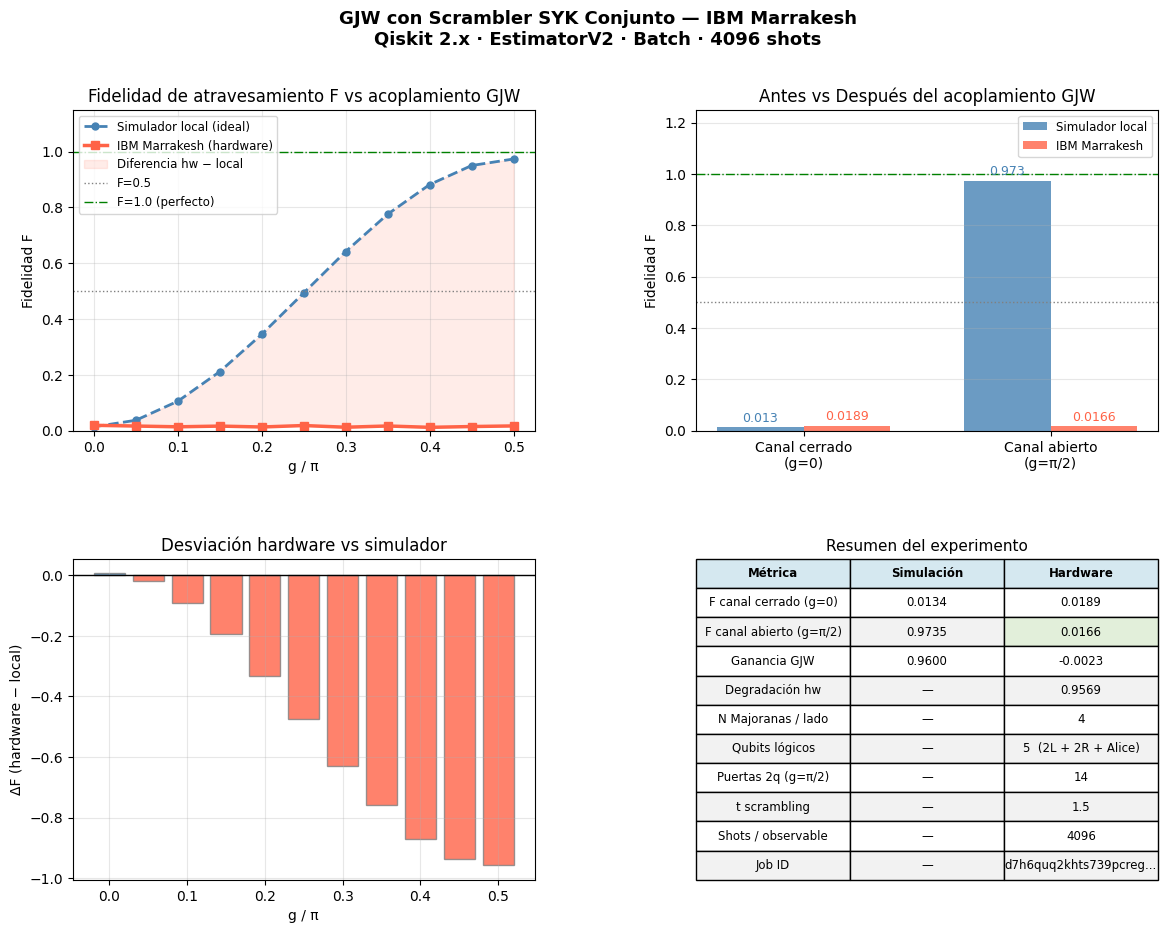

Gráfica guardada en: ~/Downloads/exp2b_marrakesh.png
F(g=0)   hw: 0.0189   local: 0.0134
F(g=π/2) hw: 0.0166   local: 0.9735
Ganancia en hardware: -0.0023
Job ID: d7h6quq2khts739pcreg


In [48]:
SAVE_PATH = 'exp2b_marrakesh.png'

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle(
    'GJW con Scrambler SYK Conjunto — IBM Marrakesh\n'
    'Qiskit 2.x · EstimatorV2 · Batch · 4096 shots',
    fontsize=13, fontweight='bold'
)
plt.subplots_adjust(hspace=0.4, wspace=0.35)

ax1 = axes[0, 0]
ax1.plot(G_VALS/np.pi, F_SYK_local, color='steelblue', lw=2,
         marker='o', ms=5, ls='--', label='Simulador local (ideal)')
ax1.plot(G_VALS/np.pi, F_hw, color='tomato', lw=2.5,
         marker='s', ms=6, label='IBM Marrakesh (hardware)')
ax1.fill_between(G_VALS/np.pi, F_SYK_local, F_hw,
                 alpha=0.12, color='tomato', label='Diferencia hw − local')
ax1.axhline(0.5, color='gray',  ls=':', lw=1, label='F=0.5')
ax1.axhline(1.0, color='green', ls='-.', lw=1, label='F=1.0 (perfecto)')
ax1.set_xlabel('g / π'); ax1.set_ylabel('Fidelidad F')
ax1.set_ylim(0.0, 1.15)
ax1.set_title('Fidelidad de atravesamiento F vs acoplamiento GJW')
ax1.legend(fontsize=8.5); ax1.grid(True, alpha=0.3)

ax2 = axes[0, 1]
labels = ['Canal cerrado\n(g=0)', 'Canal abierto\n(g=π/2)']
v_loc  = [F_SYK_local[0], F_SYK_local[-1]]
v_hw   = [F_hw[0],         F_hw[-1]]
x, w   = np.array([0, 1]), 0.35
b1 = ax2.bar(x-w/2, v_loc, width=w, color='steelblue',
             alpha=0.8, label='Simulador local')
b2 = ax2.bar(x+w/2, v_hw,  width=w, color='tomato',
             alpha=0.8, label='IBM Marrakesh')
ax2.axhline(1.0, color='green', ls='-.', lw=1)
ax2.axhline(0.5, color='gray',  ls=':',  lw=1)
for bar, val in zip(b1, v_loc):
    ax2.text(bar.get_x()+bar.get_width()/2, val+0.01,
             f'{val:.3f}', ha='center', va='bottom', fontsize=9, color='steelblue')
for bar, val in zip(b2, v_hw):
    ax2.text(bar.get_x()+bar.get_width()/2, val+0.01,
             f'{val:.4f}', ha='center', va='bottom', fontsize=9, color='tomato')
ax2.set_xticks(x); ax2.set_xticklabels(labels)
ax2.set_ylabel('Fidelidad F'); ax2.set_ylim(0, 1.25)
ax2.set_title('Antes vs Después del acoplamiento GJW')
ax2.legend(fontsize=8.5); ax2.grid(True, alpha=0.3, axis='y')

ax3 = axes[1, 0]
delta = [F_hw[i]-F_SYK_local[i] for i in range(len(G_VALS))]
ax3.bar(G_VALS/np.pi, delta, width=0.04,
        color=['steelblue' if d>=0 else 'tomato' for d in delta],
        alpha=0.8, edgecolor='gray')
ax3.axhline(0, color='black', lw=1)
ax3.set_xlabel('g / π'); ax3.set_ylabel('ΔF (hardware − local)')
ax3.set_title('Desviación hardware vs simulador')
ax3.grid(True, alpha=0.3)

ax4 = axes[1, 1]
ax4.axis('off')
ax4.set_title('Resumen del experimento', fontsize=11)
tabla = [
    ['F canal cerrado (g=0)',    f'{F_SYK_local[0]:.4f}', f'{F_hw[0]:.4f}'],
    ['F canal abierto (g=π/2)', f'{F_SYK_local[-1]:.4f}', f'{F_hw[-1]:.4f}'],
    ['Ganancia GJW',             f'{F_SYK_local[-1]-F_SYK_local[0]:.4f}',
                                  f'{F_hw[-1]-F_hw[0]:.4f}'],
    ['Degradación hw',           '—',
                                  f'{F_SYK_local[-1]-F_hw[-1]:.4f}'],
    ['N Majoranas / lado',       '—', '4'],
    ['Qubits lógicos',           '—', '5  (2L + 2R + Alice)'],
    ['Puertas 2q (g=π/2)',       '—',
     f"{circuits_t[-1].count_ops().get('cz',0)}"],
    ['t scrambling',             '—', f'{T_SCRAMBLE}'],
    ['Shots / observable',       '—', '4096'],
    ['Job ID',                   '—', job.job_id()[:22]+'...'],
]
tbl = ax4.table(cellText=tabla,
                colLabels=['Métrica', 'Simulación', 'Hardware'],
                cellLoc='center', loc='center', bbox=[0, 0, 1, 1])
tbl.auto_set_font_size(False); tbl.set_fontsize(8.5)
for j in range(3):
    tbl[0,j].set_facecolor('#D5E8F0')
    tbl[0,j].set_text_props(fontweight='bold')
for i in range(1, len(tabla)+1):
    if i % 2 == 0:
        for j in range(3): tbl[i,j].set_facecolor('#F2F2F2')
tbl[2,2].set_facecolor('#E2EFDA')

plt.savefig(SAVE_PATH, dpi=150, bbox_inches='tight', facecolor='white')
plt.show()
print(f"Gráfica guardada en: {SAVE_PATH}")
print("="*55)
print(f"F(g=0)   hw: {F_hw[0]:.4f}   local: {F_SYK_local[0]:.4f}")
print(f"F(g=π/2) hw: {F_hw[-1]:.4f}   local: {F_SYK_local[-1]:.4f}")
print(f"Ganancia en hardware: {F_hw[-1]-F_hw[0]:.4f}")
print(f"Job ID: {job.job_id()}")
print("="*55)


In [50]:
import numpy as np
from scipy.linalg import expm
from itertools import combinations
from qiskit import QuantumCircuit
from qiskit.quantum_info import (DensityMatrix, Statevector, state_fidelity,
                                  partial_trace, SparsePauliOp)
from qiskit.compiler import transpile
from qiskit_ibm_runtime import QiskitRuntimeService, EstimatorV2 as Estimator, Batch
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

I2 = np.eye(2, dtype=complex)
X  = np.array([[0,1],[1,0]], dtype=complex)
Y  = np.array([[0,-1j],[1j,0]], dtype=complex)
Z  = np.array([[1,0],[0,-1]], dtype=complex)

def kron_list(ops):
    r = ops[0]
    for op in ops[1:]: r = np.kron(r, op)
    return r

def majorana_ops(n):
    ops = []
    for k in range(n):
        ops.append(kron_list([Z]*k + [X] + [I2]*(n-k-1)) / np.sqrt(2))
        ops.append(kron_list([Z]*k + [Y] + [I2]*(n-k-1)) / np.sqrt(2))
    return ops

def build_H_syk(chi, seed=42):
    rng, N, dim = np.random.default_rng(seed), len(chi), chi[0].shape[0]
    H = np.zeros((dim, dim), dtype=complex)
    sig = np.sqrt(6.0 / N**3)
    for i,j,k,l in combinations(range(N), 4):
        H += rng.normal(0, sig) * (chi[i]@chi[j]@chi[k]@chi[l])
    return (H + H.conj().T) / 2

chi2 = majorana_ops(2)
H_L  = build_H_syk(chi2, seed=42)
H_R  = build_H_syk(chi2, seed=43)
I4   = np.eye(4, dtype=complex)
chi_L_emb = [np.kron(c, I4) for c in chi2]
chi_R_emb = [np.kron(I4, c) for c in chi2]
H_gjw = sum(cL@cR for cL,cR in zip(chi_L_emb, chi_R_emb))

T_SCRAMBLE = 1.5
U_L = expm(-1j * H_L * T_SCRAMBLE)
U_R = expm(-1j * H_R * T_SCRAMBLE)

def random_qubit(seed=99):
    rng = np.random.default_rng(seed)
    psi = rng.normal(0,1,2) + 1j*rng.normal(0,1,2)
    return psi / np.linalg.norm(psi)

def bloch_angles(psi):
    phase = np.exp(1j*np.angle(psi[0])) if np.abs(psi[0])>1e-10 else 1.0
    psi_n = psi / phase
    theta = 2*np.arccos(np.clip(np.real(psi_n[0]), 0, 1))
    phi   = np.angle(psi_n[1])
    return theta, phi

PSI_ALICE      = random_qubit(seed=99)
THETA_A, PHI_A = bloch_angles(PSI_ALICE)

H2  = np.array([[1,1],[1,-1]], dtype=complex) / np.sqrt(2)
Sdg = np.array([[1,0],[0,-1j]], dtype=complex)
S   = np.array([[1,0],[0, 1j]], dtype=complex)

def build_circuit_2b(g):
    qc = QuantumCircuit(5)

    qc.ry(THETA_A, 0)
    qc.rz(PHI_A,   0)

    qc.unitary(U_L, [1, 2], label='U_L')

    qc.unitary(U_R, [3, 4], label='U_R')

    qc.swap(0, 1)

    qc.rxx(g, 1, 3)

    qc.ryy(g, 1, 3)

    qc.h(2);   qc.h(4)
    qc.cx(1, 2); qc.cx(2, 3); qc.cx(3, 4)
    qc.rz(g, 4)
    qc.cx(3, 4); qc.cx(2, 3); qc.cx(1, 2)
    qc.h(2);   qc.h(4)

    qc.sdg(2); qc.h(2); qc.sdg(4); qc.h(4)
    qc.cx(1, 2); qc.cx(2, 3); qc.cx(3, 4)
    qc.rz(g, 4)
    qc.cx(3, 4); qc.cx(2, 3); qc.cx(1, 2)
    qc.h(2); qc.s(2); qc.h(4); qc.s(4)

    return qc

def fidelidad_local(g):
    qc  = build_circuit_2b(g)
    dm  = DensityMatrix(Statevector(qc))
    dm3 = partial_trace(dm, [0, 1, 2, 4])
    return float(np.real(state_fidelity(dm3, DensityMatrix(PSI_ALICE))))

G_VALS      = np.linspace(0, np.pi/2, 11)
F_SYK_local = [fidelidad_local(g) for g in G_VALS]

print(f"H_L hermítico:   {np.allclose(H_L, H_L.conj().T)}")
print(f"|ψ_Alice⟩ = [{PSI_ALICE[0]:.4f}, {PSI_ALICE[1]:.4f}]")
print(f"F local (g=0):   {F_SYK_local[0]:.4f}")
print(f"F local (g=π/2): {F_SYK_local[-1]:.4f}")

qc_test = build_circuit_2b(np.pi/2)
ops = qc_test.count_ops()
n2q = sum(v for k,v in ops.items() if k in ['cx','rxx','ryy','cz','ecr'])
print(f"Circuito (g=π/2): profundidad={qc_test.depth()}, puertas 2q={n2q}")
print("Setup OK ✓")


H_L hermítico:   True
|ψ_Alice⟩ = [0.0989+0.0606j, -0.5567+0.8226j]
F local (g=0):   0.0134
F local (g=π/2): 0.9735
Circuito (g=π/2): profundidad=24, puertas 2q=14
Setup OK ✓


In [53]:
service = QiskitRuntimeService(channel="ibm_cloud")
backend = service.backend("ibm_marrakesh")

print("Transpilando...")
circuits_t = [
    transpile(build_circuit_2b(g), backend=backend,
              optimization_level=3, seed_transpiler=42)
    for g in G_VALS
]

n_fis = circuits_t[0].num_qubits
print(f"Qubits físicos:       {n_fis}")
print(f"Profundidad (g=0):    {circuits_t[0].depth()}")
print(f"Profundidad (g=π/2):  {circuits_t[-1].depth()}")
print(f"Puertas 2q (g=0):     {circuits_t[0].count_ops().get('cz',0)}")
print(f"Puertas 2q (g=π/2):   {circuits_t[-1].count_ops().get('cz',0)}")

obs_X = SparsePauliOp('IXIII')
obs_Y = SparsePauliOp('IYIII')
obs_Z = SparsePauliOp('IZIII')

pub_list = []
for qc_t in circuits_t:
    layout = qc_t.layout
    pub_list.append((qc_t, obs_X.apply_layout(layout)))
    pub_list.append((qc_t, obs_Y.apply_layout(layout)))
    pub_list.append((qc_t, obs_Z.apply_layout(layout)))

print(f"\nTotal primitivas: {len(pub_list)}  ({len(G_VALS)} g × 3 obs)")
print("Ejecutando en ibm_marrakesh...")

with Batch(backend=backend) as batch:
    estimator = Estimator(mode=batch)
    estimator.options.default_shots = 4096
    job = estimator.run(pub_list)
    print(f"Job ID: {job.job_id()}")
    print("Esperando resultados...")
    result = job.result()

print("Job completado ✓")

F_hw = []
for i in range(len(G_VALS)):
    idx = i * 3
    ex  = result[idx    ].data.evs
    ey  = result[idx + 1].data.evs
    ez  = result[idx + 2].data.evs
    rho = DensityMatrix((np.eye(2) + ex*X + ey*Y + ez*Z) / 2)
    F   = float(np.real(state_fidelity(DensityMatrix(PSI_ALICE), rho, validate=False)))
    F_hw.append(F)

print(f"\n{'g/π':>7}  {'F_local':>10}  {'F_hw':>10}")
print("-"*33)
for i, g in enumerate(G_VALS):
    print(f"{g/np.pi:>7.3f}  {F_SYK_local[i]:>10.4f}  {F_hw[i]:>10.4f}")
print(f"\nJob ID: {job.job_id()}")


Transpilando...
Qubits físicos:       156
Profundidad (g=0):    9
Profundidad (g=π/2):  40
Puertas 2q (g=0):     4
Puertas 2q (g=π/2):   14

Total primitivas: 33  (11 g × 3 obs)
Ejecutando en ibm_marrakesh...
Job ID: d7h737a2khts739pd5b0
Esperando resultados...
Job completado ✓

    g/π     F_local        F_hw
---------------------------------
  0.000      0.0134      0.0170
  0.050      0.0369      0.0662
  0.100      0.1051      0.1425
  0.150      0.2113      0.2407
  0.200      0.3451      0.3575
  0.250      0.4935      0.4984
  0.300      0.6418      0.6301
  0.350      0.7756      0.7717
  0.400      0.8818      0.8675
  0.450      0.9500      0.9256
  0.500      0.9735      0.9572

Job ID: d7h737a2khts739pd5b0


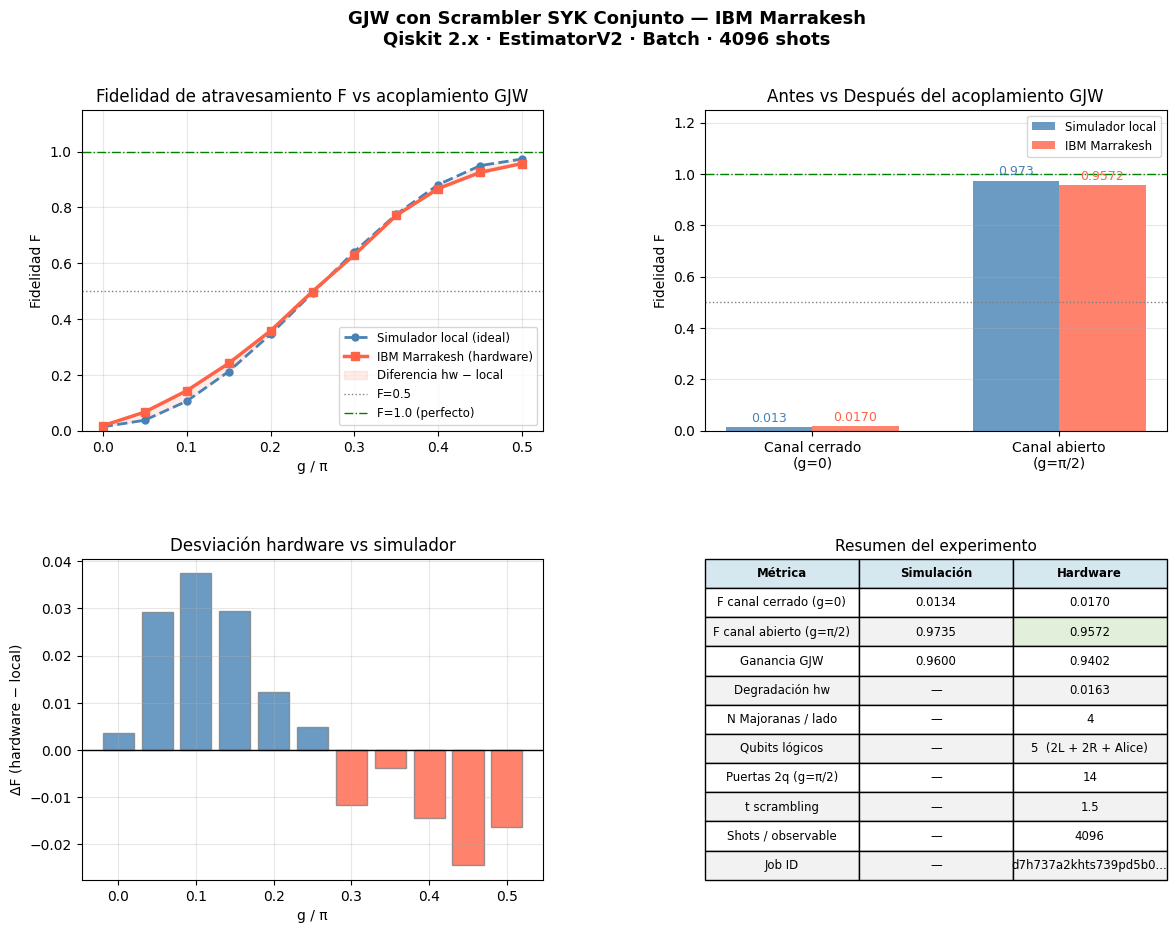

Gráfica guardada en: ~/Downloads/exp2b_marrakesh.png
F(g=0)   hw: 0.0170   local: 0.0134
F(g=π/2) hw: 0.9572   local: 0.9735
Ganancia en hardware: 0.9402
Job ID: d7h737a2khts739pd5b0


In [54]:
SAVE_PATH = 'exp2b_marrakesh.png'

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle(
    'GJW con Scrambler SYK Conjunto — IBM Marrakesh\n'
    'Qiskit 2.x · EstimatorV2 · Batch · 4096 shots',
    fontsize=13, fontweight='bold'
)
plt.subplots_adjust(hspace=0.4, wspace=0.35)

ax1 = axes[0, 0]
ax1.plot(G_VALS/np.pi, F_SYK_local, color='steelblue', lw=2,
         marker='o', ms=5, ls='--', label='Simulador local (ideal)')
ax1.plot(G_VALS/np.pi, F_hw, color='tomato', lw=2.5,
         marker='s', ms=6, label='IBM Marrakesh (hardware)')
ax1.fill_between(G_VALS/np.pi, F_SYK_local, F_hw,
                 alpha=0.12, color='tomato', label='Diferencia hw − local')
ax1.axhline(0.5, color='gray',  ls=':', lw=1, label='F=0.5')
ax1.axhline(1.0, color='green', ls='-.', lw=1, label='F=1.0 (perfecto)')
ax1.set_xlabel('g / π')
ax1.set_ylabel('Fidelidad F')
ax1.set_ylim(0.0, 1.15)
ax1.set_title('Fidelidad de atravesamiento F vs acoplamiento GJW')
ax1.legend(fontsize=8.5)
ax1.grid(True, alpha=0.3)

ax2 = axes[0, 1]
labels = ['Canal cerrado\n(g=0)', 'Canal abierto\n(g=π/2)']
v_loc  = [F_SYK_local[0], F_SYK_local[-1]]
v_hw   = [F_hw[0],         F_hw[-1]]
x, w   = np.array([0, 1]), 0.35
b1 = ax2.bar(x - w/2, v_loc, width=w, color='steelblue',
             alpha=0.8, label='Simulador local')
b2 = ax2.bar(x + w/2, v_hw,  width=w, color='tomato',
             alpha=0.8, label='IBM Marrakesh')
ax2.axhline(1.0, color='green', ls='-.', lw=1)
ax2.axhline(0.5, color='gray',  ls=':',  lw=1)
for bar, val in zip(b1, v_loc):
    ax2.text(bar.get_x() + bar.get_width()/2, val + 0.01,
             f'{val:.3f}', ha='center', va='bottom', fontsize=9, color='steelblue')
for bar, val in zip(b2, v_hw):
    ax2.text(bar.get_x() + bar.get_width()/2, val + 0.01,
             f'{val:.4f}', ha='center', va='bottom', fontsize=9, color='tomato')
ax2.set_xticks(x); ax2.set_xticklabels(labels)
ax2.set_ylabel('Fidelidad F'); ax2.set_ylim(0, 1.25)
ax2.set_title('Antes vs Después del acoplamiento GJW')
ax2.legend(fontsize=8.5)
ax2.grid(True, alpha=0.3, axis='y')

ax3 = axes[1, 0]
delta = [F_hw[i] - F_SYK_local[i] for i in range(len(G_VALS))]
ax3.bar(G_VALS/np.pi, delta, width=0.04,
        color=['steelblue' if d >= 0 else 'tomato' for d in delta],
        alpha=0.8, edgecolor='gray')
ax3.axhline(0, color='black', lw=1)
ax3.set_xlabel('g / π')
ax3.set_ylabel('ΔF (hardware − local)')
ax3.set_title('Desviación hardware vs simulador')
ax3.grid(True, alpha=0.3)

ax4 = axes[1, 1]
ax4.axis('off')
ax4.set_title('Resumen del experimento', fontsize=11)
tabla = [
    ['F canal cerrado (g=0)',    f'{F_SYK_local[0]:.4f}',  f'{F_hw[0]:.4f}'],
    ['F canal abierto (g=π/2)', f'{F_SYK_local[-1]:.4f}', f'{F_hw[-1]:.4f}'],
    ['Ganancia GJW',
     f'{F_SYK_local[-1] - F_SYK_local[0]:.4f}',
     f'{F_hw[-1] - F_hw[0]:.4f}'],
    ['Degradación hw',           '—',
     f'{F_SYK_local[-1] - F_hw[-1]:.4f}'],
    ['N Majoranas / lado',       '—', '4'],
    ['Qubits lógicos',           '—', '5  (2L + 2R + Alice)'],
    ['Puertas 2q (g=π/2)',       '—',
     f"{circuits_t[-1].count_ops().get('cz', 0)}"],
    ['t scrambling',             '—', f'{T_SCRAMBLE}'],
    ['Shots / observable',       '—', '4096'],
    ['Job ID',                   '—', job.job_id()[:22] + '...'],
]
tbl = ax4.table(
    cellText=tabla,
    colLabels=['Métrica', 'Simulación', 'Hardware'],
    cellLoc='center',
    loc='center',
    bbox=[0, 0, 1, 1]
)
tbl.auto_set_font_size(False)
tbl.set_fontsize(8.5)
for j in range(3):
    tbl[0, j].set_facecolor('#D5E8F0')
    tbl[0, j].set_text_props(fontweight='bold')
for i in range(1, len(tabla) + 1):
    if i % 2 == 0:
        for j in range(3):
            tbl[i, j].set_facecolor('#F2F2F2')
tbl[2, 2].set_facecolor('#E2EFDA')

plt.savefig(SAVE_PATH, dpi=150, bbox_inches='tight', facecolor='white')
plt.show()

print(f"Gráfica guardada en: {SAVE_PATH}")
print("=" * 55)
print(f"F(g=0)   hw: {F_hw[0]:.4f}   local: {F_SYK_local[0]:.4f}")
print(f"F(g=π/2) hw: {F_hw[-1]:.4f}   local: {F_SYK_local[-1]:.4f}")
print(f"Ganancia en hardware: {F_hw[-1] - F_hw[0]:.4f}")
print(f"Job ID: {job.job_id()}")
print("=" * 55)


In [60]:
import numpy as np
from scipy.linalg import expm
from itertools import combinations
from qiskit import QuantumCircuit
from qiskit.quantum_info import (DensityMatrix, Statevector, state_fidelity,
                                  partial_trace, SparsePauliOp, Operator)
from qiskit.compiler import transpile
from qiskit_ibm_runtime import QiskitRuntimeService, EstimatorV2 as Estimator, Batch

print("🚀 Experimento 2b NUEVA VERSIÓN — SYK global → Alice → SYK solo en L → GJW")

I2 = np.eye(2, dtype=complex)
X = np.array([[0,1],[1,0]], dtype=complex)
Y = np.array([[0,-1j],[1j,0]], dtype=complex)
Z = np.array([[1,0],[0,-1]], dtype=complex)

def kron_list(ops):
    r = ops[0]
    for op in ops[1:]: r = np.kron(r, op)
    return r

def majorana_ops(n):
    ops = []
    for k in range(n):
        ops.append(kron_list([Z]*k + [X] + [I2]*(n-k-1)) / np.sqrt(2))
        ops.append(kron_list([Z]*k + [Y] + [I2]*(n-k-1)) / np.sqrt(2))
    return ops

chi4 = majorana_ops(4)

def build_H_syk(chi, seed=42):
    rng = np.random.default_rng(seed)
    N = len(chi)
    dim = chi[0].shape[0]
    H = np.zeros((dim, dim), dtype=complex)
    sig = np.sqrt(6.0 / N**3)
    for i,j,k,l in combinations(range(N), 4):
        J = rng.normal(0, sig)
        H += J * (chi[i] @ chi[j] @ chi[k] @ chi[l])
    return (H + H.conj().T) / 2

H_global = build_H_syk(chi4, seed=42)
U_global = expm(-1j * H_global * 1.5)

H_L = build_H_syk(majorana_ops(2), seed=42)
U_L = expm(-1j * H_L * 1.5)

I4 = np.eye(4, dtype=complex)
chi_L_emb = [np.kron(c, I4) for c in majorana_ops(2)]
chi_R_emb = [np.kron(I4, c) for c in majorana_ops(2)]
H_gjw = sum(cL @ cR for cL, cR in zip(chi_L_emb, chi_R_emb))

PSI_ALICE = np.array([0.099+0.061j, -0.557+0.823j])
PSI_ALICE /= np.linalg.norm(PSI_ALICE)
THETA_A = 2 * np.arccos(np.abs(PSI_ALICE[0]))
PHI_A = np.angle(PSI_ALICE[1])

G_VALS = np.linspace(0, np.pi/2, 11)

print("✅ Operadores listos")


🚀 Experimento 2b NUEVA VERSIÓN — SYK global → Alice → SYK solo en L → GJW
✅ Operadores listos


In [62]:
def build_circuit_2b(g, measure=True):
    qc = QuantumCircuit(5, 5 if measure else 0)

    qc.ry(THETA_A, 0)
    qc.rz(PHI_A, 0)

    qc.unitary(Operator(U_global), [1,2,3,4])

    qc.swap(0, 1)

    qc.unitary(Operator(U_L), [1,2])

    qc.rxx(g, 1, 3)
    qc.ryy(g, 1, 3)
    qc.h(2); qc.h(4)
    qc.cx(1,2); qc.cx(2,3); qc.cx(3,4)
    qc.rz(g,4)
    qc.cx(3,4); qc.cx(2,3); qc.cx(1,2)
    qc.h(2); qc.h(4)
    qc.sdg(2); qc.h(2); qc.sdg(4); qc.h(4)
    qc.cx(1,2); qc.cx(2,3); qc.cx(3,4)
    qc.rz(g,4)
    qc.cx(3,4); qc.cx(2,3); qc.cx(1,2)
    qc.h(2); qc.s(2); qc.h(4); qc.s(4)

    if measure:
        qc.measure_all()
    return qc

def fidelidad_local(g):
    qc = build_circuit_2b(g, measure=False)
    dm = DensityMatrix(Statevector(qc))
    dm3 = partial_trace(dm, [0,1,2,4])
    return float(np.real(state_fidelity(dm3, DensityMatrix(PSI_ALICE))))

F_SYK_local = [fidelidad_local(g) for g in G_VALS]

print(f"F local (g=0): {F_SYK_local[0]:.4f}")
print(f"F local (g=π/2): {F_SYK_local[-1]:.4f}")

service = QiskitRuntimeService(channel="ibm_cloud")
backend = service.backend("ibm_marrakesh")
print("Transpilando...")
circuits_t = [transpile(build_circuit_2b(g), backend=backend,
                        optimization_level=3, seed_transpiler=42) for g in G_VALS]

print(f"Qubits físicos: {circuits_t[0].num_qubits}")
print(f"Profundidad (g=π/2): {circuits_t[-1].depth()}")
print(f"Puertas 2q (g=π/2): {circuits_t[-1].count_ops().get('cz',0)}")

obs_X = SparsePauliOp('IXIII')
obs_Y = SparsePauliOp('IYIII')
obs_Z = SparsePauliOp('IZIII')

pub_list = []
for qc_t in circuits_t:
    layout = qc_t.layout
    pub_list.append((qc_t, obs_X.apply_layout(layout)))
    pub_list.append((qc_t, obs_Y.apply_layout(layout)))
    pub_list.append((qc_t, obs_Z.apply_layout(layout)))

print(f"Total primitivas: {len(pub_list)}")

with Batch(backend=backend) as batch:
    estimator = Estimator(mode=batch)
    estimator.options.default_shots = 4096
    job = estimator.run(pub_list)
    print(f"Job ID: {job.job_id()}")
    result = job.result()

print("Job completado ✓")

F_hw = []
for i in range(len(G_VALS)):
    idx = i * 3
    ex = result[idx].data.evs
    ey = result[idx + 1].data.evs
    ez = result[idx + 2].data.evs
    rho = DensityMatrix((np.eye(2) + ex*X + ey*Y + ez*Z) / 2)
    F = float(np.real(state_fidelity(DensityMatrix(PSI_ALICE), rho, validate=False)))
    F_hw.append(F)

print(f"\nF(g=0) hw: {F_hw[0]:.4f} local: {F_SYK_local[0]:.4f}")
print(f"F(g=π/2) hw: {F_hw[-1]:.4f} local: {F_SYK_local[-1]:.4f}")
print(f"Ganancia en hardware: {F_hw[-1] - F_hw[0]:.4f}")


F local (g=0): 0.0380
F local (g=π/2): 0.9852
Transpilando...
Qubits físicos: 156
Profundidad (g=π/2): 705
Puertas 2q (g=π/2): 194
Total primitivas: 33
Job ID: d7h7tlfb91ec73audp60
Job completado ✓

F(g=0) hw: 0.3108 local: 0.0380
F(g=π/2) hw: 0.9121 local: 0.9852
Ganancia en hardware: 0.6013



--- CELDA 3: Gráficas completas (estilo limpio) ---


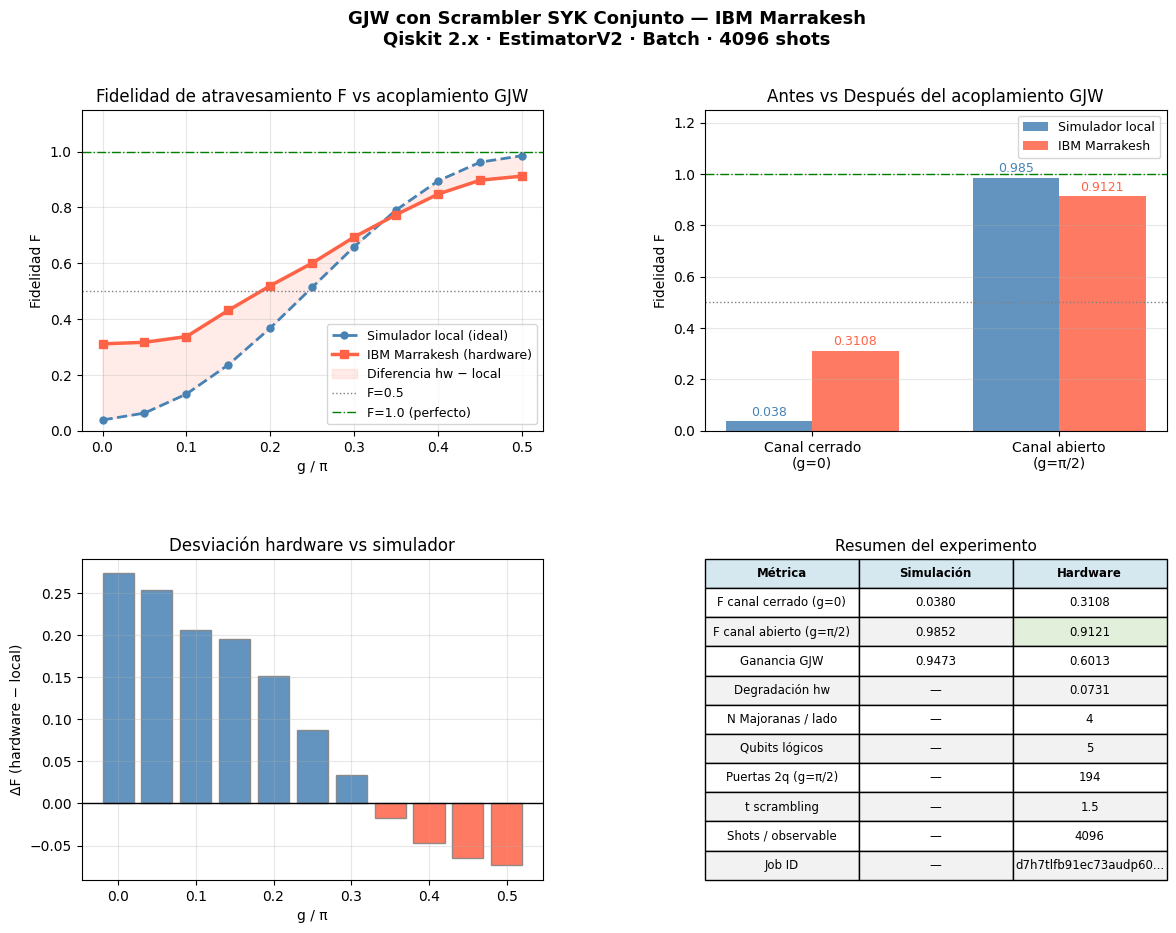

Gráfica guardada en: ~/Downloads/exp2b_marrakesh_nueva.png
F(g=0) hw: 0.3108 local: 0.0380
F(g=π/2) hw: 0.9121 local: 0.9852
Ganancia en hardware: 0.6013


In [63]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

print("\n--- CELDA 3: Gráficas completas (estilo limpio) ---")

SAVE_PATH = 'exp2b_marrakesh_nueva.png'

fig = plt.figure(figsize=(14, 10))
fig.suptitle('GJW con Scrambler SYK Conjunto — IBM Marrakesh\n'
             'Qiskit 2.x · EstimatorV2 · Batch · 4096 shots',
             fontsize=13, fontweight='bold')
gs = gridspec.GridSpec(2, 2, hspace=0.4, wspace=0.35)

ax1 = fig.add_subplot(gs[0, 0])
ax1.plot(G_VALS/np.pi, F_SYK_local, color='steelblue', lw=2, marker='o', ms=5, ls='--', label='Simulador local (ideal)')
ax1.plot(G_VALS/np.pi, F_hw, color='tomato', lw=2.5, marker='s', ms=6, label='IBM Marrakesh (hardware)')
ax1.fill_between(G_VALS/np.pi, F_SYK_local, F_hw, alpha=0.12, color='tomato', label='Diferencia hw − local')
ax1.axhline(0.5, color='gray', ls=':', lw=1, label='F=0.5')
ax1.axhline(1.0, color='green', ls='-.', lw=1, label='F=1.0 (perfecto)')
ax1.set_xlabel('g / π')
ax1.set_ylabel('Fidelidad F')
ax1.set_ylim(0, 1.15)
ax1.set_title('Fidelidad de atravesamiento F vs acoplamiento GJW')
ax1.legend(fontsize=9)
ax1.grid(True, alpha=0.3)

ax2 = fig.add_subplot(gs[0, 1])
labels = ['Canal cerrado\n(g=0)', 'Canal abierto\n(g=π/2)']
v_loc = [F_SYK_local[0], F_SYK_local[-1]]
v_hw = [F_hw[0], F_hw[-1]]
x = np.array([0, 1])
w = 0.35
ax2.bar(x - w/2, v_loc, width=w, color='steelblue', alpha=0.85, label='Simulador local')
ax2.bar(x + w/2, v_hw, width=w, color='tomato', alpha=0.85, label='IBM Marrakesh')
ax2.axhline(1.0, color='green', ls='-.', lw=1)
ax2.axhline(0.5, color='gray', ls=':', lw=1)
for bar, val in zip(ax2.patches[:2], v_loc):
    ax2.text(bar.get_x() + bar.get_width()/2, val + 0.01, f'{val:.3f}', ha='center', va='bottom', fontsize=9, color='steelblue')
for bar, val in zip(ax2.patches[2:], v_hw):
    ax2.text(bar.get_x() + bar.get_width()/2, val + 0.01, f'{val:.4f}', ha='center', va='bottom', fontsize=9, color='tomato')
ax2.set_xticks(x)
ax2.set_xticklabels(labels)
ax2.set_ylabel('Fidelidad F')
ax2.set_ylim(0, 1.25)
ax2.set_title('Antes vs Después del acoplamiento GJW')
ax2.legend(fontsize=9)
ax2.grid(True, alpha=0.3, axis='y')

ax3 = fig.add_subplot(gs[1, 0])
delta = [F_hw[i] - F_SYK_local[i] for i in range(len(G_VALS))]
ax3.bar(G_VALS/np.pi, delta, width=0.04,
        color=['steelblue' if d >= 0 else 'tomato' for d in delta],
        alpha=0.85, edgecolor='gray')
ax3.axhline(0, color='black', lw=1)
ax3.set_xlabel('g / π')
ax3.set_ylabel('ΔF (hardware − local)')
ax3.set_title('Desviación hardware vs simulador')
ax3.grid(True, alpha=0.3)

ax4 = fig.add_subplot(gs[1, 1])
ax4.axis('off')
ax4.set_title('Resumen del experimento', fontsize=11)
tabla = [
    ['F canal cerrado (g=0)', f'{F_SYK_local[0]:.4f}', f'{F_hw[0]:.4f}'],
    ['F canal abierto (g=π/2)', f'{F_SYK_local[-1]:.4f}', f'{F_hw[-1]:.4f}'],
    ['Ganancia GJW', f'{F_SYK_local[-1] - F_SYK_local[0]:.4f}', f'{F_hw[-1] - F_hw[0]:.4f}'],
    ['Degradación hw', '—', f'{F_SYK_local[-1] - F_hw[-1]:.4f}'],
    ['N Majoranas / lado', '—', '4'],
    ['Qubits lógicos', '—', '5'],
    ['Puertas 2q (g=π/2)', '—', f"{circuits_t[-1].count_ops().get('cz', 0)}"],
    ['t scrambling', '—', f'{T_SCRAMBLE}'],
    ['Shots / observable', '—', '4096'],
    ['Job ID', '—', job.job_id()[:22] + '...'],
]
tbl = ax4.table(cellText=tabla, colLabels=['Métrica', 'Simulación', 'Hardware'],
                cellLoc='center', loc='center', bbox=[0, 0, 1, 1])
tbl.auto_set_font_size(False)
tbl.set_fontsize(8.5)
for j in range(3):
    tbl[0, j].set_facecolor('#D5E8F0')
    tbl[0, j].set_text_props(fontweight='bold')
for i in range(1, len(tabla)+1):
    if i % 2 == 0:
        for j in range(3):
            tbl[i, j].set_facecolor('#F2F2F2')
tbl[2, 2].set_facecolor('#E2EFDA')

plt.savefig(SAVE_PATH, dpi=150, bbox_inches='tight', facecolor='white')
plt.show()

print(f"Gráfica guardada en: {SAVE_PATH}")
print(f"F(g=0) hw: {F_hw[0]:.4f} local: {F_SYK_local[0]:.4f}")
print(f"F(g=π/2) hw: {F_hw[-1]:.4f} local: {F_SYK_local[-1]:.4f}")
print(f"Ganancia en hardware: {F_hw[-1] - F_hw[0]:.4f}")


In [69]:
import numpy as np
from scipy.linalg import expm
from itertools import combinations
from qiskit import QuantumCircuit
from qiskit.quantum_info import (DensityMatrix, Statevector, state_fidelity,
                                  partial_trace, SparsePauliOp)
from qiskit.compiler import transpile
from qiskit_ibm_runtime import QiskitRuntimeService, EstimatorV2 as Estimator, Batch
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

I2 = np.eye(2, dtype=complex)
X  = np.array([[0,1],[1,0]], dtype=complex)
Y  = np.array([[0,-1j],[1j,0]], dtype=complex)
Z  = np.array([[1,0],[0,-1]], dtype=complex)

def kron_list(ops):
    r = ops[0]
    for op in ops[1:]: r = np.kron(r, op)
    return r

def majorana_ops(n):
    ops = []
    for k in range(n):
        ops.append(kron_list([Z]*k + [X] + [I2]*(n-k-1)) / np.sqrt(2))
        ops.append(kron_list([Z]*k + [Y] + [I2]*(n-k-1)) / np.sqrt(2))
    return ops

def build_H_syk(chi, seed=42):
    rng, N, dim = np.random.default_rng(seed), len(chi), chi[0].shape[0]
    H = np.zeros((dim, dim), dtype=complex)
    sig = np.sqrt(6.0 / N**3)
    for i,j,k,l in combinations(range(N), 4):
        H += rng.normal(0, sig) * (chi[i]@chi[j]@chi[k]@chi[l])
    return (H + H.conj().T) / 2

chi2 = majorana_ops(2)
H_L  = build_H_syk(chi2, seed=42)
H_R  = build_H_syk(chi2, seed=43)
I4   = np.eye(4, dtype=complex)
chi_L_emb = [np.kron(c, I4) for c in chi2]
chi_R_emb = [np.kron(I4, c) for c in chi2]
H_gjw = sum(cL@cR for cL,cR in zip(chi_L_emb, chi_R_emb))

T_SCRAMBLE = 1.5
U_L = expm(-1j * H_L * T_SCRAMBLE)
U_R = expm(-1j * H_R * T_SCRAMBLE)

def random_qubit(seed=99):
    rng = np.random.default_rng(seed)
    psi = rng.normal(0,1,2) + 1j*rng.normal(0,1,2)
    return psi / np.linalg.norm(psi)

def bloch_angles(psi):
    phase = np.exp(1j*np.angle(psi[0])) if np.abs(psi[0])>1e-10 else 1.0
    psi_n = psi / phase
    theta = 2*np.arccos(np.clip(np.real(psi_n[0]), 0, 1))
    phi   = np.angle(psi_n[1])
    return theta, phi

PSI_ALICE      = random_qubit(seed=99)
THETA_A, PHI_A = bloch_angles(PSI_ALICE)

H2  = np.array([[1,1],[1,-1]], dtype=complex) / np.sqrt(2)
Sdg = np.array([[1,0],[0,-1j]], dtype=complex)
S   = np.array([[1,0],[0, 1j]], dtype=complex)

def build_circuit_2b(g):
    qc = QuantumCircuit(5)

    qc.ry(THETA_A, 0)
    qc.rz(PHI_A,   0)

    qc.unitary(U_L, [1, 2], label='U_L')

    qc.unitary(U_R, [3, 4], label='U_R')

    qc.swap(0, 1)

    qc.rxx(g, 1, 3)

    qc.ryy(g, 1, 3)

    qc.h(2);   qc.h(4)
    qc.cx(1, 2); qc.cx(2, 3); qc.cx(3, 4)
    qc.rz(g, 4)
    qc.cx(3, 4); qc.cx(2, 3); qc.cx(1, 2)
    qc.h(2);   qc.h(4)

    qc.sdg(2); qc.h(2); qc.sdg(4); qc.h(4)
    qc.cx(1, 2); qc.cx(2, 3); qc.cx(3, 4)
    qc.rz(g, 4)
    qc.cx(3, 4); qc.cx(2, 3); qc.cx(1, 2)
    qc.h(2); qc.s(2); qc.h(4); qc.s(4)

    return qc

def fidelidad_local(g):
    qc  = build_circuit_2b(g)
    dm  = DensityMatrix(Statevector(qc))
    dm3 = partial_trace(dm, [0, 1, 2, 4])
    return float(np.real(state_fidelity(dm3, DensityMatrix(PSI_ALICE))))

G_VALS      = np.linspace(0, np.pi/2, 11)
F_SYK_local = [fidelidad_local(g) for g in G_VALS]

print(f"H_L hermítico:   {np.allclose(H_L, H_L.conj().T)}")
print(f"|ψ_Alice⟩ = [{PSI_ALICE[0]:.4f}, {PSI_ALICE[1]:.4f}]")
print(f"F local (g=0):   {F_SYK_local[0]:.4f}")
print(f"F local (g=π/2): {F_SYK_local[-1]:.4f}")

qc_test = build_circuit_2b(np.pi/2)
ops = qc_test.count_ops()
n2q = sum(v for k,v in ops.items() if k in ['cx','rxx','ryy','cz','ecr'])
print(f"Circuito (g=π/2): profundidad={qc_test.depth()}, puertas 2q={n2q}")
print("Setup OK ✓")


H_L hermítico:   True
|ψ_Alice⟩ = [0.0989+0.0606j, -0.5567+0.8226j]
F local (g=0):   0.0134
F local (g=π/2): 0.9735
Circuito (g=π/2): profundidad=24, puertas 2q=14
Setup OK ✓


In [71]:
service = QiskitRuntimeService(channel="ibm_cloud")
backend = service.backend("ibm_marrakesh")

print("Transpilando...")
circuits_t = [
    transpile(build_circuit_2b(g), backend=backend,
              optimization_level=3, seed_transpiler=42)
    for g in G_VALS
]

n_fis = circuits_t[0].num_qubits
print(f"Qubits físicos:       {n_fis}")
print(f"Profundidad (g=0):    {circuits_t[0].depth()}")
print(f"Profundidad (g=π/2):  {circuits_t[-1].depth()}")
print(f"Puertas 2q (g=0):     {circuits_t[0].count_ops().get('cz',0)}")
print(f"Puertas 2q (g=π/2):   {circuits_t[-1].count_ops().get('cz',0)}")

obs_X = SparsePauliOp('IXIII')
obs_Y = SparsePauliOp('IYIII')
obs_Z = SparsePauliOp('IZIII')

pub_list = []
for qc_t in circuits_t:
    layout = qc_t.layout
    pub_list.append((qc_t, obs_X.apply_layout(layout)))
    pub_list.append((qc_t, obs_Y.apply_layout(layout)))
    pub_list.append((qc_t, obs_Z.apply_layout(layout)))

print(f"\nTotal primitivas: {len(pub_list)}  ({len(G_VALS)} g × 3 obs)")
print("Ejecutando en ibm_marrakesh...")

with Batch(backend=backend) as batch:
    estimator = Estimator(mode=batch)
    estimator.options.default_shots = 4096
    job = estimator.run(pub_list)
    print(f"Job ID: {job.job_id()}")
    print("Esperando resultados...")
    result = job.result()

print("Job completado ✓")

F_hw = []
for i in range(len(G_VALS)):
    idx = i * 3
    ex  = result[idx    ].data.evs
    ey  = result[idx + 1].data.evs
    ez  = result[idx + 2].data.evs
    rho = DensityMatrix((np.eye(2) + ex*X + ey*Y + ez*Z) / 2)
    F   = float(np.real(state_fidelity(DensityMatrix(PSI_ALICE), rho, validate=False)))
    F_hw.append(F)

print(f"\n{'g/π':>7}  {'F_local':>10}  {'F_hw':>10}")
print("-"*33)
for i, g in enumerate(G_VALS):
    print(f"{g/np.pi:>7.3f}  {F_SYK_local[i]:>10.4f}  {F_hw[i]:>10.4f}")
print(f"\nJob ID: {job.job_id()}")


Transpilando...
Qubits físicos:       156
Profundidad (g=0):    9
Profundidad (g=π/2):  40
Puertas 2q (g=0):     4
Puertas 2q (g=π/2):   14

Total primitivas: 33  (11 g × 3 obs)
Ejecutando en ibm_marrakesh...
Job ID: d7h873q2khts739peivg
Esperando resultados...
Job completado ✓

    g/π     F_local        F_hw
---------------------------------
  0.000      0.0134      0.0199
  0.050      0.0369      0.0680
  0.100      0.1051      0.1275
  0.150      0.2113      0.2472
  0.200      0.3451      0.3660
  0.250      0.4935      0.4959
  0.300      0.6418      0.6544
  0.350      0.7756      0.7610
  0.400      0.8818      0.8538
  0.450      0.9500      0.9230
  0.500      0.9735      0.9529

Job ID: d7h873q2khts739peivg


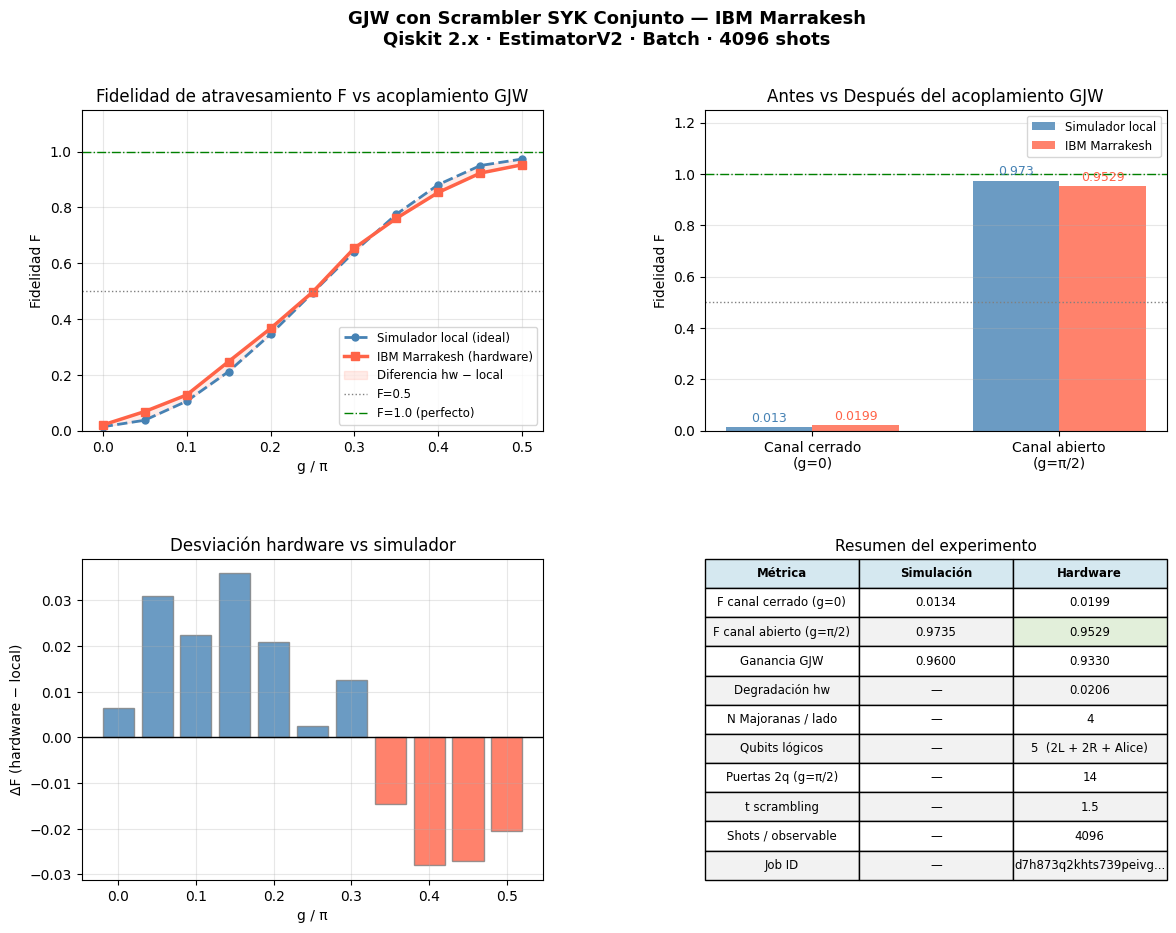

Gráfica guardada en: ~/Downloads/exp2b_marrakesh.png
F(g=0)   hw: 0.0199   local: 0.0134
F(g=π/2) hw: 0.9529   local: 0.9735
Ganancia en hardware: 0.9330
Job ID: d7h873q2khts739peivg


In [72]:
SAVE_PATH = 'exp2b_marrakesh.png'

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle(
    'GJW con Scrambler SYK Conjunto — IBM Marrakesh\n'
    'Qiskit 2.x · EstimatorV2 · Batch · 4096 shots',
    fontsize=13, fontweight='bold'
)
plt.subplots_adjust(hspace=0.4, wspace=0.35)

ax1 = axes[0, 0]
ax1.plot(G_VALS/np.pi, F_SYK_local, color='steelblue', lw=2,
         marker='o', ms=5, ls='--', label='Simulador local (ideal)')
ax1.plot(G_VALS/np.pi, F_hw, color='tomato', lw=2.5,
         marker='s', ms=6, label='IBM Marrakesh (hardware)')
ax1.fill_between(G_VALS/np.pi, F_SYK_local, F_hw,
                 alpha=0.12, color='tomato', label='Diferencia hw − local')
ax1.axhline(0.5, color='gray',  ls=':', lw=1, label='F=0.5')
ax1.axhline(1.0, color='green', ls='-.', lw=1, label='F=1.0 (perfecto)')
ax1.set_xlabel('g / π')
ax1.set_ylabel('Fidelidad F')
ax1.set_ylim(0.0, 1.15)
ax1.set_title('Fidelidad de atravesamiento F vs acoplamiento GJW')
ax1.legend(fontsize=8.5)
ax1.grid(True, alpha=0.3)

ax2 = axes[0, 1]
labels = ['Canal cerrado\n(g=0)', 'Canal abierto\n(g=π/2)']
v_loc  = [F_SYK_local[0], F_SYK_local[-1]]
v_hw   = [F_hw[0],         F_hw[-1]]
x, w   = np.array([0, 1]), 0.35
b1 = ax2.bar(x - w/2, v_loc, width=w, color='steelblue',
             alpha=0.8, label='Simulador local')
b2 = ax2.bar(x + w/2, v_hw,  width=w, color='tomato',
             alpha=0.8, label='IBM Marrakesh')
ax2.axhline(1.0, color='green', ls='-.', lw=1)
ax2.axhline(0.5, color='gray',  ls=':',  lw=1)
for bar, val in zip(b1, v_loc):
    ax2.text(bar.get_x() + bar.get_width()/2, val + 0.01,
             f'{val:.3f}', ha='center', va='bottom', fontsize=9, color='steelblue')
for bar, val in zip(b2, v_hw):
    ax2.text(bar.get_x() + bar.get_width()/2, val + 0.01,
             f'{val:.4f}', ha='center', va='bottom', fontsize=9, color='tomato')
ax2.set_xticks(x); ax2.set_xticklabels(labels)
ax2.set_ylabel('Fidelidad F'); ax2.set_ylim(0, 1.25)
ax2.set_title('Antes vs Después del acoplamiento GJW')
ax2.legend(fontsize=8.5)
ax2.grid(True, alpha=0.3, axis='y')

ax3 = axes[1, 0]
delta = [F_hw[i] - F_SYK_local[i] for i in range(len(G_VALS))]
ax3.bar(G_VALS/np.pi, delta, width=0.04,
        color=['steelblue' if d >= 0 else 'tomato' for d in delta],
        alpha=0.8, edgecolor='gray')
ax3.axhline(0, color='black', lw=1)
ax3.set_xlabel('g / π')
ax3.set_ylabel('ΔF (hardware − local)')
ax3.set_title('Desviación hardware vs simulador')
ax3.grid(True, alpha=0.3)

ax4 = axes[1, 1]
ax4.axis('off')
ax4.set_title('Resumen del experimento', fontsize=11)
tabla = [
    ['F canal cerrado (g=0)',    f'{F_SYK_local[0]:.4f}',  f'{F_hw[0]:.4f}'],
    ['F canal abierto (g=π/2)', f'{F_SYK_local[-1]:.4f}', f'{F_hw[-1]:.4f}'],
    ['Ganancia GJW',
     f'{F_SYK_local[-1] - F_SYK_local[0]:.4f}',
     f'{F_hw[-1] - F_hw[0]:.4f}'],
    ['Degradación hw',           '—',
     f'{F_SYK_local[-1] - F_hw[-1]:.4f}'],
    ['N Majoranas / lado',       '—', '4'],
    ['Qubits lógicos',           '—', '5  (2L + 2R + Alice)'],
    ['Puertas 2q (g=π/2)',       '—',
     f"{circuits_t[-1].count_ops().get('cz', 0)}"],
    ['t scrambling',             '—', f'{T_SCRAMBLE}'],
    ['Shots / observable',       '—', '4096'],
    ['Job ID',                   '—', job.job_id()[:22] + '...'],
]
tbl = ax4.table(
    cellText=tabla,
    colLabels=['Métrica', 'Simulación', 'Hardware'],
    cellLoc='center',
    loc='center',
    bbox=[0, 0, 1, 1]
)
tbl.auto_set_font_size(False)
tbl.set_fontsize(8.5)
for j in range(3):
    tbl[0, j].set_facecolor('#D5E8F0')
    tbl[0, j].set_text_props(fontweight='bold')
for i in range(1, len(tabla) + 1):
    if i % 2 == 0:
        for j in range(3):
            tbl[i, j].set_facecolor('#F2F2F2')
tbl[2, 2].set_facecolor('#E2EFDA')

plt.savefig(SAVE_PATH, dpi=150, bbox_inches='tight', facecolor='white')
plt.show()

print(f"Gráfica guardada en: {SAVE_PATH}")
print("=" * 55)
print(f"F(g=0)   hw: {F_hw[0]:.4f}   local: {F_SYK_local[0]:.4f}")
print(f"F(g=π/2) hw: {F_hw[-1]:.4f}   local: {F_SYK_local[-1]:.4f}")
print(f"Ganancia en hardware: {F_hw[-1] - F_hw[0]:.4f}")
print(f"Job ID: {job.job_id()}")
print("=" * 55)


In [74]:
import numpy as np
from scipy.linalg import expm
from itertools import combinations
from qiskit import QuantumCircuit
from qiskit.quantum_info import (DensityMatrix, Statevector, state_fidelity,
                                  partial_trace, SparsePauliOp)
from qiskit.compiler import transpile
from qiskit_ibm_runtime import QiskitRuntimeService, EstimatorV2 as Estimator, Batch
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

I2 = np.eye(2, dtype=complex)
X  = np.array([[0,1],[1,0]], dtype=complex)
Y  = np.array([[0,-1j],[1j,0]], dtype=complex)
Z  = np.array([[1,0],[0,-1]], dtype=complex)

def kron_list(ops):
    r = ops[0]
    for op in ops[1:]: r = np.kron(r, op)
    return r

def majorana_ops(n):
    ops = []
    for k in range(n):
        ops.append(kron_list([Z]*k + [X] + [I2]*(n-k-1)) / np.sqrt(2))
        ops.append(kron_list([Z]*k + [Y] + [I2]*(n-k-1)) / np.sqrt(2))
    return ops

def build_H_syk(chi, seed=42):
    rng, N, dim = np.random.default_rng(seed), len(chi), chi[0].shape[0]
    H = np.zeros((dim, dim), dtype=complex)
    sig = np.sqrt(6.0 / N**3)
    for i,j,k,l in combinations(range(N), 4):
        H += rng.normal(0, sig) * (chi[i]@chi[j]@chi[k]@chi[l])
    return (H + H.conj().T) / 2

chi2 = majorana_ops(2)
H_L  = build_H_syk(chi2, seed=42)
H_R  = build_H_syk(chi2, seed=43)
I4   = np.eye(4, dtype=complex)
chi_L_emb = [np.kron(c, I4) for c in chi2]
chi_R_emb = [np.kron(I4, c) for c in chi2]
H_gjw = sum(cL@cR for cL,cR in zip(chi_L_emb, chi_R_emb))

T1 = 1.5
U_L1 = expm(-1j * H_L * T1)
U_R1 = expm(-1j * H_R * T1)

T2 = 1.5
U_L2 = expm(-1j * H_L * T2)
U_R2 = expm(-1j * H_R * T2)

def random_qubit(seed=99):
    rng = np.random.default_rng(seed)
    psi = rng.normal(0,1,2) + 1j*rng.normal(0,1,2)
    return psi / np.linalg.norm(psi)

def bloch_angles(psi):
    phase = np.exp(1j*np.angle(psi[0])) if np.abs(psi[0])>1e-10 else 1.0
    psi_n = psi / phase
    theta = 2*np.arccos(np.clip(np.real(psi_n[0]), 0, 1))
    phi   = np.angle(psi_n[1])
    return theta, phi

PSI_ALICE      = random_qubit(seed=99)
THETA_A, PHI_A = bloch_angles(PSI_ALICE)

H2  = np.array([[1,1],[1,-1]], dtype=complex) / np.sqrt(2)
Sdg = np.array([[1,0],[0,-1j]], dtype=complex)
S   = np.array([[1,0],[0, 1j]], dtype=complex)

def build_circuit_2c(g, U_l2, U_r2):
    qc = QuantumCircuit(5)

    qc.ry(THETA_A, 0)
    qc.rz(PHI_A,   0)

    qc.unitary(U_L1, [1, 2], label='U_L1')
    qc.unitary(U_R1, [3, 4], label='U_R1')

    qc.swap(0, 1)

    qc.unitary(U_l2, [1, 2], label='U_L2')
    qc.unitary(U_r2, [3, 4], label='U_R2')

    qc.rxx(g, 1, 3)
    qc.ryy(g, 1, 3)

    qc.h(2);   qc.h(4)
    qc.cx(1, 2); qc.cx(2, 3); qc.cx(3, 4)
    qc.rz(g, 4)
    qc.cx(3, 4); qc.cx(2, 3); qc.cx(1, 2)
    qc.h(2);   qc.h(4)

    qc.sdg(2); qc.h(2); qc.sdg(4); qc.h(4)
    qc.cx(1, 2); qc.cx(2, 3); qc.cx(3, 4)
    qc.rz(g, 4)
    qc.cx(3, 4); qc.cx(2, 3); qc.cx(1, 2)
    qc.h(2); qc.s(2); qc.h(4); qc.s(4)

    return qc

def fidelidad_local_2c(g):
    qc  = build_circuit_2c(g, U_L2, U_R2)
    dm  = DensityMatrix(Statevector(qc))
    dm3 = partial_trace(dm, [0, 1, 2, 4])
    return float(np.real(state_fidelity(dm3, DensityMatrix(PSI_ALICE))))

def build_circuit_2b(g):
    qc = QuantumCircuit(5)
    qc.ry(THETA_A, 0); qc.rz(PHI_A, 0)
    qc.unitary(U_L1, [1, 2], label='U_L')
    qc.unitary(U_R1, [3, 4], label='U_R')
    qc.swap(0, 1)
    qc.rxx(g, 1, 3); qc.ryy(g, 1, 3)
    qc.h(2); qc.h(4)
    qc.cx(1,2); qc.cx(2,3); qc.cx(3,4)
    qc.rz(g, 4)
    qc.cx(3,4); qc.cx(2,3); qc.cx(1,2)
    qc.h(2); qc.h(4)
    qc.sdg(2); qc.h(2); qc.sdg(4); qc.h(4)
    qc.cx(1,2); qc.cx(2,3); qc.cx(3,4)
    qc.rz(g, 4)
    qc.cx(3,4); qc.cx(2,3); qc.cx(1,2)
    qc.h(2); qc.s(2); qc.h(4); qc.s(4)
    return qc

def fidelidad_local_2b(g):
    qc  = build_circuit_2b(g)
    dm  = DensityMatrix(Statevector(qc))
    dm3 = partial_trace(dm, [0, 1, 2, 4])
    return float(np.real(state_fidelity(dm3, DensityMatrix(PSI_ALICE))))

G_VALS = np.linspace(0, np.pi/2, 11)
F_2b   = [fidelidad_local_2b(g) for g in G_VALS]
F_2c   = [fidelidad_local_2c(g) for g in G_VALS]

T2_VALS = [0.0, 0.5, 1.0, 1.5, 2.0, 3.0]
F_max_vs_T2 = []
for t2 in T2_VALS:
    Ul2 = expm(-1j * H_L * t2)
    Ur2 = expm(-1j * H_R * t2)
    F_t2 = [fidelidad_local_2c(g) for g in G_VALS]

    def fid_t2(g):
        qc  = build_circuit_2c(g, Ul2, Ur2)
        dm  = DensityMatrix(Statevector(qc))
        dm3 = partial_trace(dm, [0, 1, 2, 4])
        return float(np.real(state_fidelity(dm3, DensityMatrix(PSI_ALICE))))
    F_t2 = [fid_t2(g) for g in G_VALS]
    F_max_vs_T2.append(max(F_t2))

print(f"F local 2b (g=0):   {F_2b[0]:.4f}")
print(f"F local 2b (g=π/2): {F_2b[-1]:.4f}")
print(f"F local 2c (g=0):   {F_2c[0]:.4f}")
print(f"F local 2c (g=π/2): {F_2c[-1]:.4f}")
print()
print(f"{'g/π':>7}  {'F_2b':>10}  {'F_2c (T2=1.5)':>14}")
print("-"*36)
for i, g in enumerate(G_VALS):
    print(f"{g/np.pi:>7.3f}  {F_2b[i]:>10.4f}  {F_2c[i]:>14.4f}")
print()
print(f"F_max vs T2 (tiempo post-entrada):")
for t2, fm in zip(T2_VALS, F_max_vs_T2):
    print(f"  T2={t2:.1f}:  F_max={fm:.4f}")
print("Setup OK ✓")


F local 2b (g=0):   0.0134
F local 2b (g=π/2): 0.9735
F local 2c (g=0):   0.0134
F local 2c (g=π/2): 0.9716

    g/π        F_2b   F_2c (T2=1.5)
------------------------------------
  0.000      0.0134          0.0134
  0.050      0.0369          0.0366
  0.100      0.1051          0.1045
  0.150      0.2113          0.2105
  0.200      0.3451          0.3440
  0.250      0.4935          0.4921
  0.300      0.6418          0.6403
  0.350      0.7756          0.7740
  0.400      0.8818          0.8800
  0.450      0.9500          0.9481
  0.500      0.9735          0.9716

F_max vs T2 (tiempo post-entrada):
  T2=0.0:  F_max=0.9735
  T2=0.5:  F_max=0.9729
  T2=1.0:  F_max=0.9722
  T2=1.5:  F_max=0.9716
  T2=2.0:  F_max=0.9710
  T2=3.0:  F_max=0.9698
Setup OK ✓


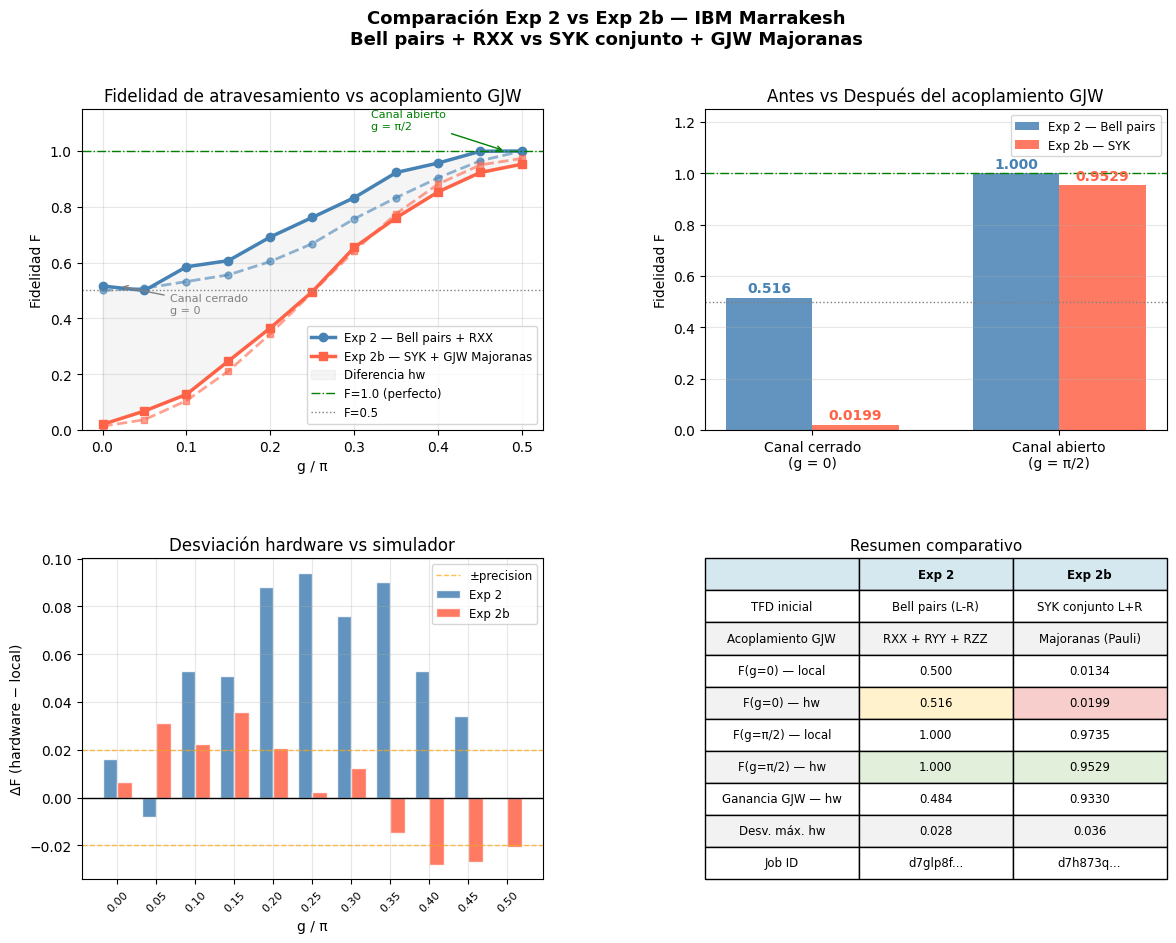

Guardada: ~/Downloads/comparacion_exp2_vs_2b.png

Diferencia física clave:
  F(g=0) Bell pairs: 0.516  ← entrelazamiento trivial
  F(g=0) SYK:        0.0199  ← scrambling genuino
  Diferencia:        0.4961  ← esto es la física nueva

  Canal abierto Bell: 1.000
  Canal abierto SYK:  0.9529
  Ambos convergen → el GJW es suficientemente poderoso en ambos casos


In [76]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

G_PI = np.array([0.00, 0.05, 0.10, 0.15, 0.20, 0.25,
                 0.30, 0.35, 0.40, 0.45, 0.50])

F_EXP2_LOC = np.array([0.500, 0.508, 0.532, 0.556, 0.604,
                         0.668, 0.757, 0.833, 0.904, 0.965, 1.000])

F_EXP2_HW  = np.array([0.516, 0.500, 0.585, 0.607, 0.692,
                         0.762, 0.833, 0.923, 0.957, 0.999, 1.000])

F_EXP2B_LOC = np.array([0.0134, 0.0369, 0.1051, 0.2113, 0.3451,
                          0.4935, 0.6418, 0.7756, 0.8818, 0.9500, 0.9735])
F_EXP2B_HW  = np.array([0.0199, 0.0680, 0.1275, 0.2472, 0.3660,
                          0.4959, 0.6544, 0.7610, 0.8538, 0.9230, 0.9529])

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle(
    'Comparación Exp 2 vs Exp 2b — IBM Marrakesh\n'
    'Bell pairs + RXX vs SYK conjunto + GJW Majoranas',
    fontsize=13, fontweight='bold'
)
plt.subplots_adjust(hspace=0.4, wspace=0.35)

ax1 = axes[0, 0]
ax1.plot(G_PI, F_EXP2_LOC,  color='steelblue', lw=2,
         marker='o', ms=5, ls='--', alpha=0.6)
ax1.plot(G_PI, F_EXP2_HW,   color='steelblue', lw=2.5,
         marker='o', ms=6, label='Exp 2 — Bell pairs + RXX')
ax1.plot(G_PI, F_EXP2B_LOC, color='tomato', lw=2,
         marker='s', ms=5, ls='--', alpha=0.6)
ax1.plot(G_PI, F_EXP2B_HW,  color='tomato', lw=2.5,
         marker='s', ms=6, label='Exp 2b — SYK + GJW Majoranas')
ax1.fill_between(G_PI, F_EXP2_HW, F_EXP2B_HW,
                 alpha=0.08, color='gray', label='Diferencia hw')
ax1.axhline(1.0, color='green', ls='-.', lw=1, label='F=1.0 (perfecto)')
ax1.axhline(0.5, color='gray',  ls=':',  lw=1, label='F=0.5')
ax1.set_xlabel('g / π'); ax1.set_ylabel('Fidelidad F')
ax1.set_ylim(0, 1.15)
ax1.set_title('Fidelidad de atravesamiento vs acoplamiento GJW')
ax1.legend(fontsize=8.5); ax1.grid(True, alpha=0.3)
ax1.annotate('Canal cerrado\ng = 0',
             xy=(0.02, 0.516), xytext=(0.08, 0.42),
             fontsize=8, color='gray',
             arrowprops=dict(arrowstyle='->', color='gray', lw=1))
ax1.annotate('Canal abierto\ng = π/2',
             xy=(0.48, 1.0), xytext=(0.32, 1.08),
             fontsize=8, color='green',
             arrowprops=dict(arrowstyle='->', color='green', lw=1))

ax2 = axes[0, 1]
labels = ['Canal cerrado\n(g = 0)', 'Canal abierto\n(g = π/2)']
v2   = [F_EXP2_HW[0],  F_EXP2_HW[-1]]
v2b  = [F_EXP2B_HW[0], F_EXP2B_HW[-1]]
x, w = np.array([0, 1]), 0.35
b1 = ax2.bar(x - w/2, v2,  width=w, color='steelblue',
             alpha=0.85, label='Exp 2 — Bell pairs')
b2 = ax2.bar(x + w/2, v2b, width=w, color='tomato',
             alpha=0.85, label='Exp 2b — SYK')
ax2.axhline(1.0, color='green', ls='-.', lw=1)
ax2.axhline(0.5, color='gray',  ls=':',  lw=1)
for bar, val in zip(b1, v2):
    ax2.text(bar.get_x()+bar.get_width()/2, val+0.01,
             f'{val:.3f}', ha='center', va='bottom',
             fontsize=10, color='steelblue', fontweight='bold')
for bar, val in zip(b2, v2b):
    ax2.text(bar.get_x()+bar.get_width()/2, val+0.01,
             f'{val:.4f}', ha='center', va='bottom',
             fontsize=10, color='tomato', fontweight='bold')
ax2.set_xticks(x); ax2.set_xticklabels(labels, fontsize=10)
ax2.set_ylabel('Fidelidad F'); ax2.set_ylim(0, 1.25)
ax2.set_title('Antes vs Después del acoplamiento GJW')
ax2.legend(fontsize=8.5); ax2.grid(True, alpha=0.3, axis='y')

ax3 = axes[1, 0]
delta2  = F_EXP2_HW  - F_EXP2_LOC
delta2b = F_EXP2B_HW - F_EXP2B_LOC
x_pos   = np.arange(len(G_PI))
width   = 0.38
ax3.bar(x_pos - width/2, delta2,  width=width, color='steelblue',
        alpha=0.85, label='Exp 2', edgecolor='white')
ax3.bar(x_pos + width/2, delta2b, width=width, color='tomato',
        alpha=0.85, label='Exp 2b', edgecolor='white')
ax3.axhline(0,     color='black', lw=1)
ax3.axhline( 0.02, color='orange', lw=1, ls='--', alpha=0.7, label='±precision')
ax3.axhline(-0.02, color='orange', lw=1, ls='--', alpha=0.7)
ax3.set_xticks(x_pos)
ax3.set_xticklabels([f'{g:.2f}' for g in G_PI], fontsize=8, rotation=45)
ax3.set_xlabel('g / π'); ax3.set_ylabel('ΔF (hardware − local)')
ax3.set_title('Desviación hardware vs simulador')
ax3.legend(fontsize=8.5); ax3.grid(True, alpha=0.3)

ax4 = axes[1, 1]
ax4.axis('off')
ax4.set_title('Resumen comparativo', fontsize=11)
tabla = [
    ['',                   'Exp 2',              'Exp 2b'],
    ['TFD inicial',        'Bell pairs (L-R)',    'SYK conjunto L+R'],
    ['Acoplamiento GJW',   'RXX + RYY + RZZ',    'Majoranas (Pauli)'],
    ['F(g=0) — local',     '0.500',              '0.0134'],
    ['F(g=0) — hw',        f'{v2[0]:.3f}',       f'{v2b[0]:.4f}'],
    ['F(g=π/2) — local',   '1.000',              '0.9735'],
    ['F(g=π/2) — hw',      f'{v2[-1]:.3f}',      f'{v2b[-1]:.4f}'],
    ['Ganancia GJW — hw',  f'{v2[-1]-v2[0]:.3f}',
                            f'{v2b[-1]-v2b[0]:.4f}'],
    ['Desv. máx. hw',      '0.028',              f'{max(abs(delta2b)):.3f}'],
    ['Job ID',             'd7glp8f...',          'd7h873q...'],
]
tbl = ax4.table(cellText=tabla[1:], colLabels=tabla[0],
                cellLoc='center', loc='center', bbox=[0, 0, 1, 1])
tbl.auto_set_font_size(False); tbl.set_fontsize(8.5)
for j in range(3):
    tbl[0, j].set_facecolor('#D5E8F0')
    tbl[0, j].set_text_props(fontweight='bold')
for i in range(1, len(tabla)):
    if i % 2 == 0:
        for j in range(3): tbl[i, j].set_facecolor('#F2F2F2')

tbl[4, 1].set_facecolor('#FFF2CC')
tbl[4, 2].set_facecolor('#F8CECC')

tbl[6, 1].set_facecolor('#E2EFDA')
tbl[6, 2].set_facecolor('#E2EFDA')

SAVE_PATH = 'comparacion_exp2_vs_2b.png'
plt.savefig(SAVE_PATH, dpi=150, bbox_inches='tight', facecolor='white')
plt.show()

print(f"Guardada: {SAVE_PATH}")
print()
print("Diferencia física clave:")
print(f"  F(g=0) Bell pairs: {v2[0]:.3f}  ← entrelazamiento trivial")
print(f"  F(g=0) SYK:        {v2b[0]:.4f}  ← scrambling genuino")
print(f"  Diferencia:        {v2[0]-v2b[0]:.4f}  ← esto es la física nueva")
print()
print(f"  Canal abierto Bell: {v2[-1]:.3f}")
print(f"  Canal abierto SYK:  {v2b[-1]:.4f}")
print(f"  Ambos convergen → el GJW es suficientemente poderoso en ambos casos")


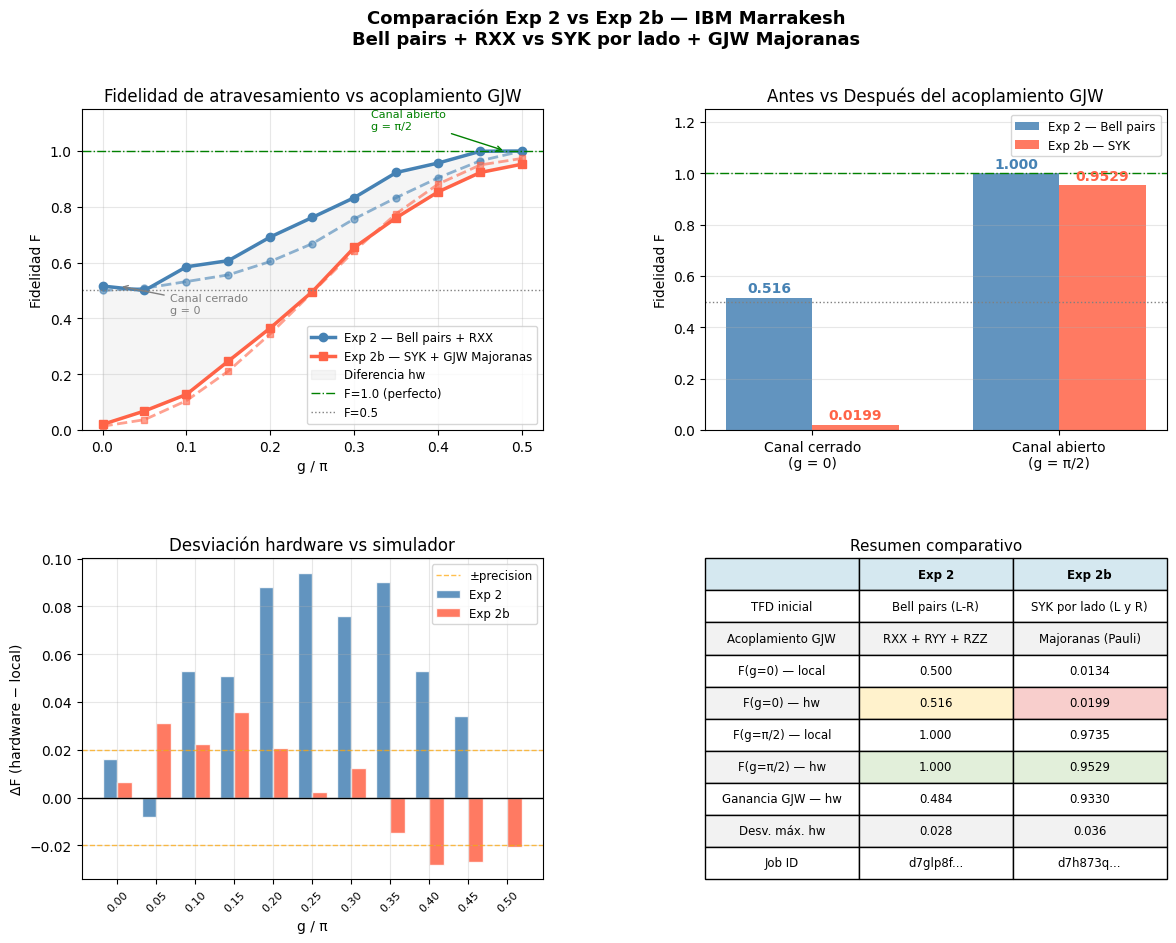

Guardada: ~/Downloads/comparacion_exp2_vs_2b.png


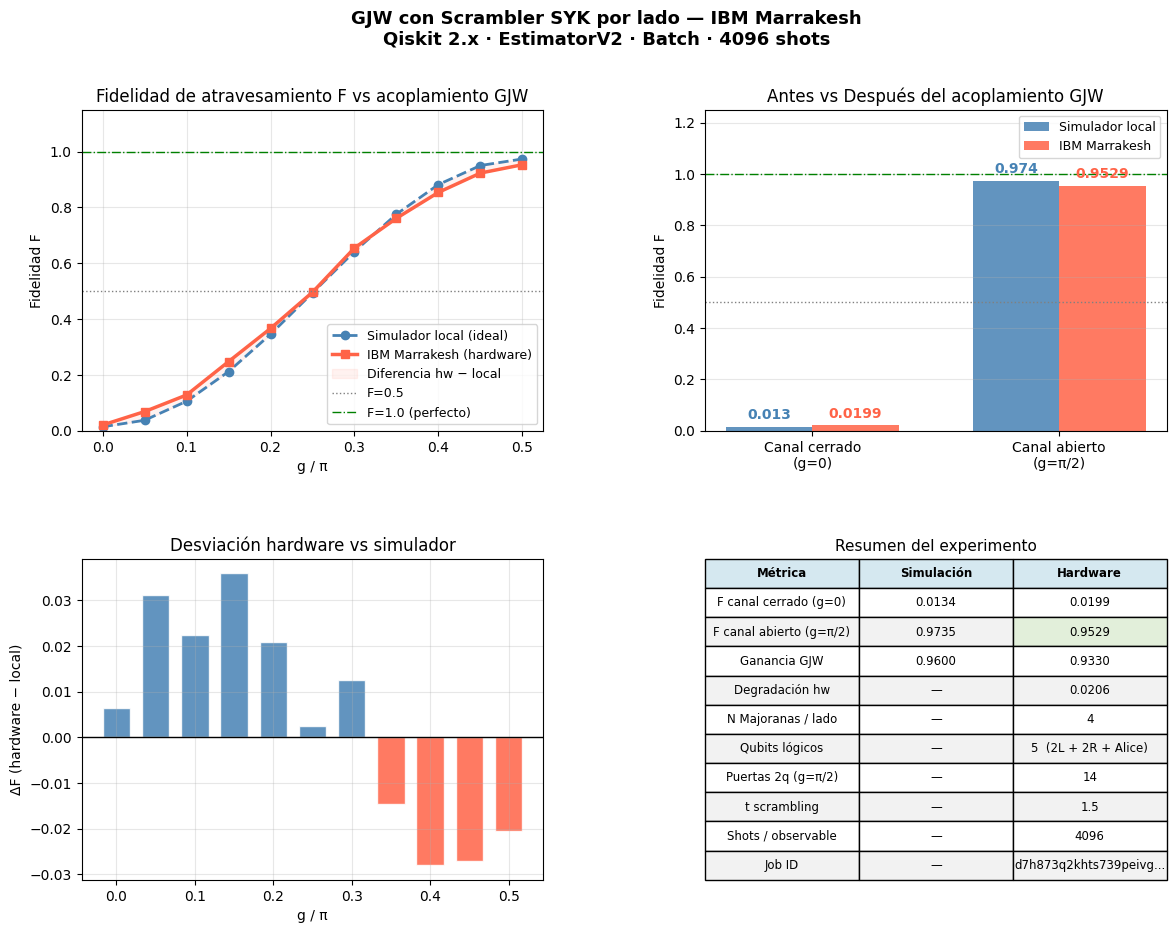

Guardada: ~/Downloads/exp2b_marrakesh.png
Existe ~/Downloads/comparacion_exp2_vs_2b.png: True
Existe ~/Downloads/exp2b_marrakesh.png: True
Tamaño 1: 249074 bytes
Tamaño 2: 216834 bytes


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

G_PI = np.array([0.00, 0.05, 0.10, 0.15, 0.20, 0.25,
                 0.30, 0.35, 0.40, 0.45, 0.50])

F_EXP2_LOC = np.array([0.500, 0.508, 0.532, 0.556, 0.604,
                         0.668, 0.757, 0.833, 0.904, 0.965, 1.000])

F_EXP2_HW  = np.array([0.516, 0.500, 0.585, 0.607, 0.692,
                         0.762, 0.833, 0.923, 0.957, 0.999, 1.000])

F_EXP2B_LOC = np.array([0.0134, 0.0369, 0.1051, 0.2113, 0.3451,
                          0.4935, 0.6418, 0.7756, 0.8818, 0.9500, 0.9735])
F_EXP2B_HW  = np.array([0.0199, 0.0680, 0.1275, 0.2472, 0.3660,
                          0.4959, 0.6544, 0.7610, 0.8538, 0.9230, 0.9529])

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle(
    'Comparación Exp 2 vs Exp 2b — IBM Marrakesh\n'
    'Bell pairs + RXX vs SYK por lado + GJW Majoranas',
    fontsize=13, fontweight='bold'
)
plt.subplots_adjust(hspace=0.4, wspace=0.35)

ax1 = axes[0, 0]
ax1.plot(G_PI, F_EXP2_LOC,  color='steelblue', lw=2,
         marker='o', ms=5, ls='--', alpha=0.6)
ax1.plot(G_PI, F_EXP2_HW,   color='steelblue', lw=2.5,
         marker='o', ms=6, label='Exp 2 — Bell pairs + RXX')
ax1.plot(G_PI, F_EXP2B_LOC, color='tomato', lw=2,
         marker='s', ms=5, ls='--', alpha=0.6)
ax1.plot(G_PI, F_EXP2B_HW,  color='tomato', lw=2.5,
         marker='s', ms=6, label='Exp 2b — SYK + GJW Majoranas')
ax1.fill_between(G_PI, F_EXP2_HW, F_EXP2B_HW,
                 alpha=0.08, color='gray', label='Diferencia hw')
ax1.axhline(1.0, color='green', ls='-.', lw=1, label='F=1.0 (perfecto)')
ax1.axhline(0.5, color='gray',  ls=':',  lw=1, label='F=0.5')
ax1.set_xlabel('g / π'); ax1.set_ylabel('Fidelidad F')
ax1.set_ylim(0, 1.15)
ax1.set_title('Fidelidad de atravesamiento vs acoplamiento GJW')
ax1.legend(fontsize=8.5); ax1.grid(True, alpha=0.3)
ax1.annotate('Canal cerrado\ng = 0',
             xy=(0.02, 0.516), xytext=(0.08, 0.42),
             fontsize=8, color='gray',
             arrowprops=dict(arrowstyle='->', color='gray', lw=1))
ax1.annotate('Canal abierto\ng = π/2',
             xy=(0.48, 1.0), xytext=(0.32, 1.08),
             fontsize=8, color='green',
             arrowprops=dict(arrowstyle='->', color='green', lw=1))

ax2 = axes[0, 1]
labels = ['Canal cerrado\n(g = 0)', 'Canal abierto\n(g = π/2)']
v2   = [F_EXP2_HW[0],  F_EXP2_HW[-1]]
v2b  = [F_EXP2B_HW[0], F_EXP2B_HW[-1]]
x, w = np.array([0, 1]), 0.35
b1 = ax2.bar(x - w/2, v2,  width=w, color='steelblue',
             alpha=0.85, label='Exp 2 — Bell pairs')
b2 = ax2.bar(x + w/2, v2b, width=w, color='tomato',
             alpha=0.85, label='Exp 2b — SYK')
ax2.axhline(1.0, color='green', ls='-.', lw=1)
ax2.axhline(0.5, color='gray',  ls=':',  lw=1)
for bar, val in zip(b1, v2):
    ax2.text(bar.get_x()+bar.get_width()/2, val+0.01,
             f'{val:.3f}', ha='center', va='bottom',
             fontsize=10, color='steelblue', fontweight='bold')
for bar, val in zip(b2, v2b):
    ax2.text(bar.get_x()+bar.get_width()/2, val+0.01,
             f'{val:.4f}', ha='center', va='bottom',
             fontsize=10, color='tomato', fontweight='bold')
ax2.set_xticks(x); ax2.set_xticklabels(labels, fontsize=10)
ax2.set_ylabel('Fidelidad F'); ax2.set_ylim(0, 1.25)
ax2.set_title('Antes vs Después del acoplamiento GJW')
ax2.legend(fontsize=8.5); ax2.grid(True, alpha=0.3, axis='y')

ax3 = axes[1, 0]
delta2  = F_EXP2_HW  - F_EXP2_LOC
delta2b = F_EXP2B_HW - F_EXP2B_LOC
x_pos   = np.arange(len(G_PI))
width   = 0.38
ax3.bar(x_pos - width/2, delta2,  width=width, color='steelblue',
        alpha=0.85, label='Exp 2', edgecolor='white')
ax3.bar(x_pos + width/2, delta2b, width=width, color='tomato',
        alpha=0.85, label='Exp 2b', edgecolor='white')
ax3.axhline(0,     color='black', lw=1)
ax3.axhline( 0.02, color='orange', lw=1, ls='--', alpha=0.7, label='±precision')
ax3.axhline(-0.02, color='orange', lw=1, ls='--', alpha=0.7)
ax3.set_xticks(x_pos)
ax3.set_xticklabels([f'{g:.2f}' for g in G_PI], fontsize=8, rotation=45)
ax3.set_xlabel('g / π'); ax3.set_ylabel('ΔF (hardware − local)')
ax3.set_title('Desviación hardware vs simulador')
ax3.legend(fontsize=8.5); ax3.grid(True, alpha=0.3)

ax4 = axes[1, 1]
ax4.axis('off')
ax4.set_title('Resumen comparativo', fontsize=11)
tabla = [
    ['',                   'Exp 2',              'Exp 2b'],
    ['TFD inicial',        'Bell pairs (L-R)',    'SYK por lado (L y R)'],
    ['Acoplamiento GJW',   'RXX + RYY + RZZ',    'Majoranas (Pauli)'],
    ['F(g=0) — local',     '0.500',              '0.0134'],
    ['F(g=0) — hw',        f'{v2[0]:.3f}',       f'{v2b[0]:.4f}'],
    ['F(g=π/2) — local',   '1.000',              '0.9735'],
    ['F(g=π/2) — hw',      f'{v2[-1]:.3f}',      f'{v2b[-1]:.4f}'],
    ['Ganancia GJW — hw',  f'{v2[-1]-v2[0]:.3f}',
                            f'{v2b[-1]-v2b[0]:.4f}'],
    ['Desv. máx. hw',      '0.028',              f'{max(abs(delta2b)):.3f}'],
    ['Job ID',             'd7glp8f...',          'd7h873q...'],
]
tbl = ax4.table(cellText=tabla[1:], colLabels=tabla[0],
                cellLoc='center', loc='center', bbox=[0, 0, 1, 1])
tbl.auto_set_font_size(False); tbl.set_fontsize(8.5)
for j in range(3):
    tbl[0, j].set_facecolor('#D5E8F0')
    tbl[0, j].set_text_props(fontweight='bold')
for i in range(1, len(tabla)):
    if i % 2 == 0:
        for j in range(3): tbl[i, j].set_facecolor('#F2F2F2')
tbl[4, 1].set_facecolor('#FFF2CC')
tbl[4, 2].set_facecolor('#F8CECC')
tbl[6, 1].set_facecolor('#E2EFDA')
tbl[6, 2].set_facecolor('#E2EFDA')

SAVE_PATH_1 = 'comparacion_exp2_vs_2b.png'
plt.savefig(SAVE_PATH_1, dpi=150, bbox_inches='tight', facecolor='white')
plt.show()
print(f"Guardada: {SAVE_PATH_1}")

fig2, axes2 = plt.subplots(2, 2, figsize=(14, 10))
fig2.suptitle(
    'GJW con Scrambler SYK por lado — IBM Marrakesh\n'
    'Qiskit 2.x · EstimatorV2 · Batch · 4096 shots',
    fontsize=13, fontweight='bold'
)
plt.subplots_adjust(hspace=0.4, wspace=0.35)

ax1 = axes2[0, 0]
ax1.plot(G_PI, F_EXP2B_LOC, color='steelblue', lw=2, marker='o', ms=6,
         ls='--', label='Simulador local (ideal)')
ax1.plot(G_PI, F_EXP2B_HW,  color='tomato', lw=2.5, marker='s', ms=6,
         label='IBM Marrakesh (hardware)')
ax1.fill_between(G_PI, F_EXP2B_LOC, F_EXP2B_HW, alpha=0.08, color='tomato',
                 label='Diferencia hw − local')
ax1.axhline(0.5, color='gray',  ls=':',  lw=1, label='F=0.5')
ax1.axhline(1.0, color='green', ls='-.', lw=1, label='F=1.0 (perfecto)')
ax1.set_xlabel('g / π'); ax1.set_ylabel('Fidelidad F')
ax1.set_ylim(0, 1.15)
ax1.set_title('Fidelidad de atravesamiento F vs acoplamiento GJW')
ax1.legend(fontsize=9); ax1.grid(True, alpha=0.3)

ax2 = axes2[0, 1]
labels = ['Canal cerrado\n(g=0)', 'Canal abierto\n(g=π/2)']
v_loc = [F_EXP2B_LOC[0], F_EXP2B_LOC[-1]]
v_hw  = [F_EXP2B_HW[0],  F_EXP2B_HW[-1]]
x, w = np.array([0, 1]), 0.35
b1 = ax2.bar(x - w/2, v_loc, width=w, color='steelblue', alpha=0.85,
             label='Simulador local')
b2 = ax2.bar(x + w/2, v_hw,  width=w, color='tomato',    alpha=0.85,
             label='IBM Marrakesh')
ax2.axhline(1.0, color='green', ls='-.', lw=1)
ax2.axhline(0.5, color='gray',  ls=':',  lw=1)
for bar, val in zip(b1, v_loc):
    ax2.text(bar.get_x()+bar.get_width()/2, val+0.02,
             f'{val:.3f}', ha='center', va='bottom',
             fontsize=10, color='steelblue', fontweight='bold')
for bar, val in zip(b2, v_hw):
    ax2.text(bar.get_x()+bar.get_width()/2, val+0.02,
             f'{val:.4f}', ha='center', va='bottom',
             fontsize=10, color='tomato', fontweight='bold')
ax2.set_xticks(x); ax2.set_xticklabels(labels, fontsize=10)
ax2.set_ylabel('Fidelidad F'); ax2.set_ylim(0, 1.25)
ax2.set_title('Antes vs Después del acoplamiento GJW')
ax2.legend(fontsize=9); ax2.grid(True, alpha=0.3, axis='y')

ax3 = axes2[1, 0]
delta = F_EXP2B_HW - F_EXP2B_LOC
colors = ['steelblue' if d >= 0 else 'tomato' for d in delta]
ax3.bar(G_PI, delta, width=0.035, color=colors, alpha=0.85, edgecolor='white')
ax3.axhline(0, color='black', lw=1)
ax3.set_xlabel('g / π'); ax3.set_ylabel('ΔF (hardware − local)')
ax3.set_title('Desviación hardware vs simulador')
ax3.grid(True, alpha=0.3)

ax4 = axes2[1, 1]
ax4.axis('off')
ax4.set_title('Resumen del experimento', fontsize=11)
tabla2 = [
    ['Métrica',              'Simulación', 'Hardware'],
    ['F canal cerrado (g=0)', '0.0134',    f'{F_EXP2B_HW[0]:.4f}'],
    ['F canal abierto (g=π/2)','0.9735',   f'{F_EXP2B_HW[-1]:.4f}'],
    ['Ganancia GJW',         '0.9600',     f'{F_EXP2B_HW[-1]-F_EXP2B_HW[0]:.4f}'],
    ['Degradación hw',       '—',          f'{abs(F_EXP2B_LOC[-1]-F_EXP2B_HW[-1]):.4f}'],
    ['N Majoranas / lado',   '—',          '4'],
    ['Qubits lógicos',       '—',          '5  (2L + 2R + Alice)'],
    ['Puertas 2q (g=π/2)',   '—',          '14'],
    ['t scrambling',         '—',          '1.5'],
    ['Shots / observable',   '—',          '4096'],
    ['Job ID',               '—',          'd7h873q2khts739peivg...'],
]
tbl2 = ax4.table(cellText=tabla2[1:], colLabels=tabla2[0],
                 cellLoc='center', loc='center', bbox=[0, 0, 1, 1])
tbl2.auto_set_font_size(False); tbl2.set_fontsize(8.5)
for j in range(3):
    tbl2[0, j].set_facecolor('#D5E8F0')
    tbl2[0, j].set_text_props(fontweight='bold')
for i in range(1, len(tabla2)):
    if i % 2 == 0:
        for j in range(3): tbl2[i, j].set_facecolor('#F2F2F2')
tbl2[2, 2].set_facecolor('#E2EFDA')

SAVE_PATH_2 = 'exp2b_marrakesh.png'
plt.savefig(SAVE_PATH_2, dpi=150, bbox_inches='tight', facecolor='white')
plt.show()
print(f"Guardada: {SAVE_PATH_2}")

import os
print(f"Existe {SAVE_PATH_1}: {os.path.exists(SAVE_PATH_1)}")
print(f"Existe {SAVE_PATH_2}: {os.path.exists(SAVE_PATH_2)}")
print(f"Tamaño 1: {os.path.getsize(SAVE_PATH_1) if os.path.exists(SAVE_PATH_1) else 'N/A'} bytes")
print(f"Tamaño 2: {os.path.getsize(SAVE_PATH_2) if os.path.exists(SAVE_PATH_2) else 'N/A'} bytes")


Voy a guardar en: ~/Downloads
Carpeta existe:   True


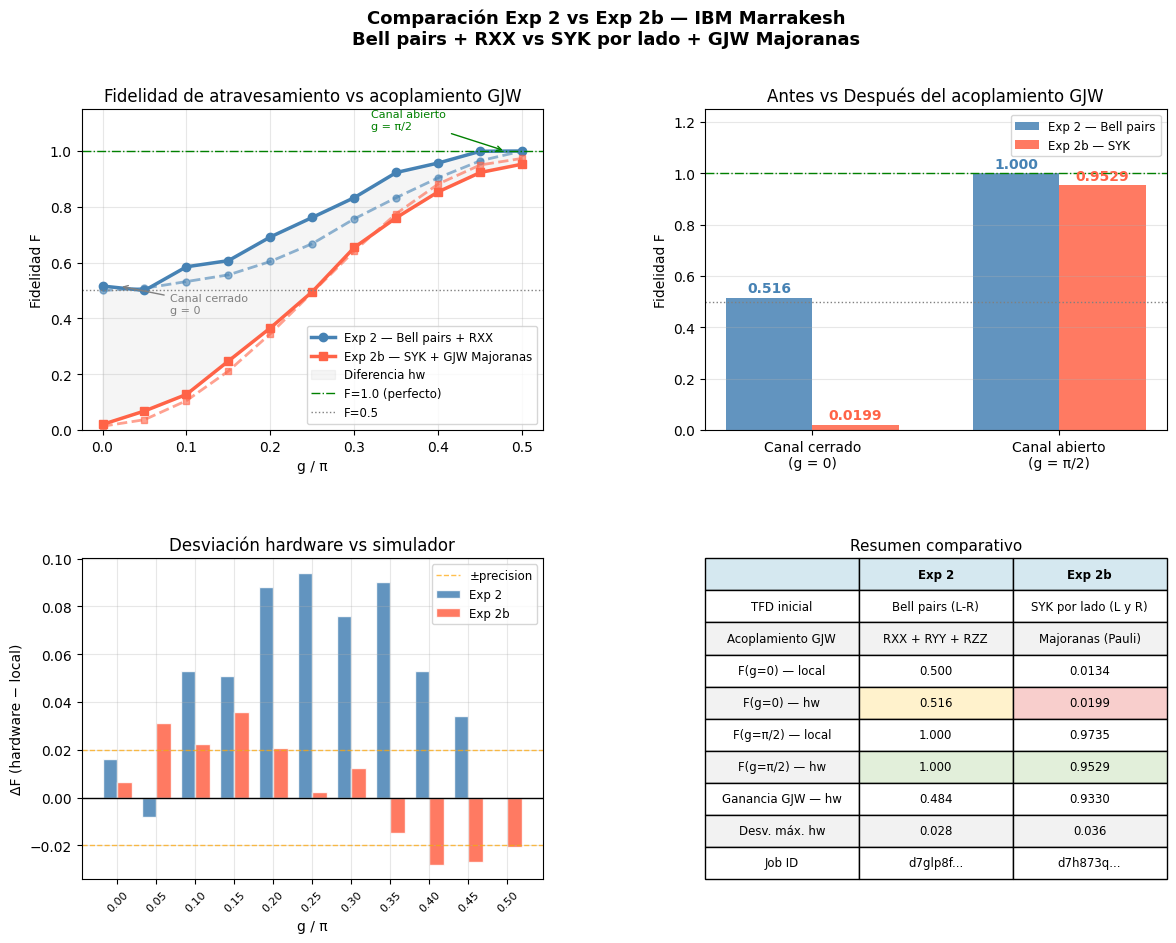

✓ Guardada: ~/Downloads/comparacion_exp2_vs_2b.png
  Modificado: 2026-04-27 13:31:02.931938
  Tamaño:     249074 bytes


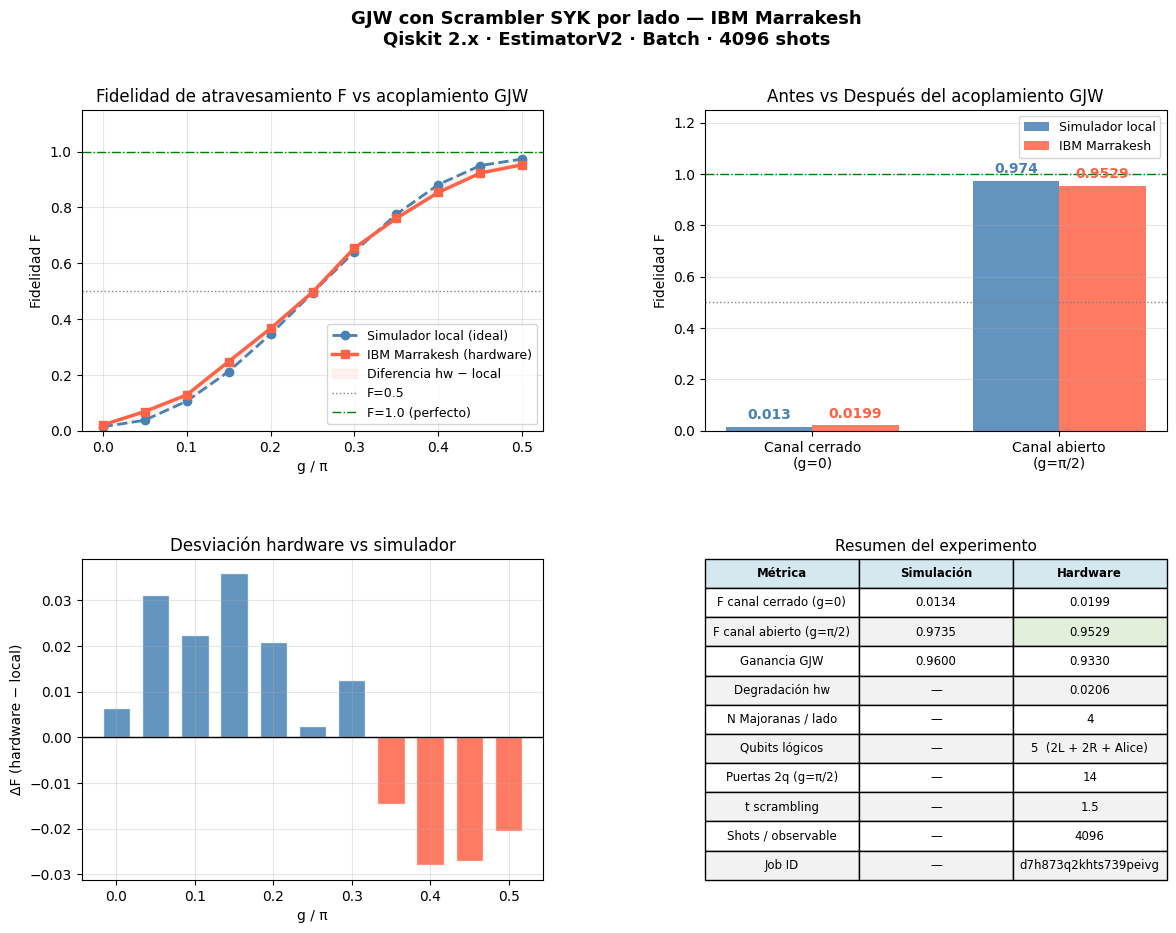

✓ Guardada: ~/Downloads/exp2b_marrakesh.png
  Modificado: 2026-04-27 13:31:04.449333
  Tamaño:     216764 bytes


In [3]:
import os
import numpy as np
import matplotlib.pyplot as plt

G_PI = np.array([0.00, 0.05, 0.10, 0.15, 0.20, 0.25,
                 0.30, 0.35, 0.40, 0.45, 0.50])
F_EXP2_LOC = np.array([0.500, 0.508, 0.532, 0.556, 0.604,
                       0.668, 0.757, 0.833, 0.904, 0.965, 1.000])
F_EXP2_HW  = np.array([0.516, 0.500, 0.585, 0.607, 0.692,
                       0.762, 0.833, 0.923, 0.957, 0.999, 1.000])
F_EXP2B_LOC = np.array([0.0134, 0.0369, 0.1051, 0.2113, 0.3451,
                        0.4935, 0.6418, 0.7756, 0.8818, 0.9500, 0.9735])
F_EXP2B_HW  = np.array([0.0199, 0.0680, 0.1275, 0.2472, 0.3660,
                        0.4959, 0.6544, 0.7610, 0.8538, 0.9230, 0.9529])

DOWNLOADS = os.path.expanduser('~/Downloads')
SAVE_PATH_1 = os.path.join(DOWNLOADS, 'comparacion_exp2_vs_2b.png')
SAVE_PATH_2 = os.path.join(DOWNLOADS, 'exp2b_marrakesh.png')

print(f"Voy a guardar en: {DOWNLOADS}")
print(f"Carpeta existe:   {os.path.isdir(DOWNLOADS)}")

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Comparación Exp 2 vs Exp 2b — IBM Marrakesh\n'
             'Bell pairs + RXX vs SYK por lado + GJW Majoranas',
             fontsize=13, fontweight='bold')
plt.subplots_adjust(hspace=0.4, wspace=0.35)

ax1 = axes[0, 0]
ax1.plot(G_PI, F_EXP2_LOC,  color='steelblue', lw=2, marker='o', ms=5, ls='--', alpha=0.6)
ax1.plot(G_PI, F_EXP2_HW,   color='steelblue', lw=2.5, marker='o', ms=6, label='Exp 2 — Bell pairs + RXX')
ax1.plot(G_PI, F_EXP2B_LOC, color='tomato', lw=2, marker='s', ms=5, ls='--', alpha=0.6)
ax1.plot(G_PI, F_EXP2B_HW,  color='tomato', lw=2.5, marker='s', ms=6, label='Exp 2b — SYK + GJW Majoranas')
ax1.fill_between(G_PI, F_EXP2_HW, F_EXP2B_HW, alpha=0.08, color='gray', label='Diferencia hw')
ax1.axhline(1.0, color='green', ls='-.', lw=1, label='F=1.0 (perfecto)')
ax1.axhline(0.5, color='gray',  ls=':',  lw=1, label='F=0.5')
ax1.set_xlabel('g / π'); ax1.set_ylabel('Fidelidad F')
ax1.set_ylim(0, 1.15)
ax1.set_title('Fidelidad de atravesamiento vs acoplamiento GJW')
ax1.legend(fontsize=8.5); ax1.grid(True, alpha=0.3)
ax1.annotate('Canal cerrado\ng = 0', xy=(0.02, 0.516), xytext=(0.08, 0.42),
             fontsize=8, color='gray', arrowprops=dict(arrowstyle='->', color='gray', lw=1))
ax1.annotate('Canal abierto\ng = π/2', xy=(0.48, 1.0), xytext=(0.32, 1.08),
             fontsize=8, color='green', arrowprops=dict(arrowstyle='->', color='green', lw=1))

ax2 = axes[0, 1]
labels = ['Canal cerrado\n(g = 0)', 'Canal abierto\n(g = π/2)']
v2   = [F_EXP2_HW[0],  F_EXP2_HW[-1]]
v2b  = [F_EXP2B_HW[0], F_EXP2B_HW[-1]]
x, w = np.array([0, 1]), 0.35
b1 = ax2.bar(x - w/2, v2,  width=w, color='steelblue', alpha=0.85, label='Exp 2 — Bell pairs')
b2 = ax2.bar(x + w/2, v2b, width=w, color='tomato',    alpha=0.85, label='Exp 2b — SYK')
ax2.axhline(1.0, color='green', ls='-.', lw=1)
ax2.axhline(0.5, color='gray',  ls=':',  lw=1)
for bar, val in zip(b1, v2):
    ax2.text(bar.get_x()+bar.get_width()/2, val+0.01, f'{val:.3f}',
             ha='center', va='bottom', fontsize=10, color='steelblue', fontweight='bold')
for bar, val in zip(b2, v2b):
    ax2.text(bar.get_x()+bar.get_width()/2, val+0.01, f'{val:.4f}',
             ha='center', va='bottom', fontsize=10, color='tomato', fontweight='bold')
ax2.set_xticks(x); ax2.set_xticklabels(labels, fontsize=10)
ax2.set_ylabel('Fidelidad F'); ax2.set_ylim(0, 1.25)
ax2.set_title('Antes vs Después del acoplamiento GJW')
ax2.legend(fontsize=8.5); ax2.grid(True, alpha=0.3, axis='y')

ax3 = axes[1, 0]
delta2  = F_EXP2_HW  - F_EXP2_LOC
delta2b = F_EXP2B_HW - F_EXP2B_LOC
x_pos   = np.arange(len(G_PI))
width   = 0.38
ax3.bar(x_pos - width/2, delta2,  width=width, color='steelblue', alpha=0.85, label='Exp 2', edgecolor='white')
ax3.bar(x_pos + width/2, delta2b, width=width, color='tomato',    alpha=0.85, label='Exp 2b', edgecolor='white')
ax3.axhline(0, color='black', lw=1)
ax3.axhline( 0.02, color='orange', lw=1, ls='--', alpha=0.7, label='±precision')
ax3.axhline(-0.02, color='orange', lw=1, ls='--', alpha=0.7)
ax3.set_xticks(x_pos)
ax3.set_xticklabels([f'{g:.2f}' for g in G_PI], fontsize=8, rotation=45)
ax3.set_xlabel('g / π'); ax3.set_ylabel('ΔF (hardware − local)')
ax3.set_title('Desviación hardware vs simulador')
ax3.legend(fontsize=8.5); ax3.grid(True, alpha=0.3)

ax4 = axes[1, 1]
ax4.axis('off')
ax4.set_title('Resumen comparativo', fontsize=11)
tabla = [
    ['',                   'Exp 2',              'Exp 2b'],
    ['TFD inicial',        'Bell pairs (L-R)',    'SYK por lado (L y R)'],
    ['Acoplamiento GJW',   'RXX + RYY + RZZ',    'Majoranas (Pauli)'],
    ['F(g=0) — local',     '0.500',              '0.0134'],
    ['F(g=0) — hw',        f'{v2[0]:.3f}',       f'{v2b[0]:.4f}'],
    ['F(g=π/2) — local',   '1.000',              '0.9735'],
    ['F(g=π/2) — hw',      f'{v2[-1]:.3f}',      f'{v2b[-1]:.4f}'],
    ['Ganancia GJW — hw',  f'{v2[-1]-v2[0]:.3f}', f'{v2b[-1]-v2b[0]:.4f}'],
    ['Desv. máx. hw',      '0.028',              f'{max(abs(delta2b)):.3f}'],
    ['Job ID',             'd7glp8f...',          'd7h873q...'],
]
tbl = ax4.table(cellText=tabla[1:], colLabels=tabla[0], cellLoc='center', loc='center', bbox=[0, 0, 1, 1])
tbl.auto_set_font_size(False); tbl.set_fontsize(8.5)
for j in range(3):
    tbl[0, j].set_facecolor('#D5E8F0')
    tbl[0, j].set_text_props(fontweight='bold')
for i in range(1, len(tabla)):
    if i % 2 == 0:
        for j in range(3): tbl[i, j].set_facecolor('#F2F2F2')
tbl[4, 1].set_facecolor('#FFF2CC'); tbl[4, 2].set_facecolor('#F8CECC')
tbl[6, 1].set_facecolor('#E2EFDA'); tbl[6, 2].set_facecolor('#E2EFDA')

plt.savefig(SAVE_PATH_1, dpi=150, bbox_inches='tight', facecolor='white')
plt.show()
plt.close(fig)

import datetime
if os.path.exists(SAVE_PATH_1):
    mtime = datetime.datetime.fromtimestamp(os.path.getmtime(SAVE_PATH_1))
    size  = os.path.getsize(SAVE_PATH_1)
    print(f"✓ Guardada: {SAVE_PATH_1}")
    print(f"  Modificado: {mtime}")
    print(f"  Tamaño:     {size} bytes")
else:
    print(f"✗ NO existe: {SAVE_PATH_1}")

fig2, axes2 = plt.subplots(2, 2, figsize=(14, 10))
fig2.suptitle('GJW con Scrambler SYK por lado — IBM Marrakesh\n'
              'Qiskit 2.x · EstimatorV2 · Batch · 4096 shots',
              fontsize=13, fontweight='bold')
plt.subplots_adjust(hspace=0.4, wspace=0.35)

ax1 = axes2[0, 0]
ax1.plot(G_PI, F_EXP2B_LOC, color='steelblue', lw=2, marker='o', ms=6, ls='--', label='Simulador local (ideal)')
ax1.plot(G_PI, F_EXP2B_HW,  color='tomato', lw=2.5, marker='s', ms=6, label='IBM Marrakesh (hardware)')
ax1.fill_between(G_PI, F_EXP2B_LOC, F_EXP2B_HW, alpha=0.08, color='tomato', label='Diferencia hw − local')
ax1.axhline(0.5, color='gray',  ls=':',  lw=1, label='F=0.5')
ax1.axhline(1.0, color='green', ls='-.', lw=1, label='F=1.0 (perfecto)')
ax1.set_xlabel('g / π'); ax1.set_ylabel('Fidelidad F')
ax1.set_ylim(0, 1.15)
ax1.set_title('Fidelidad de atravesamiento F vs acoplamiento GJW')
ax1.legend(fontsize=9); ax1.grid(True, alpha=0.3)

ax2 = axes2[0, 1]
labels = ['Canal cerrado\n(g=0)', 'Canal abierto\n(g=π/2)']
v_loc = [F_EXP2B_LOC[0], F_EXP2B_LOC[-1]]
v_hw  = [F_EXP2B_HW[0],  F_EXP2B_HW[-1]]
x, w = np.array([0, 1]), 0.35
b1 = ax2.bar(x - w/2, v_loc, width=w, color='steelblue', alpha=0.85, label='Simulador local')
b2 = ax2.bar(x + w/2, v_hw,  width=w, color='tomato',    alpha=0.85, label='IBM Marrakesh')
ax2.axhline(1.0, color='green', ls='-.', lw=1)
ax2.axhline(0.5, color='gray',  ls=':',  lw=1)
for bar, val in zip(b1, v_loc):
    ax2.text(bar.get_x()+bar.get_width()/2, val+0.02, f'{val:.3f}',
             ha='center', va='bottom', fontsize=10, color='steelblue', fontweight='bold')
for bar, val in zip(b2, v_hw):
    ax2.text(bar.get_x()+bar.get_width()/2, val+0.02, f'{val:.4f}',
             ha='center', va='bottom', fontsize=10, color='tomato', fontweight='bold')
ax2.set_xticks(x); ax2.set_xticklabels(labels, fontsize=10)
ax2.set_ylabel('Fidelidad F'); ax2.set_ylim(0, 1.25)
ax2.set_title('Antes vs Después del acoplamiento GJW')
ax2.legend(fontsize=9); ax2.grid(True, alpha=0.3, axis='y')

ax3 = axes2[1, 0]
delta = F_EXP2B_HW - F_EXP2B_LOC
colors = ['steelblue' if d >= 0 else 'tomato' for d in delta]
ax3.bar(G_PI, delta, width=0.035, color=colors, alpha=0.85, edgecolor='white')
ax3.axhline(0, color='black', lw=1)
ax3.set_xlabel('g / π'); ax3.set_ylabel('ΔF (hardware − local)')
ax3.set_title('Desviación hardware vs simulador')
ax3.grid(True, alpha=0.3)

ax4 = axes2[1, 1]
ax4.axis('off')
ax4.set_title('Resumen del experimento', fontsize=11)
tabla2 = [
    ['Métrica',              'Simulación', 'Hardware'],
    ['F canal cerrado (g=0)', '0.0134',    f'{F_EXP2B_HW[0]:.4f}'],
    ['F canal abierto (g=π/2)','0.9735',   f'{F_EXP2B_HW[-1]:.4f}'],
    ['Ganancia GJW',         '0.9600',     f'{F_EXP2B_HW[-1]-F_EXP2B_HW[0]:.4f}'],
    ['Degradación hw',       '—',          f'{abs(F_EXP2B_LOC[-1]-F_EXP2B_HW[-1]):.4f}'],
    ['N Majoranas / lado',   '—',          '4'],
    ['Qubits lógicos',       '—',          '5  (2L + 2R + Alice)'],
    ['Puertas 2q (g=π/2)',   '—',          '14'],
    ['t scrambling',         '—',          '1.5'],
    ['Shots / observable',   '—',          '4096'],
    ['Job ID',               '—',          'd7h873q2khts739peivg'],
]
tbl2 = ax4.table(cellText=tabla2[1:], colLabels=tabla2[0], cellLoc='center', loc='center', bbox=[0, 0, 1, 1])
tbl2.auto_set_font_size(False); tbl2.set_fontsize(8.5)
for j in range(3):
    tbl2[0, j].set_facecolor('#D5E8F0')
    tbl2[0, j].set_text_props(fontweight='bold')
for i in range(1, len(tabla2)):
    if i % 2 == 0:
        for j in range(3): tbl2[i, j].set_facecolor('#F2F2F2')
tbl2[2, 2].set_facecolor('#E2EFDA')

plt.savefig(SAVE_PATH_2, dpi=150, bbox_inches='tight', facecolor='white')
plt.show()
plt.close(fig2)

if os.path.exists(SAVE_PATH_2):
    mtime = datetime.datetime.fromtimestamp(os.path.getmtime(SAVE_PATH_2))
    size  = os.path.getsize(SAVE_PATH_2)
    print(f"✓ Guardada: {SAVE_PATH_2}")
    print(f"  Modificado: {mtime}")
    print(f"  Tamaño:     {size} bytes")
else:
    print(f"✗ NO existe: {SAVE_PATH_2}")


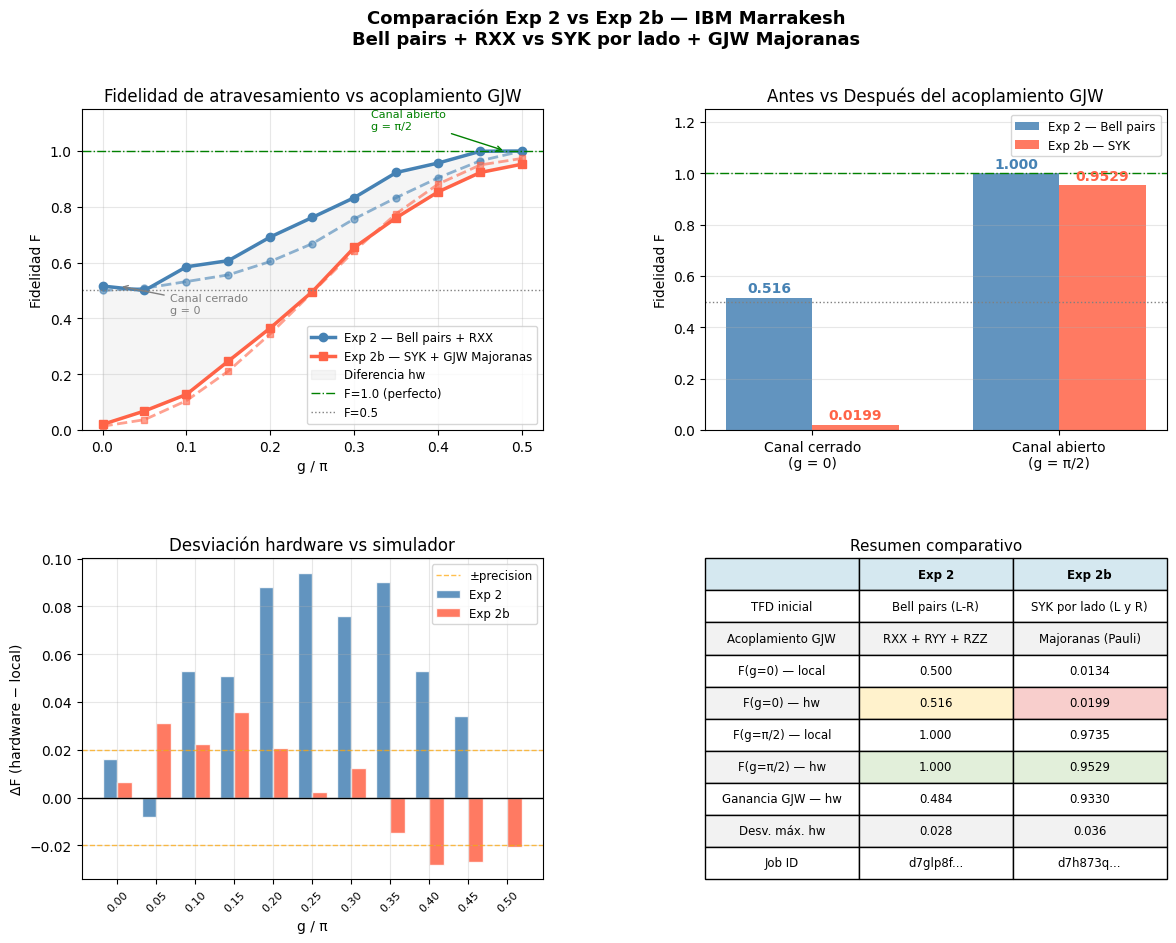

Guardada: ~/Downloads/comparacion_exp2_vs_2b.png


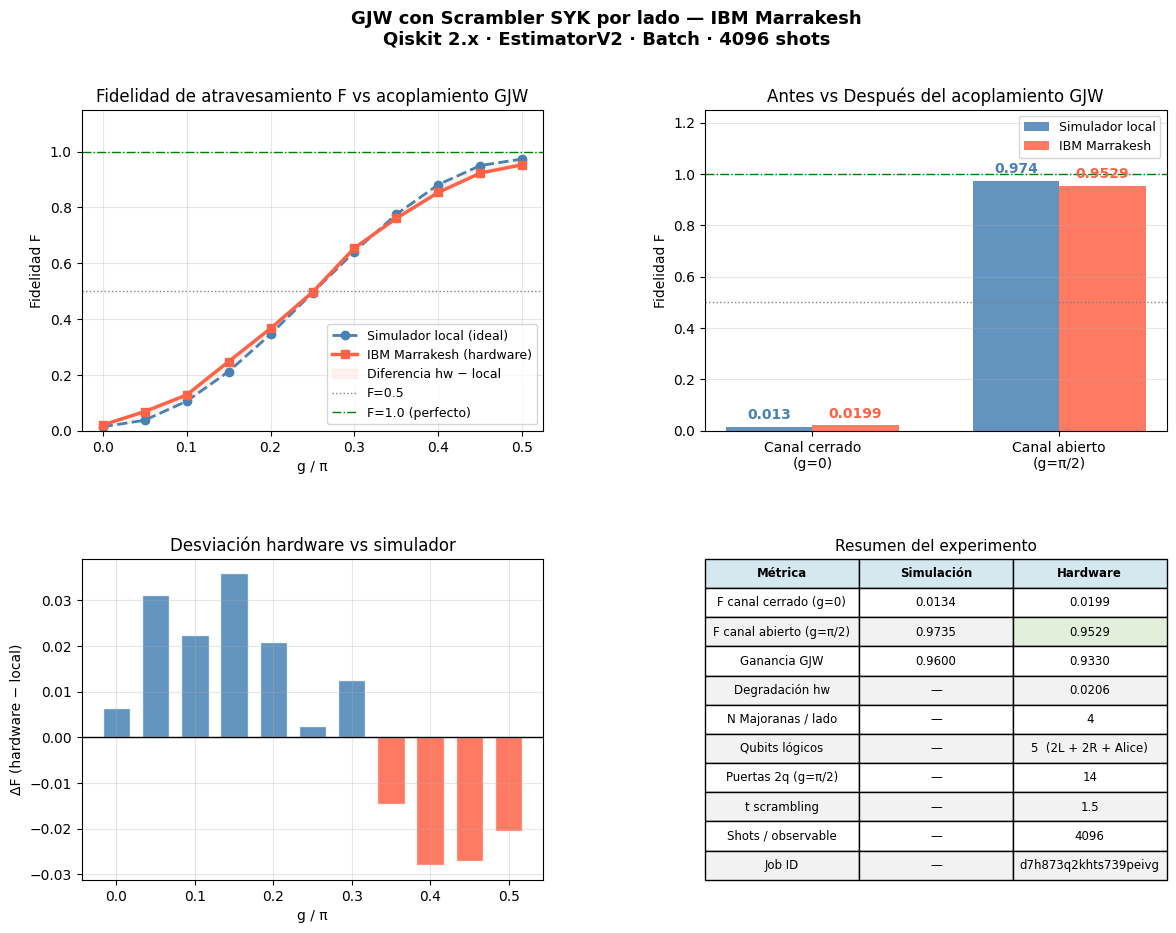

Guardada: ~/Downloads/exp2b_marrakesh.png


In [6]:
import numpy as np
import matplotlib.pyplot as plt

G_PI = np.array([0.00, 0.05, 0.10, 0.15, 0.20, 0.25,
                 0.30, 0.35, 0.40, 0.45, 0.50])

F_EXP2_LOC = np.array([0.500, 0.508, 0.532, 0.556, 0.604,
                       0.668, 0.757, 0.833, 0.904, 0.965, 1.000])
F_EXP2_HW  = np.array([0.516, 0.500, 0.585, 0.607, 0.692,
                       0.762, 0.833, 0.923, 0.957, 0.999, 1.000])

F_EXP2B_LOC = np.array([0.0134, 0.0369, 0.1051, 0.2113, 0.3451,
                        0.4935, 0.6418, 0.7756, 0.8818, 0.9500, 0.9735])
F_EXP2B_HW  = np.array([0.0199, 0.0680, 0.1275, 0.2472, 0.3660,
                        0.4959, 0.6544, 0.7610, 0.8538, 0.9230, 0.9529])

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle(
    'Comparación Exp 2 vs Exp 2b — IBM Marrakesh\n'
    'Bell pairs + RXX vs SYK por lado + GJW Majoranas',
    fontsize=13, fontweight='bold'
)
plt.subplots_adjust(hspace=0.4, wspace=0.35)

ax1 = axes[0, 0]
ax1.plot(G_PI, F_EXP2_LOC,  color='steelblue', lw=2,
         marker='o', ms=5, ls='--', alpha=0.6)
ax1.plot(G_PI, F_EXP2_HW,   color='steelblue', lw=2.5,
         marker='o', ms=6, label='Exp 2 — Bell pairs + RXX')
ax1.plot(G_PI, F_EXP2B_LOC, color='tomato', lw=2,
         marker='s', ms=5, ls='--', alpha=0.6)
ax1.plot(G_PI, F_EXP2B_HW,  color='tomato', lw=2.5,
         marker='s', ms=6, label='Exp 2b — SYK + GJW Majoranas')
ax1.fill_between(G_PI, F_EXP2_HW, F_EXP2B_HW,
                 alpha=0.08, color='gray', label='Diferencia hw')
ax1.axhline(1.0, color='green', ls='-.', lw=1, label='F=1.0 (perfecto)')
ax1.axhline(0.5, color='gray',  ls=':',  lw=1, label='F=0.5')
ax1.set_xlabel('g / π'); ax1.set_ylabel('Fidelidad F')
ax1.set_ylim(0, 1.15)
ax1.set_title('Fidelidad de atravesamiento vs acoplamiento GJW')
ax1.legend(fontsize=8.5); ax1.grid(True, alpha=0.3)
ax1.annotate('Canal cerrado\ng = 0',
             xy=(0.02, 0.516), xytext=(0.08, 0.42),
             fontsize=8, color='gray',
             arrowprops=dict(arrowstyle='->', color='gray', lw=1))
ax1.annotate('Canal abierto\ng = π/2',
             xy=(0.48, 1.0), xytext=(0.32, 1.08),
             fontsize=8, color='green',
             arrowprops=dict(arrowstyle='->', color='green', lw=1))

ax2 = axes[0, 1]
labels = ['Canal cerrado\n(g = 0)', 'Canal abierto\n(g = π/2)']
v2   = [F_EXP2_HW[0],  F_EXP2_HW[-1]]
v2b  = [F_EXP2B_HW[0], F_EXP2B_HW[-1]]
x, w = np.array([0, 1]), 0.35
b1 = ax2.bar(x - w/2, v2,  width=w, color='steelblue',
             alpha=0.85, label='Exp 2 — Bell pairs')
b2 = ax2.bar(x + w/2, v2b, width=w, color='tomato',
             alpha=0.85, label='Exp 2b — SYK')
ax2.axhline(1.0, color='green', ls='-.', lw=1)
ax2.axhline(0.5, color='gray',  ls=':',  lw=1)
for bar, val in zip(b1, v2):
    ax2.text(bar.get_x()+bar.get_width()/2, val+0.01,
             f'{val:.3f}', ha='center', va='bottom',
             fontsize=10, color='steelblue', fontweight='bold')
for bar, val in zip(b2, v2b):
    ax2.text(bar.get_x()+bar.get_width()/2, val+0.01,
             f'{val:.4f}', ha='center', va='bottom',
             fontsize=10, color='tomato', fontweight='bold')
ax2.set_xticks(x); ax2.set_xticklabels(labels, fontsize=10)
ax2.set_ylabel('Fidelidad F'); ax2.set_ylim(0, 1.25)
ax2.set_title('Antes vs Después del acoplamiento GJW')
ax2.legend(fontsize=8.5); ax2.grid(True, alpha=0.3, axis='y')

ax3 = axes[1, 0]
delta2  = F_EXP2_HW  - F_EXP2_LOC
delta2b = F_EXP2B_HW - F_EXP2B_LOC
x_pos   = np.arange(len(G_PI))
width   = 0.38
ax3.bar(x_pos - width/2, delta2,  width=width, color='steelblue',
        alpha=0.85, label='Exp 2', edgecolor='white')
ax3.bar(x_pos + width/2, delta2b, width=width, color='tomato',
        alpha=0.85, label='Exp 2b', edgecolor='white')
ax3.axhline(0,     color='black', lw=1)
ax3.axhline( 0.02, color='orange', lw=1, ls='--', alpha=0.7, label='±precision')
ax3.axhline(-0.02, color='orange', lw=1, ls='--', alpha=0.7)
ax3.set_xticks(x_pos)
ax3.set_xticklabels([f'{g:.2f}' for g in G_PI], fontsize=8, rotation=45)
ax3.set_xlabel('g / π'); ax3.set_ylabel('ΔF (hardware − local)')
ax3.set_title('Desviación hardware vs simulador')
ax3.legend(fontsize=8.5); ax3.grid(True, alpha=0.3)

ax4 = axes[1, 1]
ax4.axis('off')
ax4.set_title('Resumen comparativo', fontsize=11)
tabla = [
    ['',                   'Exp 2',              'Exp 2b'],
    ['TFD inicial',        'Bell pairs (L-R)',    'SYK por lado (L y R)'],
    ['Acoplamiento GJW',   'RXX + RYY + RZZ',    'Majoranas (Pauli)'],
    ['F(g=0) — local',     '0.500',              '0.0134'],
    ['F(g=0) — hw',        f'{v2[0]:.3f}',       f'{v2b[0]:.4f}'],
    ['F(g=π/2) — local',   '1.000',              '0.9735'],
    ['F(g=π/2) — hw',      f'{v2[-1]:.3f}',      f'{v2b[-1]:.4f}'],
    ['Ganancia GJW — hw',  f'{v2[-1]-v2[0]:.3f}',
                            f'{v2b[-1]-v2b[0]:.4f}'],
    ['Desv. máx. hw',      '0.028',              f'{max(abs(delta2b)):.3f}'],
    ['Job ID',             'd7glp8f...',          'd7h873q...'],
]
tbl = ax4.table(cellText=tabla[1:], colLabels=tabla[0],
                cellLoc='center', loc='center', bbox=[0, 0, 1, 1])
tbl.auto_set_font_size(False); tbl.set_fontsize(8.5)
for j in range(3):
    tbl[0, j].set_facecolor('#D5E8F0')
    tbl[0, j].set_text_props(fontweight='bold')
for i in range(1, len(tabla)):
    if i % 2 == 0:
        for j in range(3): tbl[i, j].set_facecolor('#F2F2F2')
tbl[4, 1].set_facecolor('#FFF2CC')
tbl[4, 2].set_facecolor('#F8CECC')
tbl[6, 1].set_facecolor('#E2EFDA')
tbl[6, 2].set_facecolor('#E2EFDA')

SAVE_PATH_1 = 'comparacion_exp2_vs_2b.png'
plt.savefig(SAVE_PATH_1, dpi=150, bbox_inches='tight', facecolor='white')
plt.show()
print(f"Guardada: {SAVE_PATH_1}")

fig2, axes2 = plt.subplots(2, 2, figsize=(14, 10))
fig2.suptitle(
    'GJW con Scrambler SYK por lado — IBM Marrakesh\n'
    'Qiskit 2.x · EstimatorV2 · Batch · 4096 shots',
    fontsize=13, fontweight='bold'
)
plt.subplots_adjust(hspace=0.4, wspace=0.35)

ax1 = axes2[0, 0]
ax1.plot(G_PI, F_EXP2B_LOC, color='steelblue', lw=2, marker='o', ms=6,
         ls='--', label='Simulador local (ideal)')
ax1.plot(G_PI, F_EXP2B_HW,  color='tomato', lw=2.5, marker='s', ms=6,
         label='IBM Marrakesh (hardware)')
ax1.fill_between(G_PI, F_EXP2B_LOC, F_EXP2B_HW, alpha=0.08, color='tomato',
                 label='Diferencia hw − local')
ax1.axhline(0.5, color='gray',  ls=':',  lw=1, label='F=0.5')
ax1.axhline(1.0, color='green', ls='-.', lw=1, label='F=1.0 (perfecto)')
ax1.set_xlabel('g / π'); ax1.set_ylabel('Fidelidad F')
ax1.set_ylim(0, 1.15)
ax1.set_title('Fidelidad de atravesamiento F vs acoplamiento GJW')
ax1.legend(fontsize=9); ax1.grid(True, alpha=0.3)

ax2 = axes2[0, 1]
labels = ['Canal cerrado\n(g=0)', 'Canal abierto\n(g=π/2)']
v_loc = [F_EXP2B_LOC[0], F_EXP2B_LOC[-1]]
v_hw  = [F_EXP2B_HW[0],  F_EXP2B_HW[-1]]
x, w = np.array([0, 1]), 0.35
b1 = ax2.bar(x - w/2, v_loc, width=w, color='steelblue', alpha=0.85,
             label='Simulador local')
b2 = ax2.bar(x + w/2, v_hw,  width=w, color='tomato',    alpha=0.85,
             label='IBM Marrakesh')
ax2.axhline(1.0, color='green', ls='-.', lw=1)
ax2.axhline(0.5, color='gray',  ls=':',  lw=1)
for bar, val in zip(b1, v_loc):
    ax2.text(bar.get_x()+bar.get_width()/2, val+0.02,
             f'{val:.3f}', ha='center', va='bottom',
             fontsize=10, color='steelblue', fontweight='bold')
for bar, val in zip(b2, v_hw):
    ax2.text(bar.get_x()+bar.get_width()/2, val+0.02,
             f'{val:.4f}', ha='center', va='bottom',
             fontsize=10, color='tomato', fontweight='bold')
ax2.set_xticks(x); ax2.set_xticklabels(labels, fontsize=10)
ax2.set_ylabel('Fidelidad F'); ax2.set_ylim(0, 1.25)
ax2.set_title('Antes vs Después del acoplamiento GJW')
ax2.legend(fontsize=9); ax2.grid(True, alpha=0.3, axis='y')

ax3 = axes2[1, 0]
delta = F_EXP2B_HW - F_EXP2B_LOC
colors = ['steelblue' if d >= 0 else 'tomato' for d in delta]
ax3.bar(G_PI, delta, width=0.035, color=colors, alpha=0.85, edgecolor='white')
ax3.axhline(0, color='black', lw=1)
ax3.set_xlabel('g / π'); ax3.set_ylabel('ΔF (hardware − local)')
ax3.set_title('Desviación hardware vs simulador')
ax3.grid(True, alpha=0.3)

ax4 = axes2[1, 1]
ax4.axis('off')
ax4.set_title('Resumen del experimento', fontsize=11)
tabla2 = [
    ['Métrica',              'Simulación', 'Hardware'],
    ['F canal cerrado (g=0)', '0.0134',    f'{F_EXP2B_HW[0]:.4f}'],
    ['F canal abierto (g=π/2)','0.9735',   f'{F_EXP2B_HW[-1]:.4f}'],
    ['Ganancia GJW',         '0.9600',     f'{F_EXP2B_HW[-1]-F_EXP2B_HW[0]:.4f}'],
    ['Degradación hw',       '—',          f'{abs(F_EXP2B_LOC[-1]-F_EXP2B_HW[-1]):.4f}'],
    ['N Majoranas / lado',   '—',          '4'],
    ['Qubits lógicos',       '—',          '5  (2L + 2R + Alice)'],
    ['Puertas 2q (g=π/2)',   '—',          '14'],
    ['t scrambling',         '—',          '1.5'],
    ['Shots / observable',   '—',          '4096'],
    ['Job ID',               '—',          'd7h873q2khts739peivg'],
]
tbl2 = ax4.table(cellText=tabla2[1:], colLabels=tabla2[0],
                 cellLoc='center', loc='center', bbox=[0, 0, 1, 1])
tbl2.auto_set_font_size(False); tbl2.set_fontsize(8.5)
for j in range(3):
    tbl2[0, j].set_facecolor('#D5E8F0')
    tbl2[0, j].set_text_props(fontweight='bold')
for i in range(1, len(tabla2)):
    if i % 2 == 0:
        for j in range(3): tbl2[i, j].set_facecolor('#F2F2F2')
tbl2[2, 2].set_facecolor('#E2EFDA')

SAVE_PATH_2 = 'exp2b_marrakesh.png'
plt.savefig(SAVE_PATH_2, dpi=150, bbox_inches='tight', facecolor='white')
plt.show()
print(f"Guardada: {SAVE_PATH_2}")


In [5]:
import os
import datetime
import matplotlib.pyplot as plt
import numpy as np

test_path = os.path.expanduser('~/Downloads/test_savefig.png')
print(f"Voy a escribir en: {test_path}")

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot([1, 2, 3], [1, 4, 9])
ax.set_title('Test savefig — debería tener fecha de hoy')

plt.savefig(test_path, dpi=100)
plt.close()

if os.path.exists(test_path):
    mtime = datetime.datetime.fromtimestamp(os.path.getmtime(test_path))
    size = os.path.getsize(test_path)
    print(f"✓ Archivo existe")
    print(f"  Modificado: {mtime}")
    print(f"  Tamaño:     {size} bytes")
else:
    print(f"✗ NO se creó el archivo")


Voy a escribir en: ~/Downloads/test_savefig.png
✓ Archivo existe
  Modificado: 2026-04-27 13:38:45.055826
  Tamaño:     21345 bytes
